<div style="background: linear-gradient(120deg, #FFFFFF, #DCECF6); border: 1px solid #DCECF6; border-radius: 16px; padding: 30px; margin-bottom: 20px;">
  <h1 style="color: #17324D; font-size: 36px; line-height: 1.3; margin: 0 0 14px;">
    NYC Motor Vehicle Collisions Analysis
  </h1>
  <p style="color: #62788C; font-size: 16px; line-height: 1.8; margin: 0;">
    An end-to-end data analysis project exploring motor vehicle collisions in New York City using Python, focusing on data quality, collision patterns, contributing factors, and injury severity.
  </p>
</div>

<div style="background:#FFFFFF;border:1px solid #DCECF6;border-left:5px solid #2584A6;border-radius:14px;padding:24px;margin:20px 0;color:#62788C;font-size:15px;line-height:2;">

<h3 style="color:#17324D;font-size:22px;margin:0 0 16px;">
        Report Navigation
    </h3>

   
<p style="margin:0;">
        <a href="#preparation" style="color:#2584A6;text-decoration:none;">01 Data Preparation & Cleaning</a>
        &nbsp; | &nbsp;
        <a href="#data-quality" style="color:#2584A6;text-decoration:none;">02 Data Quality Assessment</a>
        &nbsp; | &nbsp;
        <a href="#descriptive" style="color:#2584A6;text-decoration:none;">03 Descriptive Statistics</a>
        &nbsp; | &nbsp;
        <a href="#eda" style="color:#2584A6;text-decoration:none;">04 Exploratory Data Analysis</a>
        &nbsp; | &nbsp;
        <a href="#correlation" style="color:#2584A6;text-decoration:none;">05 Correlation Analysis</a>
        &nbsp; | &nbsp;
        <a href="#hypothesis" style="color:#2584A6;text-decoration:none;">06 Hypothesis Testing</a>
        &nbsp; | &nbsp;
               <a href="#conclusion" style="color:#2584A6;text-decoration:none;">08 Overall Statistical Conclusion</a>
    </p>

</div>

<div style="background:linear-gradient(120deg,#FFFFFF,#DCECF6);border:1px solid #DCECF6;border-left:6px solid #17324D;border-radius:16px;padding:26px 30px;margin:20px 0;">

<h2 style="color:#17324D;font-size:25px;margin:0 0 14px;">Executive Summary</h2>

<p style="color:#62788C;font-size:15px;line-height:1.9;margin:0 0 14px;">
This project presents an exploratory and statistical analysis of New York City Motor Vehicle Collisions data. The analysis aims to identify collision patterns, examine factors associated with injury involvement, and explore how collisions vary across locations, time periods, and road users.
</p>

<div style="background:#FFFFFF;border-radius:12px;padding:16px 20px;margin:12px 0;">
<h3 style="color:#2584A6;margin:0 0 8px;">Project Scope</h3>
<p style="color:#17324D;margin:0;line-height:1.8;">
The study uses a dataset containing approximately <b>1 million collision records</b>. It covers collision dates, times, geographic locations, contributing factors, vehicle information, and reported injuries and fatalities.
</p>
</div>

<div style="background:#FFFFFF;border-radius:12px;padding:16px 20px;margin:12px 0;">
<h3 style="color:#2584A6;margin:0 0 8px;">Methodology</h3>
<p style="color:#17324D;margin:0;line-height:1.8;">
The project follows a structured analytical process, including data preparation, data quality assessment, descriptive statistics, exploratory data analysis (EDA), correlation analysis, and hypothesis testing. Python libraries were used to clean, process, analyze, and visualize the data.
</p>
</div>

<div style="background:#FFFFFF;border-radius:12px;padding:16px 20px;margin:12px 0;">
<h3 style="color:#2584A6;margin:0 0 8px;">Key Findings</h3>
<p style="color:#17324D;margin:0;line-height:1.8;">
The exploratory analysis identified variations in collision patterns across days, hours, months, boroughs, and road-user groups. Motorists accounted for the largest number of injuries, while pedestrians recorded the highest number of fatalities among the analyzed road-user groups. Statistical testing also identified an association between borough and injury involvement, although the measured effect was very weak.
</p>
</div>

<div style="background:#DCECF6;border-left:5px solid #E4AF56;border-radius:12px;padding:18px 20px;margin-top:20px;">
<h3 style="color:#17324D;margin:0 0 8px;">Project Objective</h3>
<p style="color:#17324D;margin:0;line-height:1.8;">
The findings provide a data-driven overview of motor vehicle collision patterns in New York City and help identify areas and conditions that deserve further attention when studying traffic safety.
</p>
</div>

</div>

<div style="background: linear-gradient(120deg, #FFFFFF, #DCECF6); border: 1px solid #DCECF6; border-left: 6px solid #17324D; border-radius: 16px; padding: 26px 30px; margin: 28px 0 20px;">
    <h1 style="color: #17324D; font-size: 30px; margin: 0;">1. Environment Setup &amp; Data Loading</h1>
    <p style="color: #62788C; font-size: 15px; margin: 10px 0 0; line-height: 1.7;">
        Preparing the analysis environment, importing the required libraries, and loading the raw NYC Motor Vehicle Collisions dataset.
    </p>
</div>


<div style="background:#FFFFFF; border:1px solid #DCECF6; border-left:5px solid #2584A6; border-radius:14px; padding:24px; margin:20px 0; color:#62788C; font-size:15px; line-height:1.8;">
<h3 style="color:#17324D; font-size:22px; margin:0 0 12px;">1.1 Import Libraries</h3>
<p style="margin:0;">Import the libraries required for data manipulation, numerical calculations, visualization, geographical processing, and statistical analysis. Configure the notebook display settings and establish a consistent visual theme for all analytical outputs.</p>
</div>


In [208]:
# Data manipulation and numerical calculations
import pandas as pd
import numpy as np

# Calendar names and month ordering
import calendar

# Charts, legends, and axis formatting
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter

# Display tables and HTML explanations in the notebook
from IPython.display import display, HTML

# Statistical models and adjusted comparisons
import statsmodels.formula.api as smf

# Statistical tests and rank correlation
from scipy.stats import chi2_contingency, spearmanr

# Geographic operations used in borough recovery
import geopandas as gpd

import base64
from pathlib import Path

<div style="background: #FFFFFF; border: 1px solid #DCECF6; border-left: 5px solid #2584A6; border-radius: 14px; padding: 22px 26px; margin: 20px 0;">
    <h2 style="color: #17324D; font-size: 22px; margin: 0 0 10px;">1.2 Load the Dataset</h2>
    <p style="color: #62788C; font-size: 15px; margin: 0; line-height: 1.8;">
        Load the original CSV file into a Pandas DataFrame named <b>crash</b>. The raw dataset will remain unchanged throughout the pre-cleaning exploration.
    </p>
</div>

In [209]:
crash = pd.read_csv('Raw Data 2018-2026.csv')

<div style="background: #FFFFFF; border: 1px solid #DCECF6; border-left: 5px solid #2584A6; border-radius: 14px; padding: 22px 26px; margin: 20px 0;">
    <h2 style="color: #17324D; font-size: 22px; margin: 0 0 10px;">1.3 Initial Dataset Overview</h2>
    <p style="color: #62788C; font-size: 15px; margin: 0; line-height: 1.8;">
        Examine the overall size of the dataset by identifying the total number of records and columns. This provides an initial understanding of the available data.
    </p>
</div>

In [210]:
# Dataset dimensions
rows, columns = crash.shape

print(f"Total Records: {rows:,}")
print(f"Total Columns: {columns:,}")

Total Records: 1,000,000
Total Columns: 29


In [211]:
# Memory usage
memory_usage = crash.memory_usage(deep=True).sum() / (1024 ** 2)

print(f"Dataset Memory Usage: {memory_usage:,.2f} MB")

Dataset Memory Usage: 946.07 MB


<div style="background: linear-gradient(120deg, #FFFFFF, #DCECF6); border: 1px solid #DCECF6; border-left: 6px solid #17324D; border-radius: 16px; padding: 26px 30px; margin: 32px 0 20px;">
    <h1 style="color: #17324D; font-size: 30px; margin: 0;">2. Pre-Cleaning Data Exploration</h1>
    <p style="color: #62788C; font-size: 15px; margin: 10px 0 0; line-height: 1.7;">
        Exploring the raw dataset before applying any cleaning operations. This section examines data structure, missing values, duplicates, data types, statistical distributions, and potential data quality issues.
    </p>
</div>

<div style="background: #FFFFFF; border: 1px solid #DCECF6; border-left: 5px solid #2584A6; border-radius: 14px; padding: 22px 26px; margin: 20px 0;">
    <h2 style="color: #17324D; font-size: 22px; margin: 0 0 10px;">2.1 Preview the Dataset</h2>
    <p style="color: #62788C; font-size: 15px; margin: 0; line-height: 1.8;">
        Inspect the first and last records to understand how the data is organized and identify any initial inconsistencies in the raw dataset.
    </p>
</div>

In [212]:
# First 5 records
crash.head()

,CRASH DATE,CRASH TIME,BOROUGH,ZIP CODE,LATITUDE,LONGITUDE,LOCATION,ON STREET NAME,CROSS STREET NAME,OFF STREET NAME,...,CONTRIBUTING FACTOR VEHICLE 2,CONTRIBUTING FACTOR VEHICLE 3,CONTRIBUTING FACTOR VEHICLE 4,CONTRIBUTING FACTOR VEHICLE 5,COLLISION_ID,VEHICLE TYPE CODE 1,VEHICLE TYPE CODE 2,VEHICLE TYPE CODE 3,VEHICLE TYPE CODE 4,VEHICLE TYPE CODE 5
0,11/06/2026,17:31,QUEENS,NaN,40.753273,-73.850160,"(40.753273, -73.85016)",ROOSEVELT AVE,NaN,STADIUM PL N,...,Does Not Apply,Does Not Apply,NaN,NaN,8dc30c9e90494a67ddfb6a107ec8a3df,Station Wagon/Sport Utility Vehicle,4 dr sedan,Station Wagon/Sport Utility Vehicle,NaN,NaN
1,11/06/2026,19:45,QUEENS,11364.0,40.747330,-73.755800,"(40.74733, -73.7558)",SPRINGFIELD BLVD,NaN,64 AVE,...,Failure to Yield Right-of-Way,NaN,NaN,NaN,21f17295fd767bc0614208b693687ed1,Station Wagon/Sport Utility Vehicle,4 dr sedan,NaN,NaN,NaN
2,11/06/2026,06:17,BROOKLYN,NaN,40.655983,-73.897570,"(40.655983, -73.89757)",DE WITT AVE,NaN,NaN,...,Traffic Control Disregarded,NaN,NaN,NaN,f7d790c29805ddd52a44cccb42a3a0af,Station Wagon/Sport Utility Vehicle,NaN,NaN,NaN,NaN
3,11/06/2026,14:34,MANHATTAN,10002.0,40.719833,-73.987236,"(40.719833, -73.987236)",NaN,120 RIVINGTON ST,NaN,...,Failure to Yield Right-of-Way,NaN,NaN,NaN,9aad1ffda4395eb9d8cfdd893188a555,Station Wagon/Sport Utility Vehicle,4 dr sedan,NaN,NaN,NaN
4,11/06/2026,21:00,QUEENS,NaN,40.708637,-73.904110,"(40.708637, -73.90411)",LINDEN ST,NaN,FOREST AVE,...,NaN,NaN,NaN,NaN,ccee9345d34e526947d815f3a099b776,4 dr sedan,NaN,NaN,NaN,NaN


In [213]:
# Last 5 records
crash.tail()

,CRASH DATE,CRASH TIME,BOROUGH,ZIP CODE,LATITUDE,LONGITUDE,LOCATION,ON STREET NAME,CROSS STREET NAME,OFF STREET NAME,...,CONTRIBUTING FACTOR VEHICLE 2,CONTRIBUTING FACTOR VEHICLE 3,CONTRIBUTING FACTOR VEHICLE 4,CONTRIBUTING FACTOR VEHICLE 5,COLLISION_ID,VEHICLE TYPE CODE 1,VEHICLE TYPE CODE 2,VEHICLE TYPE CODE 3,VEHICLE TYPE CODE 4,VEHICLE TYPE CODE 5
999995,07/04/2018,03:51,MANHATTAN,10022.0,40.755756,-73.964790,"(40.755756, -73.96479)",1 AVENUE,NaN,EAST 53 STREET,...,Unspecified,NaN,NaN,NaN,653df6370320e244908c313e672055e7,Station Wagon/Sport Utility Vehicle,Bike,NaN,NaN,NaN
999996,07/04/2018,06:56,QUEENS,11368.0,40.742110,-73.855800,"(40.74211, -73.8558)",NaN,105-17 53 AVENUE,NaN,...,Unspecified,NaN,NaN,NaN,7f4b4b05ee94f228482859ed63279883,Sedan,Station Wagon/Sport Utility Vehicle,NaN,NaN,NaN
999997,07/04/2018,08:00,NaN,NaN,40.822834,-73.941925,"(40.822834, -73.941925)",WEST 145 STREET,NaN,NaN,...,Unspecified,NaN,NaN,NaN,41e08f27e155a7072f7ff5df7704e052,Station Wagon/Sport Utility Vehicle,NaN,NaN,NaN,NaN
999998,07/04/2018,11:00,BROOKLYN,11226.0,40.642770,-73.956430,"(40.64277, -73.95643)",EAST 22 STREET,NaN,CLARENDON ROAD,...,Unspecified,NaN,NaN,NaN,4e39afa80baaa6f8fad51651ef8b4b51,Sedan,NaN,NaN,NaN,NaN
999999,07/04/2018,17:15,MANHATTAN,10035.0,40.789050,-73.927230,"(40.78905, -73.92723)",NaN,600 EAST 125 STREET,NaN,...,Unspecified,NaN,NaN,NaN,ae2d7d2d7b667ec15d20e9214c1a281c,Station Wagon/Sport Utility Vehicle,Sedan,NaN,NaN,NaN


In [214]:
# Random sample of 5 records
display(crash.sample(5, random_state=42))

,CRASH DATE,CRASH TIME,BOROUGH,ZIP CODE,LATITUDE,LONGITUDE,LOCATION,ON STREET NAME,CROSS STREET NAME,OFF STREET NAME,...,CONTRIBUTING FACTOR VEHICLE 2,CONTRIBUTING FACTOR VEHICLE 3,CONTRIBUTING FACTOR VEHICLE 4,CONTRIBUTING FACTOR VEHICLE 5,COLLISION_ID,VEHICLE TYPE CODE 1,VEHICLE TYPE CODE 2,VEHICLE TYPE CODE 3,VEHICLE TYPE CODE 4,VEHICLE TYPE CODE 5
987231,07/24/2018,17:10,MANHATTAN,10038.0,40.706787,-74.00512,"(40.706787, -74.00512)",NaN,180 WATER STREET,NaN,...,Unspecified,NaN,NaN,NaN,de59dbcd1a36272d3d949b749ccc633f,Station Wagon/Sport Utility Vehicle,Sedan,NaN,NaN,NaN
79954,11/25/2025,17:55,QUEENS,NaN,40.730850,-73.89145,"(40.73085, -73.89145)",53 RD,NaN,72 PL,...,NaN,NaN,NaN,NaN,31198f156a03911b4d13954a49a8c95b,NaN,NaN,NaN,NaN,NaN
567130,12/03/2020,14:58,BROOKLYN,11235.0,40.587418,-73.95936,"(40.587418, -73.95936)",EAST 11 STREET,NaN,AVENUE Z,...,Unspecified,NaN,NaN,NaN,2d079868d654827559823cc6e69a2f40,Sedan,Station Wagon/Sport Utility Vehicle,NaN,NaN,NaN
500891,07/19/2021,03:20,NaN,NaN,40.739370,-73.79189,"(40.73937, -73.79189)",LONG ISLAND EXPRESSWAY,NaN,NaN,...,Unspecified,NaN,NaN,NaN,5030ae7c2ba6dfdc82a79df8e6b41c28,Sedan,Station Wagon/Sport Utility Vehicle,NaN,NaN,NaN
55399,03/13/2026,06:00,BROOKLYN,11204.0,40.615013,-73.99101,"(40.615013, -73.99101)",19 AVE,NaN,70 ST,...,Does Not Apply,NaN,NaN,NaN,9a4cac3b8902417ac175c2b4eb426878,Station Wagon/Sport Utility Vehicle,Standing Scooter,NaN,NaN,NaN


<div style="background: #FFFFFF; border: 1px solid #DCECF6; border-left: 5px solid #2584A6; border-radius: 14px; padding: 22px 26px; margin: 20px 0;">
    <h2 style="color: #17324D; font-size: 22px; margin: 0 0 10px;">2.2 Dataset Structure &amp; Column Information</h2>
    <p style="color: #62788C; font-size: 15px; margin: 0; line-height: 1.8;">
        Examine the dataset structure, column names, non-null counts, and data types to understand the variables available for analysis.
    </p>
</div>

In [215]:
# Detailed column summary
column_summary = pd.DataFrame({
    'Column': crash.columns,
    'Data Type': crash.dtypes.astype(str).values,
    'Non-Null Count': crash.notnull().sum().values,
    'Missing Values': crash.isnull().sum().values,
    'Unique Values': crash.nunique().values
})

display(column_summary)

,Column,Data Type,Non-Null Count,Missing Values,Unique Values
0,CRASH DATE,object,1000000,0,3048
1,CRASH TIME,object,1000000,0,1440
2,BOROUGH,object,705230,294770,5
3,ZIP CODE,float64,679775,320225,231
4,LATITUDE,float64,932047,67953,83171
5,LONGITUDE,float64,932047,67953,55223
6,LOCATION,object,932047,67953,249565
7,ON STREET NAME,object,731672,268328,13664
8,CROSS STREET NAME,object,268106,731894,180772
9,OFF STREET NAME,object,498002,501998,15554


<div style="background: #FFFFFF; border: 1px solid #DCECF6; border-left: 5px solid #2584A6; border-radius: 14px; padding: 22px 26px; margin: 20px 0;">
    <h2 style="color: #17324D; font-size: 22px; margin: 0 0 10px;">2.3 Data Types Inspection</h2>
    <p style="color: #62788C; font-size: 15px; margin: 0; line-height: 1.8;">
        Review the distribution of data types across the dataset and identify columns that may require data type conversion during the cleaning process.
    </p>
</div>

In [216]:
# Count columns by data type
dtype_summary = (
    crash.dtypes.astype(str)
    .value_counts()
    .rename_axis('Data Type')
    .reset_index(name='Number of Columns')
)

display(dtype_summary)

,Data Type,Number of Columns
0,object,18
1,int64,6
2,float64,5


In [217]:
# Data type of each column
display(
    crash.dtypes.astype(str)
    .rename('Data Type')
    .to_frame()
)

,Data Type
CRASH DATE,object
CRASH TIME,object
BOROUGH,object
ZIP CODE,float64
LATITUDE,float64
LONGITUDE,float64
LOCATION,object
ON STREET NAME,object
CROSS STREET NAME,object
OFF STREET NAME,object


In [218]:
# Separate columns by data type
numeric_columns = crash.select_dtypes(include=np.number).columns.tolist()

categorical_columns = crash.select_dtypes(
    include=['object', 'category', 'string']
).columns.tolist()

print("Numerical Columns:")
print(numeric_columns)

print("\nCategorical Columns:")
print(categorical_columns)

Numerical Columns:
['ZIP CODE', 'LATITUDE', 'LONGITUDE', 'NUMBER OF PERSONS INJURED', 'NUMBER OF PERSONS KILLED', 'NUMBER OF PEDESTRIANS INJURED', 'NUMBER OF PEDESTRIANS KILLED', 'NUMBER OF CYCLIST INJURED', 'NUMBER OF CYCLIST KILLED', 'NUMBER OF MOTORIST INJURED', 'NUMBER OF MOTORIST KILLED']

Categorical Columns:
['CRASH DATE', 'CRASH TIME', 'BOROUGH', 'LOCATION', 'ON STREET NAME', 'CROSS STREET NAME', 'OFF STREET NAME', 'CONTRIBUTING FACTOR VEHICLE 1', 'CONTRIBUTING FACTOR VEHICLE 2', 'CONTRIBUTING FACTOR VEHICLE 3', 'CONTRIBUTING FACTOR VEHICLE 4', 'CONTRIBUTING FACTOR VEHICLE 5', 'COLLISION_ID', 'VEHICLE TYPE CODE 1', 'VEHICLE TYPE CODE 2', 'VEHICLE TYPE CODE 3', 'VEHICLE TYPE CODE 4', 'VEHICLE TYPE CODE 5']


<div style="background: #FFFFFF; border: 1px solid #DCECF6; border-left: 5px solid #2584A6; border-radius: 14px; padding: 22px 26px; margin: 20px 0;">
    <h2 style="color: #17324D; font-size: 22px; margin: 0 0 10px;">2.4 Missing Values Analysis</h2>
    <p style="color: #62788C; font-size: 15px; margin: 0; line-height: 1.8;">
        Identify missing values in each column and calculate their percentages to determine which variables require attention during data cleaning.
    </p>
</div>

In [219]:
# Missing values summary
missing_summary = pd.DataFrame({
    'Missing Values': crash.isnull().sum(),
    'Missing Percentage': crash.isnull().mean() * 100,
    'Available Values': crash.notnull().sum()
})

missing_summary = missing_summary.sort_values(
    by='Missing Percentage',
    ascending=False
)

display(missing_summary.round(2))

,Missing Values,Missing Percentage,Available Values
VEHICLE TYPE CODE 5,994134,99.41,5866
CONTRIBUTING FACTOR VEHICLE 5,993901,99.39,6099
VEHICLE TYPE CODE 4,980111,98.01,19889
CONTRIBUTING FACTOR VEHICLE 4,979053,97.91,20947
VEHICLE TYPE CODE 3,922039,92.20,77961
CONTRIBUTING FACTOR VEHICLE 3,916622,91.66,83378
CROSS STREET NAME,731894,73.19,268106
OFF STREET NAME,501998,50.20,498002
ZIP CODE,320225,32.02,679775
BOROUGH,294770,29.48,705230


In [155]:
# Total missing and available cells
total_cells = crash.size
total_missing = crash.isnull().sum().sum()
total_available = crash.notnull().sum().sum()

print(f"Total Cells: {total_cells:,}")
print(f"Missing Cells: {total_missing:,}")
print(f"Available Cells: {total_available:,}")
print(f"Overall Missing Percentage: {(total_missing / total_cells) * 100:.2f}%")

Total Cells: 29,000,000
Missing Cells: 8,620,240
Available Cells: 20,379,760
Overall Missing Percentage: 29.72%


In [220]:
# Columns with and without missing values
columns_with_missing = crash.columns[crash.isnull().any()].tolist()
columns_without_missing = crash.columns[crash.notnull().all()].tolist()

print(f"Columns With Missing Values: {len(columns_with_missing)}")
print(f"Columns Without Missing Values: {len(columns_without_missing)}")

print("\nColumns With Missing Values:")
print(columns_with_missing)

print("\nColumns Without Missing Values:")
print(columns_without_missing)

Columns With Missing Values: 20
Columns Without Missing Values: 9

Columns With Missing Values:
['BOROUGH', 'ZIP CODE', 'LATITUDE', 'LONGITUDE', 'LOCATION', 'ON STREET NAME', 'CROSS STREET NAME', 'OFF STREET NAME', 'NUMBER OF PERSONS INJURED', 'NUMBER OF PERSONS KILLED', 'CONTRIBUTING FACTOR VEHICLE 1', 'CONTRIBUTING FACTOR VEHICLE 2', 'CONTRIBUTING FACTOR VEHICLE 3', 'CONTRIBUTING FACTOR VEHICLE 4', 'CONTRIBUTING FACTOR VEHICLE 5', 'VEHICLE TYPE CODE 1', 'VEHICLE TYPE CODE 2', 'VEHICLE TYPE CODE 3', 'VEHICLE TYPE CODE 4', 'VEHICLE TYPE CODE 5']

Columns Without Missing Values:
['CRASH DATE', 'CRASH TIME', 'NUMBER OF PEDESTRIANS INJURED', 'NUMBER OF PEDESTRIANS KILLED', 'NUMBER OF CYCLIST INJURED', 'NUMBER OF CYCLIST KILLED', 'NUMBER OF MOTORIST INJURED', 'NUMBER OF MOTORIST KILLED', 'COLLISION_ID']


<div style="background: #FFFFFF; border: 1px solid #DCECF6; border-left: 5px solid #2584A6; border-radius: 14px; padding: 22px 26px; margin: 20px 0;">
    <h2 style="color: #17324D; font-size: 22px; margin: 0 0 10px;">2.5 Duplicate Records Analysis</h2>
    <p style="color: #62788C; font-size: 15px; margin: 0; line-height: 1.8;">
        Check for fully duplicated rows and repeated collision IDs. Distinguish between identical records and records that share the same collision identifier.
    </p>
</div>

In [221]:
# Fully duplicated rows
duplicate_rows = crash.duplicated().sum()

duplicate_percentage = (
    duplicate_rows / len(crash)
) * 100

print(f"Total Duplicate Rows: {duplicate_rows:,}")
print(f"Duplicate Percentage: {duplicate_percentage:.2f}%")
print(f"Unique Rows: {len(crash.drop_duplicates()):,}")

Total Duplicate Rows: 0
Duplicate Percentage: 0.00%
Unique Rows: 1,000,000


<div style="background: #FFFFFF; border: 1px solid #DCECF6; border-left: 5px solid #2584A6; border-radius: 14px; padding: 22px 26px; margin: 20px 0;">
    <h2 style="color: #17324D; font-size: 22px; margin: 0 0 10px;">2.6 Descriptive Statistics</h2>
    <p style="color: #62788C; font-size: 15px; margin: 0; line-height: 1.8;">
        Generate descriptive statistics for numerical and categorical variables to understand their distributions, central tendencies, and frequency patterns.
    </p>
</div>

In [158]:
# Numerical descriptive statistics
display(crash.describe().T)

,count,mean,std,min,25%,50%,75%,max
ZIP CODE,679775.0,10883.788152,533.135715,10000.00000,10455.000000,11208.000000,11238.000000,12345.000000
LATITUDE,932047.0,40.388214,3.684695,0.00000,40.666256,40.716244,40.774598,40.912884
LONGITUDE,932047.0,-73.307039,6.690929,-201.23706,-73.966630,-73.920680,-73.863590,0.000000
NUMBER OF PERSONS INJURED,999997.0,0.442629,0.787291,0.00000,0.000000,0.000000,1.000000,40.000000
NUMBER OF PERSONS KILLED,999991.0,0.002200,0.049266,0.00000,0.000000,0.000000,0.000000,5.000000
NUMBER OF PEDESTRIANS INJURED,1000000.0,0.074755,0.276884,0.00000,0.000000,0.000000,0.000000,19.000000
NUMBER OF PEDESTRIANS KILLED,1000000.0,0.001002,0.032264,0.00000,0.000000,0.000000,0.000000,4.000000
NUMBER OF CYCLIST INJURED,1000000.0,0.042333,0.204819,0.00000,0.000000,0.000000,0.000000,3.000000
NUMBER OF CYCLIST KILLED,1000000.0,0.000169,0.012999,0.00000,0.000000,0.000000,0.000000,1.000000
NUMBER OF MOTORIST INJURED,1000000.0,0.310399,0.753928,0.00000,0.000000,0.000000,0.000000,40.000000


In [222]:
# Summary of injury and fatality variables
severity_columns = [
    'NUMBER OF PERSONS INJURED',
    'NUMBER OF PERSONS KILLED',
    'NUMBER OF PEDESTRIANS INJURED',
    'NUMBER OF PEDESTRIANS KILLED',
    'NUMBER OF CYCLIST INJURED',
    'NUMBER OF CYCLIST KILLED',
    'NUMBER OF MOTORIST INJURED',
    'NUMBER OF MOTORIST KILLED'
]

display(crash[severity_columns].describe().T)

,count,mean,std,min,25%,50%,75%,max
NUMBER OF PERSONS INJURED,999997.0,0.442629,0.787291,0.0,0.0,0.0,1.0,40.0
NUMBER OF PERSONS KILLED,999991.0,0.002200,0.049266,0.0,0.0,0.0,0.0,5.0
NUMBER OF PEDESTRIANS INJURED,1000000.0,0.074755,0.276884,0.0,0.0,0.0,0.0,19.0
NUMBER OF PEDESTRIANS KILLED,1000000.0,0.001002,0.032264,0.0,0.0,0.0,0.0,4.0
NUMBER OF CYCLIST INJURED,1000000.0,0.042333,0.204819,0.0,0.0,0.0,0.0,3.0
NUMBER OF CYCLIST KILLED,1000000.0,0.000169,0.012999,0.0,0.0,0.0,0.0,1.0
NUMBER OF MOTORIST INJURED,1000000.0,0.310399,0.753928,0.0,0.0,0.0,0.0,40.0
NUMBER OF MOTORIST KILLED,1000000.0,0.000897,0.032714,0.0,0.0,0.0,0.0,5.0


<div style="background: #FFFFFF; border: 1px solid #DCECF6; border-left: 5px solid #2584A6; border-radius: 14px; padding: 22px 26px; margin: 20px 0;">
    <h2 style="color: #17324D; font-size: 22px; margin: 0 0 10px;">2.7 Unique Values &amp; Categorical Inspection</h2>
    <p style="color: #62788C; font-size: 15px; margin: 0; line-height: 1.8;">
        Examine the number of unique values in each column and inspect the most frequent categories in selected categorical variables. This helps identify inconsistent labels and unexpected categories.
    </p>
</div>

In [223]:
# Number of unique values in each column
unique_summary = pd.DataFrame({
    'Unique Values': crash.nunique(dropna=True),
    'Data Type': crash.dtypes.astype(str)
})

display(
    unique_summary.sort_values(
        by='Unique Values',
        ascending=False
    )
)

,Unique Values,Data Type
COLLISION_ID,1000000,object
LOCATION,249565,object
CROSS STREET NAME,180772,object
LATITUDE,83171,float64
LONGITUDE,55223,float64
OFF STREET NAME,15554,object
ON STREET NAME,13664,object
CRASH DATE,3048,object
VEHICLE TYPE CODE 2,1796,object
VEHICLE TYPE CODE 1,1605,object


In [161]:
# Inspect selected categorical variables
categorical_cols = [
    'BOROUGH',
    'CONTRIBUTING FACTOR VEHICLE 1',
    'CONTRIBUTING FACTOR VEHICLE 2',
    'VEHICLE TYPE CODE 1',
    'VEHICLE TYPE CODE 2'
]

for col in categorical_cols:
    print(f"\n{'=' * 60}")
    print(f"Column: {col}")
    print(f"Unique Values: {crash[col].nunique(dropna=True)}")
    print(f"{'=' * 60}")

    display(
        crash[col]
        .value_counts(dropna=False)
        .head(15)
        .to_frame('Count')
    )


Column: BOROUGH
Unique Values: 5


,Count
BOROUGH,
NaN,294770
BROOKLYN,237425
QUEENS,195995
MANHATTAN,127489
BRONX,118606
STATEN ISLAND,25715



Column: CONTRIBUTING FACTOR VEHICLE 1
Unique Values: 64


,Count
CONTRIBUTING FACTOR VEHICLE 1,
Driver Inattention/Distraction,232921
Unspecified,208647
Does Not Apply,82440
Following Too Closely,66658
Failure to Yield Right-of-Way,65151
Passing or Lane Usage Improper,38983
Passing Too Closely,34171
Backing Unsafely,33694
Other Vehicular,30305



Column: CONTRIBUTING FACTOR VEHICLE 2
Unique Values: 64


,Count
CONTRIBUTING FACTOR VEHICLE 2,
Unspecified,579194
NaN,204494
Driver Inattention/Distraction,65224
Does Not Apply,42979
Following Too Closely,17479
Other Vehicular,13416
Passing or Lane Usage Improper,11420
Failure to Yield Right-of-Way,9842
Passing Too Closely,8247



Column: VEHICLE TYPE CODE 1
Unique Values: 1605


,Count
VEHICLE TYPE CODE 1,
Sedan,439450
Station Wagon/Sport Utility Vehicle,351950
Taxi,34142
Pick-up Truck,25119
4 dr sedan,19251
Box Truck,16942
Bus,16237
Bike,13452
NaN,11798



Column: VEHICLE TYPE CODE 2
Unique Values: 1796


,Count
VEHICLE TYPE CODE 2,
NaN,292075
Sedan,283680
Station Wagon/Sport Utility Vehicle,229925
Bike,29506
Pick-up Truck,21420
Box Truck,21094
Taxi,20675
Bus,14515
4 dr sedan,10307


<div style="background: #FFFFFF; border: 1px solid #DCECF6; border-left: 5px solid #2584A6; border-radius: 14px; padding: 22px 26px; margin: 20px 0;">
    <h2 style="color: #17324D; font-size: 22px; margin: 0 0 10px;">2.8 Numerical Variables Inspection</h2>
    <p style="color: #62788C; font-size: 15px; margin: 0; line-height: 1.8;">
        Explore numerical variables using summary statistics to understand their ranges, distributions, and potential unusual values, with special attention to injury and fatality counts.
    </p>
</div>

In [224]:
# Numerical columns summary
numeric_columns = crash.select_dtypes(include=np.number).columns

numerical_summary = crash[numeric_columns].agg([
    'min',
    'max',
    'mean',
    'median',
    'std'
]).T

display(numerical_summary)

,min,max,mean,median,std
ZIP CODE,10000.00000,12345.000000,10883.788152,11208.000000,533.135715
LATITUDE,0.00000,40.912884,40.388214,40.716244,3.684695
LONGITUDE,-201.23706,0.000000,-73.307039,-73.920680,6.690929
NUMBER OF PERSONS INJURED,0.00000,40.000000,0.442629,0.000000,0.787291
NUMBER OF PERSONS KILLED,0.00000,5.000000,0.002200,0.000000,0.049266
NUMBER OF PEDESTRIANS INJURED,0.00000,19.000000,0.074755,0.000000,0.276884
NUMBER OF PEDESTRIANS KILLED,0.00000,4.000000,0.001002,0.000000,0.032264
NUMBER OF CYCLIST INJURED,0.00000,3.000000,0.042333,0.000000,0.204819
NUMBER OF CYCLIST KILLED,0.00000,1.000000,0.000169,0.000000,0.012999
NUMBER OF MOTORIST INJURED,0.00000,40.000000,0.310399,0.000000,0.753928


In [225]:
# Check negative values in numerical columns
negative_values = (crash[numeric_columns] < 0).sum()

negative_summary = negative_values[
    negative_values > 0
].to_frame('Negative Values')

display(negative_summary)

,Negative Values
LONGITUDE,924357


In [226]:
# Check unusual values in injury and fatality columns
display(
    crash[severity_columns]
    .describe(percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99])
    .T
)

,count,mean,std,min,25%,50%,75%,90%,95%,99%,max
NUMBER OF PERSONS INJURED,999997.0,0.442629,0.787291,0.0,0.0,0.0,1.0,1.0,2.0,3.0,40.0
NUMBER OF PERSONS KILLED,999991.0,0.002200,0.049266,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5.0
NUMBER OF PEDESTRIANS INJURED,1000000.0,0.074755,0.276884,0.0,0.0,0.0,0.0,0.0,1.0,1.0,19.0
NUMBER OF PEDESTRIANS KILLED,1000000.0,0.001002,0.032264,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.0
NUMBER OF CYCLIST INJURED,1000000.0,0.042333,0.204819,0.0,0.0,0.0,0.0,0.0,0.0,1.0,3.0
NUMBER OF CYCLIST KILLED,1000000.0,0.000169,0.012999,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
NUMBER OF MOTORIST INJURED,1000000.0,0.310399,0.753928,0.0,0.0,0.0,0.0,1.0,2.0,3.0,40.0
NUMBER OF MOTORIST KILLED,1000000.0,0.000897,0.032714,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5.0


<div style="background: #FFFFFF; border: 1px solid #DCECF6; border-left: 5px solid #2584A6; border-radius: 14px; padding: 22px 26px; margin: 20px 0;">
    <h2 style="color: #17324D; font-size: 22px; margin: 0 0 10px;">2.9 Date &amp; Time Inspection</h2>
    <p style="color: #62788C; font-size: 15px; margin: 0; line-height: 1.8;">
        Inspect the date and time variables to understand the time coverage of the dataset and identify invalid date or time entries before converting their data types.
    </p>
</div>

In [227]:
# Inspect crash date values
date_check = pd.to_datetime(
    crash['CRASH DATE'],
    errors='coerce'
)

print(f"Earliest Crash Date: {date_check.min()}")
print(f"Latest Crash Date: {date_check.max()}")
print(f"Invalid Dates: {date_check.isna().sum():,}")
print(f"Valid Dates: {date_check.notna().sum():,}")

Earliest Crash Date: 2018-07-04 00:00:00
Latest Crash Date: 2026-11-06 00:00:00
Invalid Dates: 0
Valid Dates: 1,000,000


In [228]:
# Inspect crash time values
print("Unique Time Values:", crash['CRASH TIME'].nunique())

display(
    crash['CRASH TIME']
    .value_counts(dropna=False)
    .head(20)
)

Unique Time Values: 1440


CRASH TIME
00:00    16596
15:00    11299
16:00    11139
17:00    10916
14:00    10723
18:00    10165
13:00     9928
12:00     9415
09:00     9197
08:00     9157
19:00     8778
10:00     8764
11:00     8416
14:30     7962
16:30     7454
17:30     7386
20:00     7287
08:30     7003
15:30     6947
18:30     6638
Name: count, dtype: int64

In [229]:
# Inspect date distribution by year
year_summary = date_check.dt.year.value_counts().sort_index()

display(
    year_summary.to_frame('Number of Collisions')
)

,Number of Collisions
CRASH DATE,
2018,116167
2019,211487
2020,112923
2021,110558
2022,103888
2023,96608
2024,91316
2025,85559
2026,71494


<div style="background: #FFFFFF; border: 1px solid #DCECF6; border-left: 5px solid #2584A6; border-radius: 14px; padding: 22px 26px; margin: 20px 0;">
    <h2 style="color: #17324D; font-size: 22px; margin: 0 0 10px;">2.10 Initial Data Quality Findings</h2>
    <p style="color: #62788C; font-size: 15px; margin: 0; line-height: 1.8;">
        Summarize the data quality issues identified during the pre-cleaning exploration. These findings will guide the cleaning and preprocessing decisions in the next section.
    </p>
</div>


<div style="background: linear-gradient(120deg, #FFFFFF, #DCECF6); border: 1px solid #DCECF6; border-left: 6px solid #17324D; border-radius: 16px; padding: 26px 30px; margin: 20px 0;">

<h2 style="color: #17324D; font-size: 25px; margin: 0 0 14px;">2.10 Initial Data Quality Findings</h2>

<p style="color: #62788C; font-size: 15px; line-height: 1.8;">
The initial data exploration revealed several data quality issues that require attention before proceeding with data preprocessing.
</p>

<div style="background: #FFFFFF; border-radius: 12px; padding: 16px 20px; margin: 12px 0;">
<h3 style="color: #2584A6; margin: 0 0 8px;">1. Missing Values</h3>
<p style="color: #17324D; margin: 0; line-height: 1.8;">
Approximately <b>29.72%</b> of dataset cells contain missing values, mainly in location details and secondary vehicle information. Some missing values in vehicle 3, 4, and 5 columns may be expected.
</p>
</div>

<div style="background: #FFFFFF; border-radius: 12px; padding: 16px 20px; margin: 12px 0;">
<h3 style="color: #2584A6; margin: 0 0 8px;">2. Duplicate Records</h3>
<p style="color: #17324D; margin: 0; line-height: 1.8;">
No duplicate records were identified. All <b>1,000,000 Collision IDs</b> are unique.
</p>
</div>

<div style="background: #FFFFFF; border-radius: 12px; padding: 16px 20px; margin: 12px 0;">
<h3 style="color: #2584A6; margin: 0 0 8px;">3. Data Types</h3>
<p style="color: #17324D; margin: 0; line-height: 1.8;">
Some columns require data type conversion. Crash Date and Crash Time should be treated as temporal variables, while ZIP Code should be treated as a categorical identifier.
</p>
</div>

<div style="background: #FFFFFF; border-radius: 12px; padding: 16px 20px; margin: 12px 0;">
<h3 style="color: #2584A6; margin: 0 0 8px;">4. Geographic Coordinates</h3>
<p style="color: #17324D; margin: 0; line-height: 1.8;">
<b>7,694 records</b> contain invalid coordinate pairs, mainly due to zero coordinates and four records with longitude values outside the expected NYC geographic range.
</p>
</div>

<div style="background: #FFFFFF; border-radius: 12px; padding: 16px 20px; margin: 12px 0;">
<h3 style="color: #2584A6; margin: 0 0 8px;">5. Extreme Values</h3>
<p style="color: #17324D; margin: 0; line-height: 1.8;">
<b>148 collisions</b> involve 10 or more injuries, while <b>73 collisions</b> involve 2 or more fatalities. These records require inspection rather than automatic removal.
</p>
</div>

<div style="background: #FFFFFF; border-radius: 12px; padding: 16px 20px; margin: 12px 0;">
<h3 style="color: #2584A6; margin: 0 0 8px;">6. Injury Data Consistency</h3>
<p style="color: #17324D; margin: 0; line-height: 1.8;">
<b>985,555 records</b> have matching injury totals, while <b>14,442 records</b> show differences between reported and calculated injury counts. Three records have missing reported injury totals.
</p>
</div>

<div style="background: #FFFFFF; border-radius: 12px; padding: 16px 20px; margin: 12px 0;">
<h3 style="color: #2584A6; margin: 0 0 8px;">7. Date and Time</h3>
<p style="color: #17324D; margin: 0; line-height: 1.8;">
The dataset covers July 2018 to November 2026 and contains <b>1,440 unique time values</b>. November 2026 contains incomplete monthly data.
</p>
</div>

<div style="background: #DCECF6; border-left: 5px solid #E4AF56; border-radius: 12px; padding: 18px 20px; margin-top: 20px;">
<h3 style="color: #17324D; margin: 0 0 8px;">Overall Assessment</h3>
<p style="color: #17324D; margin: 0; line-height: 1.8;">
The dataset requires preprocessing to address data type inconsistencies, missing values, invalid geographic coordinates, and categorical inconsistencies before conducting further analysis.
</p>
</div>

</div>



<div style="background: linear-gradient(120deg, #FFFFFF, #DCECF6); border: 1px solid #DCECF6; border-left: 6px solid #17324D; border-radius: 16px; padding: 26px 30px; margin: 28px 0 20px;">
    <h1 style="color: #17324D; font-size: 30px; margin: 0;">3. Data Cleaning &amp; Preprocessing</h1>
    <p style="color: #62788C; font-size: 15px; margin: 10px 0 0; line-height: 1.7;">
        Preparing the dataset for analysis by correcting data types, handling missing values, validating geographic coordinates, and standardizing data.
    </p>
</div>



<div style="background: #FFFFFF; border: 1px solid #DCECF6; border-left: 5px solid #2584A6; border-radius: 14px; padding: 22px 26px; margin: 20px 0;">
    <h2 style="color: #17324D; font-size: 22px; margin: 0 0 10px;">3.1 Create a Working Copy</h2>
    <p style="color: #62788C; font-size: 15px; margin: 0; line-height: 1.8;">
        Create a separate copy of the original dataset to perform cleaning operations while preserving the raw data for reference and validation.
    </p>
</div>


In [230]:
# Create a working copy of the original dataset
crash_clean = crash.copy(deep=True)

# Check the copied dataset
print("Original Dataset Shape:", crash.shape)
print("Working Copy Shape:", crash_clean.shape)

Original Dataset Shape: (1000000, 29)
Working Copy Shape: (1000000, 29)



<div style="background: #FFFFFF; border: 1px solid #DCECF6; border-left: 5px solid #2584A6; border-radius: 14px; padding: 22px 26px; margin: 20px 0;">
    <h2 style="color: #17324D; font-size: 22px; margin: 0 0 10px;">3.2 Correct Data Types</h2>
    <p style="color: #62788C; font-size: 15px; margin: 0; line-height: 1.8;">
        Convert columns to appropriate data types to improve data accuracy, consistency, and processing. Date and time columns will be converted to temporal formats, while identifier and ZIP code columns will be stored as strings.
    </p>
</div>



<div style="background: #FFFFFF; border: 1px solid #DCECF6; border-left: 5px solid #2584A6; border-radius: 14px; padding: 22px 26px; margin: 20px 0;">
    <h3 style="color: #17324D; font-size: 19px; margin: 0 0 10px;">3.2.1 Convert Date and Time Columns</h3>
    <p style="color: #62788C; font-size: 15px; margin: 0; line-height: 1.8;">
        Convert the crash date and time columns into appropriate temporal formats. This allows accurate date-based filtering, time analysis, and feature extraction.
    </p>
</div>


In [231]:
# Convert CRASH DATE to datetime
crash_clean["CRASH DATE"] = pd.to_datetime(
    crash_clean["CRASH DATE"],
    errors="coerce"
)

# Restore original time values
crash_clean["CRASH TIME"] = crash["CRASH TIME"].copy()

# Convert CRASH TIME to Python time objects
crash_clean["CRASH TIME"] = pd.to_datetime(
    crash_clean["CRASH TIME"].astype(str).str.strip(),
    format="%H:%M",
    errors="coerce"
).dt.time

# Create numeric hour column for analysis
crash_clean["Crash Hour"] = crash_clean["CRASH TIME"].apply(
    lambda x: x.hour if pd.notna(x) else None
)

# Check results
print("Crash Date Type:", crash_clean["CRASH DATE"].dtype)
print("Crash Time Type:", type(crash_clean["CRASH TIME"].iloc[0]))

print("\nMissing Dates:", crash_clean["CRASH DATE"].isna().sum())
print("Missing Times:", crash_clean["CRASH TIME"].isna().sum())

print("\nSample Results:")
print(crash_clean[["CRASH DATE", "CRASH TIME", "Crash Hour"]].head(10))

Crash Date Type: datetime64[ns]
Crash Time Type: <class 'datetime.time'>

Missing Dates: 0
Missing Times: 0

Sample Results:
  CRASH DATE CRASH TIME  Crash Hour
0 2026-11-06   17:31:00          17
1 2026-11-06   19:45:00          19
2 2026-11-06   06:17:00           6
3 2026-11-06   14:34:00          14
4 2026-11-06   21:00:00          21
5 2026-11-06   21:12:00          21
6 2026-11-06   22:40:00          22
7 2026-11-06   20:50:00          20
8 2026-11-06   14:09:00          14
9 2026-11-06   19:42:00          19



<div style="background: #FFFFFF; border: 1px solid #DCECF6; border-left: 5px solid #2584A6; border-radius: 14px; padding: 22px 26px; margin: 20px 0;">
    <h3 style="color: #17324D; font-size: 19px; margin: 0 0 10px;">3.2.2 Convert ZIP Code Column</h3>
    <p style="color: #62788C; font-size: 15px; margin: 0; line-height: 1.8;">
        Convert the ZIP CODE column from float to string format. ZIP codes are identifiers rather than numerical values, so storing them as strings preserves their intended format and prevents unnecessary decimal places.
    </p>
</div>


In [232]:
# Convert ZIP CODE from float to string
crash_clean["ZIP CODE"] = (
    crash_clean["ZIP CODE"]
    .astype("Int64")
    .astype("string")
)

# Check conversion
print("ZIP CODE Type:", crash_clean["ZIP CODE"].dtype)

print("\nSample ZIP Codes:")
print(crash_clean["ZIP CODE"].head(10))

print("\nMissing ZIP Codes:",
      crash_clean["ZIP CODE"].isna().sum())


ZIP CODE Type: string

Sample ZIP Codes:
0     <NA>
1    11364
2     <NA>
3    10002
4     <NA>
5     <NA>
6    11354
7    11355
8     <NA>
9    10034
Name: ZIP CODE, dtype: string

Missing ZIP Codes: 320225



<div style="background: #FFFFFF; border: 1px solid #DCECF6; border-left: 5px solid #2584A6; border-radius: 14px; padding: 22px 26px; margin: 20px 0;">
    <h3 style="color: #17324D; font-size: 19px; margin: 0 0 10px;">3.3 Categorical Data Standardization</h3>
    <p style="color: #62788C; font-size: 15px; margin: 0; line-height: 1.8;">
        Standardize categorical columns by correcting inconsistent text formatting, removing unnecessary spaces, and unifying different representations of the same category. This ensures consistent category labels and prevents duplicate categories during analysis.
    </p>
</div>



<div style="background: #FFFFFF; border: 1px solid #DCECF6; border-left: 5px solid #2584A6; border-radius: 14px; padding: 22px 26px; margin: 20px 0;">
    <h3 style="color: #17324D; font-size: 19px; margin: 0 0 10px;">3.3.1 Standardize BOROUGH Column</h3>
    <p style="color: #62788C; font-size: 15px; margin: 0; line-height: 1.8;">
        Standardize Borough names by converting all values to uppercase to ensure consistent category labels. This eliminates duplicate categories caused by inconsistent capitalization.
    </p>
</div>


In [233]:
print(crash_clean['BOROUGH'].value_counts(dropna=False))

BOROUGH
NaN              294770
BROOKLYN         237425
QUEENS           195995
MANHATTAN        127489
BRONX            118606
STATEN ISLAND     25715
Name: count, dtype: int64


In [234]:
# Standardize BOROUGH values
crash_clean['BOROUGH'] = (
    crash_clean['BOROUGH']
    .str.strip()
    .str.upper()
)

# Check standardized categories
print(crash_clean['BOROUGH'].value_counts(dropna=False))


BOROUGH
NaN              294770
BROOKLYN         237425
QUEENS           195995
MANHATTAN        127489
BRONX            118606
STATEN ISLAND     25715
Name: count, dtype: int64



<div style="background: #FFFFFF; border: 1px solid #DCECF6; border-left: 5px solid #2584A6; border-radius: 14px; padding: 22px 26px; margin: 20px 0;">
    <h3 style="color: #17324D; font-size: 19px; margin: 0 0 10px;">3.3.2 Standardize Street Name Columns</h3>
    <p style="color: #62788C; font-size: 15px; margin: 0; line-height: 1.8;">
        Standardize street name columns by converting text to uppercase, removing leading and trailing spaces, and eliminating unnecessary spaces between words. This ensures consistent street name formatting across the dataset.
    </p>
</div>


In [173]:
# Standardize Street Name Columns

street_columns = [
    'ON STREET NAME',
    'CROSS STREET NAME',
    'OFF STREET NAME'
]

for col in street_columns:
    crash_clean[col] = (
        crash_clean[col]
        .str.strip()
        .str.upper()
        .str.replace(r'\s+', ' ', regex=True)
    )


# Standardize common street abbreviations

street_mapping = {
    r'\bEXPY\b': 'EXPRESSWAY',
    r'\bPKWY\b': 'PARKWAY',
    r'\bAVE\b': 'AVENUE',
    r'\bBLVD\b': 'BOULEVARD',
    r'\bRD\b': 'ROAD'
}

for col in street_columns:
    for old, new in street_mapping.items():
        crash_clean[col] = crash_clean[col].str.replace(
            old, new, regex=True
        )


for col in street_columns:
    print(f"\n{col}")
    print(crash_clean[col].value_counts().head(10))


ON STREET NAME
ON STREET NAME
BELT PARKWAY                  14742
LONG ISLAND EXPRESSWAY         9947
GRAND CENTRAL PARKWAY          9721
BROOKLYN QUEENS EXPRESSWAY     9478
BROADWAY                       8340
FDR DRIVE                      7524
ATLANTIC AVENUE                7219
CROSS BRONX EXPRESSWAY         6686
CROSS ISLAND PARKWAY           6393
MAJOR DEEGAN EXPRESSWAY        6266
Name: count, dtype: int64

CROSS STREET NAME
CROSS STREET NAME
772 EDGEWATER ROAD           304
110-00 ROCKAWAY BOULEVARD    219
2655 RICHMOND AVENUE         170
450 FLATBUSH AVENUE          166
625 ATLANTIC AVENUE          162
2800 VICTORY BOULEVARD       152
976 3 AVENUE                 126
90-15 QUEENS BOULEVARD       116
985 RICHMOND AVENUE          115
2975 RICHMOND AVENUE         106
Name: count, dtype: int64

OFF STREET NAME
OFF STREET NAME
3 AVENUE              5271
BROADWAY              5069
2 AVENUE              3888
5 AVENUE              2947
LINDEN BOULEVARD      2909
PARK AVENUE           

<div style="background: #FFFFFF; border: 1px solid #DCECF6; border-left: 5px solid #2584A6; border-radius: 14px; padding: 22px 26px; margin: 20px 0;">
    <h3 style="color: #17324D; font-size: 19px; margin: 0 0 10px;">3.3.3 Standardize Contributing Factor Columns</h3>
    <p style="color: #62788C; font-size: 15px; margin: 0; line-height: 1.8;">
        Standardize text formatting across all contributing factor columns by removing leading and trailing spaces and correcting inconsistent spacing while preserving the original category names.
    </p>
</div>

In [174]:
factor_columns = [
    f'CONTRIBUTING FACTOR VEHICLE {i}'
    for i in range(1, 6)
]

for col in factor_columns:
    crash_clean[col] = (
        crash_clean[col]
        .str.strip()
        .str.replace(r'\s+', ' ', regex=True)
    )

for col in factor_columns:
    values = crash_clean[col].dropna().unique()
    print(f"\n{col}:")
    print(" | ".join(values))


CONTRIBUTING FACTOR VEHICLE 1:
Does Not Apply | Driver Inattention/Distraction | Failure to Yield Right-of-Way | Driver Inexperience | Following Too Closely | Backing Unsafely | Pedestrian/Bicyclist/Other Pedestrian Error/Confusion | Pavement Slippery | Aggressive Driving/Road Rage | Passing or Lane Usage Improper | Alcohol Involvement | Traffic Control Disregarded | Lost Consciousness | Animals Action | Unsafe Speed | Other Vehicular | Outside Car Distraction | View Obstructed/Limited | Passenger Distraction | Passing Too Closely | Illnes | Reaction to Uninvolved Vehicle | Unsafe Lane Changing | Cannabis involvement | Pavement Defective | Turning Improperly | Failure to yield to an emergency vehicle | Slow moving vehicle | Brakes Defective | Oversized Vehicle | Glare | Failure to maintain lane | Physical Disability | Tire/Wheel failure/inadequate | Fatigued/Drowsy | Fell Asleep | Driverless/Runaway Vehicle | Traffic Control Device Improper/Non-Working | Steering Failure | Prescriptio

<div style="background: #FFFFFF; border: 1px solid #DCECF6; border-left: 5px solid #2584A6; border-radius: 14px; padding: 22px 26px; margin: 20px 0;">
    <h3 style="color: #17324D; font-size: 19px; margin: 0 0 10px;">3.3.4 Standardize Vehicle Type Columns</h3>
    <p style="color: #62788C; font-size: 15px; margin: 0; line-height: 1.8;">
        Standardize vehicle type entries by removing unnecessary spaces, correcting inconsistent spacing, and converting text to uppercase to ensure consistent formatting across all vehicle type columns.
    </p>
</div>

In [175]:
vehicle_columns = [
    f'VEHICLE TYPE CODE {i}'
    for i in range(1, 6)
]

for col in vehicle_columns:
    crash_clean[col] = (
        crash_clean[col]
        .str.strip()
        .str.upper()
        .str.replace(r'\s+', ' ', regex=True)
    )

print("Vehicle type standardization completed.")

Vehicle type standardization completed.



<div style="background: #FFFFFF; border: 1px solid #DCECF6; border-left: 5px solid #2584A6; border-radius: 14px; padding: 22px 26px; margin: 20px 0;">
    <h2 style="color: #17324D; font-size: 22px; margin: 0 0 10px;">3.4 Handle Missing Values</h2>
    <p style="color: #62788C; font-size: 15px; margin: 0; line-height: 1.8;">
        Identify and analyze missing values across the dataset. Each column will be examined separately to understand the cause of missing data and determine the most appropriate handling method without losing valuable information.
    </p>
</div>



<div style="background: #FFFFFF; border: 1px solid #DCECF6; border-left: 5px solid #2584A6; border-radius: 14px; padding: 20px 24px; margin: 18px 0;">
    <h3 style="color: #17324D; font-size: 19px; margin: 0 0 10px;">3.4.1 Missing Values Overview</h3>
    <p style="color: #62788C; font-size: 15px; margin: 0; line-height: 1.8;">
        Examine the number and percentage of missing values in each column to identify data completeness issues and prioritize columns that require further investigation.
    </p>
</div>


In [176]:

# Restore original time values before analyzing missing data
crash_clean["CRASH TIME"] = crash["CRASH TIME"].copy()

# Calculate missing values
missing_summary = pd.DataFrame({
    "Missing Values": crash_clean.isna().sum(),
    "Missing Percentage": (
        crash_clean.isna().sum() / len(crash_clean) * 100
    )
})

# Keep columns with missing values only
missing_summary = missing_summary[
    missing_summary["Missing Values"] > 0
].sort_values(by="Missing Percentage", ascending=False)

# Display results
print("Missing Values Overview")
print("=" * 60)
print(missing_summary.round(2))

print("\nTotal Missing Cells:", crash_clean.isna().sum().sum())
print("Columns With Missing Values:", len(missing_summary))
print("Total Dataset Columns:", crash_clean.shape[1])


Missing Values Overview
                               Missing Values  Missing Percentage
VEHICLE TYPE CODE 5                    994134               99.41
CONTRIBUTING FACTOR VEHICLE 5          993901               99.39
VEHICLE TYPE CODE 4                    980111               98.01
CONTRIBUTING FACTOR VEHICLE 4          979053               97.91
VEHICLE TYPE CODE 3                    922039               92.20
CONTRIBUTING FACTOR VEHICLE 3          916622               91.66
CROSS STREET NAME                      731894               73.19
OFF STREET NAME                        501998               50.20
ZIP CODE                               320225               32.02
BOROUGH                                294770               29.48
VEHICLE TYPE CODE 2                    292075               29.21
ON STREET NAME                         268328               26.83
CONTRIBUTING FACTOR VEHICLE 2          204494               20.45
LOCATION                                67953       


<div style="background: #FFFFFF; border: 1px solid #DCECF6; border-left: 5px solid #2584A6; border-radius: 14px; padding: 20px 24px; margin: 18px 0;">
    <h3 style="color: #17324D; font-size: 19px; margin: 0 0 10px;">3.4.2 Missing Values in BOROUGH</h3>
    <p style="color: #62788C; font-size: 15px; margin: 0; line-height: 1.8;">
        Examine missing borough values and investigate whether the available geographic information can help identify the borough associated with each crash.
    </p>
</div>


In [177]:
# Select records with missing BOROUGH
missing_borough = crash_clean[
    crash_clean["BOROUGH"].isna()
].copy()

# Check available geographic information
borough_missing_profile = pd.DataFrame({
    "Available Values": missing_borough.notna().sum(),
    "Missing Values": missing_borough.isna().sum(),
    "Missing Percentage": (
        missing_borough.isna().mean() * 100
    )
})

# Display results
print("Missing BOROUGH Records:", len(missing_borough))

print("\nGeographic Information in Missing BOROUGH Records:")
print(borough_missing_profile.loc[
    ["ZIP CODE", "LATITUDE", "LONGITUDE", "LOCATION"]
].round(2))


Missing BOROUGH Records: 294770

Geographic Information in Missing BOROUGH Records:
           Available Values  Missing Values  Missing Percentage
ZIP CODE                  0          294770              100.00
LATITUDE             242191           52579               17.84
LONGITUDE            242191           52579               17.84
LOCATION             242191           52579               17.84


In [178]:
# Select records with available coordinates
borough_with_coords = missing_borough[
    missing_borough["LATITUDE"].notna() &
    missing_borough["LONGITUDE"].notna()
].copy()

# Official NYC geographic extent
valid_nyc_coords = (
    borough_with_coords["LATITUDE"].between(40.496010, 40.915568) &
    borough_with_coords["LONGITUDE"].between(-74.257159, -73.699215)
)

# Count valid and invalid coordinates
print("Records With Coordinates:", len(borough_with_coords))

print("Coordinates Within NYC Extent:", valid_nyc_coords.sum())

print("Coordinates Outside NYC Extent:",
      (~valid_nyc_coords).sum())

print("\nPercentage Within NYC Extent:",
      round(valid_nyc_coords.mean() * 100, 2), "%")


Records With Coordinates: 242191
Coordinates Within NYC Extent: 241084
Coordinates Outside NYC Extent: 1107

Percentage Within NYC Extent: 99.54 %


In [179]:
boroughs = gpd.read_file(
    "NYC_Borough_Boundaries.geojson"
)

print(boroughs.head())
print(boroughs.columns)
print(boroughs.crs)
print(boroughs.shape)

                  :id           :version                      :created_at  \
0  row-7tjt.uvyw.7ibt  rv-4t64_6m9c_35an 2026-05-26 19:35:49.449000+00:00   
1  row-j4kv.jskm_sgt9  rv-86hu-khv5~6gub 2026-05-26 19:35:49.449000+00:00   
2  row-fmcn_egr2.4ed7  rv-fzx7_87v2_ghcm 2026-05-26 19:35:49.449000+00:00   
3  row-sgcq-gqfx_iqid  rv-n78r-xzdj~m3tb 2026-05-26 19:35:49.449000+00:00   
4  row-xiai_c2ui_hanx  rv-4ed5_kbz3-4cqg 2026-05-26 19:35:49.449000+00:00   

                       :updated_at borocode       boroname     shape_area  \
0 2026-05-26 19:35:49.449000+00:00        5  Staten Island  1623618358.46   
1 2026-05-26 19:35:49.449000+00:00        3       Brooklyn  1934462607.75   
2 2026-05-26 19:35:49.449000+00:00        4         Queens  3041419716.32   
3 2026-05-26 19:35:49.449000+00:00        1      Manhattan  636631537.285   
4 2026-05-26 19:35:49.449000+00:00        2          Bronx  1187199168.58   

      shape_leng                                           geometry  
0  3

In [180]:
# Fill Missing BOROUGH using GeoPandas

# Create GeoDataFrame for records with missing Borough
missing_mask = crash_clean['BOROUGH'].isna()

valid_mask = (
    missing_mask &
    crash_clean['LATITUDE'].between(40.4, 41.0) &
    crash_clean['LONGITUDE'].between(-74.3, -73.6)
)

gdf_crashes = gpd.GeoDataFrame(
    crash_clean.loc[valid_mask].copy(),
    geometry=gpd.points_from_xy(
        crash_clean.loc[valid_mask, 'LONGITUDE'],
        crash_clean.loc[valid_mask, 'LATITUDE']
    ),
    crs='EPSG:4326'
)

# Spatial Join
joined = gpd.sjoin(
    gdf_crashes,
    boroughs[['boroname', 'geometry']],
    how='left',
    predicate='within'
)

# Fill missing Borough values
matched = joined['boroname'].notna()

crash_clean.loc[
    joined.index[matched], 'BOROUGH'
] = joined.loc[matched, 'boroname']

# Results
print("Successfully Filled:", matched.sum())
print("Remaining Missing BOROUGH:",
      crash_clean['BOROUGH'].isna().sum())


Successfully Filled: 239283
Remaining Missing BOROUGH: 55487


In [181]:
# Replace remaining missing Borough values with UNKNOWN

crash_clean['BOROUGH'] = crash_clean['BOROUGH'].astype('object')

crash_clean['BOROUGH'] = crash_clean['BOROUGH'].fillna('UNKNOWN')

# Check results
print("Remaining Missing Values:",
      crash_clean['BOROUGH'].isna().sum())

print("\nBorough Distribution:")
print(crash_clean['BOROUGH'].value_counts())

Remaining Missing Values: 0

Borough Distribution:
BOROUGH
BROOKLYN         237425
QUEENS           195995
MANHATTAN        127489
BRONX            118606
Queens            74512
Brooklyn          65534
UNKNOWN           55487
Manhattan         41504
Bronx             38898
STATEN ISLAND     25715
Staten Island     18835
Name: count, dtype: int64


<div style="background: #FFFFFF; border: 1px solid #DCECF6; border-left: 5px solid #2584A6; border-radius: 14px; padding: 22px 26px; margin: 20px 0;">
    <h3 style="color: #17324D; font-size: 19px; margin: 0 0 10px;">Result of Missing BOROUGH Treatment</h3>
    <p style="color: #62788C; font-size: 15px; margin: 0; line-height: 1.8;">
        Missing BOROUGH values were recovered using geographic coordinates and NYC Borough Boundaries through spatial joining. The remaining records without sufficient geographic information were assigned the value "UNKNOWN".
    </p>
</div>

<div style="background: #FFFFFF; border: 1px solid #DCECF6; border-left: 5px solid #2584A6; border-radius: 14px; padding: 22px 26px; margin: 20px 0;">
    <h3 style="color: #17324D; font-size: 19px; margin: 0 0 10px;">3.4.3 Handle Missing Geographic Coordinates</h3>
    <p style="color: #62788C; font-size: 15px; margin: 0; line-height: 1.8;">
        Examine missing latitude and longitude values to identify records with incomplete geographic coordinates and assess whether location information can be recovered from available data.
    </p>
</div>

In [182]:
# Validate geographic coordinates

crash_clean['LATITUDE'] = crash_clean['LATITUDE'].where(
    crash_clean['LATITUDE'].between(40.4, 41.0)
)

crash_clean['LONGITUDE'] = crash_clean['LONGITUDE'].where(
    crash_clean['LONGITUDE'].between(-74.3, -73.6)
)

In [183]:
lat_missing = crash_clean['LATITUDE'].isna()
lon_missing = crash_clean['LONGITUDE'].isna()

coordinate_summary = pd.Series({
    'Both Coordinates Available': (~lat_missing & ~lon_missing).sum(),
    'LATITUDE Missing Only': (lat_missing & ~lon_missing).sum(),
    'LONGITUDE Missing Only': (~lat_missing & lon_missing).sum(),
    'Both Coordinates Missing': (lat_missing & lon_missing).sum()
})

coordinate_summary

Both Coordinates Available    924353
LATITUDE Missing Only              0
LONGITUDE Missing Only             4
Both Coordinates Missing       75643
dtype: int64

In [247]:
coordinate_missing = crash_clean['LATITUDE'].isna()

location_columns = [
    'BOROUGH',
    'ZIP CODE',
    'ON STREET NAME',
    'CROSS STREET NAME',
    'OFF STREET NAME'
]

for col in location_columns:
    available = crash_clean.loc[coordinate_missing, col].notna().sum()
    print(f"{col}: {available:,}")

BOROUGH: 15,374
ZIP CODE: 14,499
ON STREET NAME: 61,282
CROSS STREET NAME: 6,593
OFF STREET NAME: 31,556


<div style="background: #FFFFFF; border: 1px solid #DCECF6; border-left: 5px solid #2584A6; border-radius: 14px; padding: 22px 26px; margin: 20px 0;">
    <h3 style="color: #17324D; font-size: 19px; margin: 0 0 10px;">Result of Handle Unrecoverable Geographic Coordinates</h3>
    <p style="color: #62788C; font-size: 15px; margin: 0; line-height: 1.8;">
        had both latitude and longitude values missing, while <b>4 records</b> had missing longitude values only. The remaining <b>924,353 records</b> had both coordinates available. These values were retained because the available location information was insufficient to determine accurate coordinates.
    </p>
</div>

<div style="background: #FFFFFF; border: 1px solid #DCECF6; border-left: 5px solid #2584A6; border-radius: 14px; padding: 22px 26px; margin: 20px 0;">
    <h3 style="color: #17324D; font-size: 19px; margin: 0 0 10px;">3.4.4 Handle Missing ZIP CODE Values</h3>
    <p style="color: #62788C; font-size: 15px; margin: 0; line-height: 1.8;">
        Examine missing ZIP CODE values and use available geographic coordinates to identify the corresponding ZIP codes through spatial joining with official NYC ZIP Code boundaries. Records without sufficient geographic information will retain missing values.
    </p>
</div>

In [248]:
zip_missing = crash_clean['ZIP CODE'].isna()

print("Missing ZIP CODE:", zip_missing.sum())

print(
    "Missing ZIP with coordinates:",
    (
        zip_missing &
        crash_clean['LATITUDE'].notna() &
        crash_clean['LONGITUDE'].notna()
    ).sum()
)

print(
    "Missing ZIP without coordinates:",
    (
        zip_missing &
        (
            crash_clean['LATITUDE'].isna() |
            crash_clean['LONGITUDE'].isna()
        )
    ).sum()
)

Missing ZIP CODE: 320225
Missing ZIP with coordinates: 266771
Missing ZIP without coordinates: 53454


In [249]:
zip_gdf = gpd.read_file('NYC_ZIP_Code_Boundaries.geojson')

print("Dataset Shape:", zip_gdf.shape)
print("CRS:", zip_gdf.crs)
print("Columns:", zip_gdf.columns.tolist())

zip_gdf.head()

Dataset Shape: (221, 12)
CRS: EPSG:4326
Columns: [':id', ':version', ':created_at', ':updated_at', 'zcta5', 'arealand', 'areawater', 'centlat', 'centlon', 'intptlat', 'intptlon', 'geometry']


,:id,:version,:created_at,:updated_at,zcta5,arealand,areawater,centlat,centlon,intptlat,intptlon,geometry
0,row-ncum~5h7i-gbga,rv-wv4d~gbsx~qfbb,2026-04-10 14:10:02.473000+00:00,2026-04-10 14:10:02.473000+00:00,07305,14763292,13239409,+40.6930497,-074.0693224,+40.6930039,-074.0696505,"MULTIPOLYGON (((-74.0472 40.69079, -74.04719 4..."
1,row-cs88~pzn7~rg2v,rv-5tsi.p38z~bsw8,2026-04-10 14:10:02.473000+00:00,2026-04-10 14:10:02.473000+00:00,10001,1616221,0,+40.7506490,-073.9972976,+40.7506490,-073.9972976,"MULTIPOLYGON (((-74.00998 40.7526, -74.00849 4..."
2,row-8arp~gzmb_9mxy,rv-37w5_byqk_yhem,2026-04-10 14:10:02.473000+00:00,2026-04-10 14:10:02.473000+00:00,10002,2129725,0,+40.7159693,-073.9868946,+40.7159693,-073.9868946,"MULTIPOLYGON (((-73.99709 40.71462, -73.99681 ..."
3,row-4fiu_6wtm_y2cv,rv-pwik-69x6-vpdp,2026-04-10 14:10:02.473000+00:00,2026-04-10 14:10:02.473000+00:00,10003,1480728,0,+40.7318645,-073.9891241,+40.7318645,-073.9891241,"MULTIPOLYGON (((-73.99911 40.73163, -73.99861 ..."
4,row-msvb~2n4n_bmmc,rv-f73f_tt2w~riy6,2026-04-10 14:10:02.473000+00:00,2026-04-10 14:10:02.473000+00:00,10004,1179938,0,+40.6939814,-074.0182557,+40.6898053,-074.0173890,"MULTIPOLYGON (((-74.02645 40.68614, -74.02621 ..."


In [250]:
# Ensure ZIP codes are stored as strings
zip_gdf['zcta5'] = zip_gdf['zcta5'].astype('string')

# Identify missing ZIP codes with valid NYC coordinates
zip_mask = (
    crash_clean['ZIP CODE'].isna() &
    crash_clean['LATITUDE'].between(40.4, 41.0) &
    crash_clean['LONGITUDE'].between(-74.3, -73.6)
)

# Create geographic points
missing_zip_points = gpd.GeoDataFrame(
    crash_clean.loc[zip_mask].copy(),
    geometry=gpd.points_from_xy(
        crash_clean.loc[zip_mask, 'LONGITUDE'],
        crash_clean.loc[zip_mask, 'LATITUDE']
    ),
    crs='EPSG:4326'
)

# Perform spatial join
zip_joined = gpd.sjoin(
    missing_zip_points,
    zip_gdf[['zcta5', 'geometry']],
    how='left',
    predicate='within'
)

# Fill missing ZIP codes where a match was found
matched_zip = zip_joined['zcta5'].notna()

crash_clean.loc[
    zip_joined.index[matched_zip],
    'ZIP CODE'
] = zip_joined.loc[matched_zip, 'zcta5'].values

print("ZIP CODE Spatial Join Completed.")
print("Successfully Recovered:", matched_zip.sum())
print("Remaining Missing ZIP Codes:", crash_clean['ZIP CODE'].isna().sum())

ZIP CODE Spatial Join Completed.
Successfully Recovered: 262496
Remaining Missing ZIP Codes: 57729


In [251]:
remaining_zip = crash_clean['ZIP CODE'].isna()

print(
    "Remaining Missing ZIP with Coordinates:",
    (
        remaining_zip &
        crash_clean['LATITUDE'].notna() &
        crash_clean['LONGITUDE'].notna()
    ).sum()
)

print(
    "Remaining Missing ZIP without Coordinates:",
    (
        remaining_zip &
        (
            crash_clean['LATITUDE'].isna() |
            crash_clean['LONGITUDE'].isna()
        )
    ).sum()
)

Remaining Missing ZIP with Coordinates: 4275
Remaining Missing ZIP without Coordinates: 53454


<div style="background: #FFFFFF; border: 1px solid #DCECF6; border-left: 5px solid #2584A6; border-radius: 14px; padding: 22px 26px; margin: 20px 0;">
    <h3 style="color: #17324D; font-size: 19px; margin: 0 0 10px;">Result of Missing ZIP CODE Treatment</h3>
    <p style="color: #62788C; font-size: 15px; margin: 0; line-height: 1.8;">
        Missing ZIP CODE values were partially recovered using geographic coordinates and NYC ZIP Code Tabulation Areas through spatial joining. A total of 262,496 values were recovered. The remaining 57,729 values were retained as missing because 53,454 records lacked geographic coordinates, while 4,275 records had coordinates that did not match any ZIP Code boundary.
    </p>
</div>

<div style="background: #FFFFFF; border: 1px solid #DCECF6; border-left: 5px solid #2584A6; border-radius: 14px; padding: 22px 26px; margin: 20px 0;">
    <h3 style="color: #17324D; font-size: 19px; margin: 0 0 10px;">3.4.5 Handle Missing Vehicle Type Values</h3>
    <p style="color: #62788C; font-size: 15px; margin: 0; line-height: 1.8;">
        Examine missing vehicle type values in the third, fourth, and fifth vehicle columns to determine whether missing entries are related to the number of vehicles involved or represent unrecorded information.
    </p>
</div>

In [252]:
vehicle_check_columns = [
    'VEHICLE TYPE CODE 1',
    'VEHICLE TYPE CODE 2',
    'VEHICLE TYPE CODE 3',
    'VEHICLE TYPE CODE 4',
    'VEHICLE TYPE CODE 5'
]

for col in vehicle_check_columns:
    print(f"\n{col}")
    print("Available:", crash_clean[col].notna().sum())
    print("Missing:", crash_clean[col].isna().sum())


VEHICLE TYPE CODE 1
Available: 988202
Missing: 11798

VEHICLE TYPE CODE 2
Available: 707925
Missing: 292075

VEHICLE TYPE CODE 3
Available: 77961
Missing: 922039

VEHICLE TYPE CODE 4
Available: 19889
Missing: 980111

VEHICLE TYPE CODE 5
Available: 5866
Missing: 994134


In [253]:
vehicle_presence = crash_clean[vehicle_check_columns].notna().astype(int)

vehicle_presence['Number of Recorded Vehicles'] = (
    vehicle_presence.sum(axis=1)
)

vehicle_presence['Number of Recorded Vehicles'].value_counts().sort_index()

Number of Recorded Vehicles
0     11795
1    280283
2    629961
3     58072
4     14023
5      5866
Name: count, dtype: int64

In [254]:
for i in range(2, 6):
    current_col = f'VEHICLE TYPE CODE {i}'
    previous_col = f'VEHICLE TYPE CODE {i-1}'

    count = (
        crash_clean[current_col].notna() &
        crash_clean[previous_col].isna()
    ).sum()

    print(f"{current_col} exists while {previous_col} is missing: {count:,}")

VEHICLE TYPE CODE 2 exists while VEHICLE TYPE CODE 1 is missing: 3
VEHICLE TYPE CODE 3 exists while VEHICLE TYPE CODE 2 is missing: 0
VEHICLE TYPE CODE 4 exists while VEHICLE TYPE CODE 3 is missing: 0
VEHICLE TYPE CODE 5 exists while VEHICLE TYPE CODE 4 is missing: 0


<div style="background: #FFFFFF; border: 1px solid #DCECF6; border-left: 5px solid #2584A6; border-radius: 14px; padding: 22px 26px; margin: 20px 0;">
    <h3 style="color: #17324D; font-size: 19px; margin: 0 0 10px;">Result of Missing Vehicle Type Treatment</h3>
    <p style="color: #62788C; font-size: 15px; margin: 0; line-height: 1.8;">
        Vehicle type columns were examined to identify missing value patterns and their relationship with the vehicle sequence. Only three records contained Vehicle 2 information while Vehicle 1 was missing. Missing values in Vehicle 3, 4, and 5 were retained without imputation because the absence of additional vehicle information cannot always be confirmed.
    </p>
</div>

<div style="background: #FFFFFF; border: 1px solid #DCECF6; border-left: 5px solid #2584A6; border-radius: 14px; padding: 22px 26px; margin: 20px 0;">
    <h3 style="color: #17324D; font-size: 19px; margin: 0 0 10px;">3.4.6 Handle Missing Contributing Factor Values</h3>
    <p style="color: #62788C; font-size: 15px; margin: 0; line-height: 1.8;">
        Examine missing contributing factors for Vehicles 3, 4, and 5 by comparing each factor column with its corresponding vehicle type column to distinguish missing records from cases where no additional vehicle information is available.
    </p>
</div>

In [255]:
for i in range(3, 6):
    vehicle_col = f'VEHICLE TYPE CODE {i}'
    factor_col = f'CONTRIBUTING FACTOR VEHICLE {i}'

    print(f"\nVehicle {i}")

    print("Both Available:", (
        crash_clean[vehicle_col].notna() &
        crash_clean[factor_col].notna()
    ).sum())

    print("Vehicle Available, Factor Missing:", (
        crash_clean[vehicle_col].notna() &
        crash_clean[factor_col].isna()
    ).sum())

    print("Vehicle Missing, Factor Available:", (
        crash_clean[vehicle_col].isna() &
        crash_clean[factor_col].notna()
    ).sum())

    print("Both Missing:", (
        crash_clean[vehicle_col].isna() &
        crash_clean[factor_col].isna()
    ).sum())


Vehicle 3
Both Available: 77314
Vehicle Available, Factor Missing: 647
Vehicle Missing, Factor Available: 6064
Both Missing: 915975

Vehicle 4
Both Available: 19721
Vehicle Available, Factor Missing: 168
Vehicle Missing, Factor Available: 1226
Both Missing: 978885

Vehicle 5
Both Available: 5810
Vehicle Available, Factor Missing: 56
Vehicle Missing, Factor Available: 289
Both Missing: 993845



<div style="background: #FFFFFF; border: 1px solid #DCECF6; border-left: 5px solid #2584A6; border-radius: 14px; padding: 22px 26px; margin: 20px 0;">
    <h3 style="color: #17324D; font-size: 19px; margin: 0 0 10px;">Result of Missing Contributing Factor Treatment</h3>
    <p style="color: #62788C; font-size: 15px; margin: 0; line-height: 1.8;">
        Missing contributing factor values were examined alongside their corresponding vehicle type columns. Some records contained contributing factors without recorded vehicle types, while others contained vehicle types without recorded contributing factors. All missing values were retained without imputation to avoid introducing unsupported information.
    </p>
</div>


<div style="background: #FFFFFF; border: 1px solid #DCECF6; border-left: 5px solid #2584A6; border-radius: 14px; padding: 22px 26px; margin: 20px 0;">
    <h3 style="color: #17324D; font-size: 19px; margin: 0 0 10px;">3.4.7 Handle Missing Street Name Values</h3>
    <p style="color: #62788C; font-size: 15px; margin: 0; line-height: 1.8;">
        Examine missing CROSS STREET NAME and OFF STREET NAME values and check whether the other street fields provide enough information to recover them.
    </p>
</div>

In [256]:
street_missing = {
    'CROSS STREET NAME': crash_clean['CROSS STREET NAME'].isna(),
    'OFF STREET NAME': crash_clean['OFF STREET NAME'].isna()
}

for col, mask in street_missing.items():
    print(f"\n{col}")
    print("Missing Values:", mask.sum())
    print("With ON STREET NAME:",
          (mask & crash_clean['ON STREET NAME'].notna()).sum())

    other_col = (
        'OFF STREET NAME'
        if col == 'CROSS STREET NAME'
        else 'CROSS STREET NAME'
    )

    print(f"With {other_col}:",
          (mask & crash_clean[other_col].notna()).sum())


CROSS STREET NAME
Missing Values: 731894
With ON STREET NAME: 731672
With OFF STREET NAME: 498002

OFF STREET NAME
Missing Values: 501998
With ON STREET NAME: 233670
With CROSS STREET NAME: 268106


<div style="background: #FFFFFF; border: 1px solid #DCECF6; border-left: 5px solid #2584A6; border-radius: 14px; padding: 22px 26px; margin: 20px 0;">
    <h3 style="color: #17324D; font-size: 19px; margin: 0 0 10px;">Result of Missing Street Name Treatment</h3>
    <p style="color: #62788C; font-size: 15px; margin: 0; line-height: 1.8;">
        A total of 731,894 CROSS STREET NAME values and 501,998 OFF STREET NAME values were missing. Although many of these records contained other street information, the available fields could not reliably identify the missing street names. Therefore, all missing values were retained without imputation.
    </p>
</div>


<div style="background: linear-gradient(120deg, #FFFFFF, #DCECF6); border: 1px solid #DCECF6; border-left: 6px solid #17324D; border-radius: 16px; padding: 26px 30px; margin: 20px 0;">

<h2 style="color: #17324D; font-size: 25px; margin: 0 0 14px;">3.4 Missing Values Treatment Summary</h2>

<p style="color: #62788C; font-size: 15px; line-height: 1.8;">
Missing values were examined and treated based on the availability of reliable related information. Values were recovered only when sufficient geographic evidence was available. Other missing values were retained to avoid introducing inaccurate information.
</p>

<div style="background: #FFFFFF; border-radius: 12px; padding: 16px 20px; margin: 12px 0;">
<h3 style="color: #2584A6; margin: 0 0 8px;">1. Borough Information</h3>
<p style="color: #17324D; margin: 0; line-height: 1.8;">
Missing BOROUGH values were partially recovered using NYC Borough Boundaries and spatial joining. The remaining <b>55,487 records</b> were assigned the category <b>UNKNOWN</b>.
</p>
</div>

<div style="background: #FFFFFF; border-radius: 12px; padding: 16px 20px; margin: 12px 0;">
<h3 style="color: #2584A6; margin: 0 0 8px;">2. Geographic Coordinates</h3>
<p style="color: #17324D; margin: 0; line-height: 1.8;">
A total of <b>75,643 records</b> had both latitude and longitude values missing, while <b>4 records</b> had missing longitude values only. The remaining <b>924,353 records</b> had both coordinates available. These values were retained because the available location information was insufficient to determine accurate coordinates.
</p>
</div>

<div style="background: #FFFFFF; border-radius: 12px; padding: 16px 20px; margin: 12px 0;">
<h3 style="color: #2584A6; margin: 0 0 8px;">3. ZIP CODE</h3>
<p style="color: #17324D; margin: 0; line-height: 1.8;">
Missing ZIP CODE values were recovered using geographic coordinates and NYC ZIP Code Tabulation Areas. A total of <b>262,496 values</b> were recovered, representing approximately <b>81.97%</b> of the initially missing values. The remaining <b>57,729 values</b> were retained as missing.
</p>
</div>

<div style="background: #FFFFFF; border-radius: 12px; padding: 16px 20px; margin: 12px 0;">
<h3 style="color: #2584A6; margin: 0 0 8px;">4. Vehicle Type Information</h3>
<p style="color: #17324D; margin: 0; line-height: 1.8;">
Missing values in VEHICLE TYPE CODE 3, 4, and 5 were retained. The available records did not provide sufficient evidence to determine whether additional vehicles were involved or their types were simply not recorded.
</p>
</div>

<div style="background: #FFFFFF; border-radius: 12px; padding: 16px 20px; margin: 12px 0;">
<h3 style="color: #2584A6; margin: 0 0 8px;">5. Contributing Factors</h3>
<p style="color: #17324D; margin: 0; line-height: 1.8;">
Missing contributing factors for vehicles 3, 4, and 5 were retained. The relationship between vehicle type and contributing factor was not consistent enough to support reliable imputation.
</p>
</div>

<div style="background: #FFFFFF; border-radius: 12px; padding: 16px 20px; margin: 12px 0;">
<h3 style="color: #2584A6; margin: 0 0 8px;">6. Street Name Information</h3>
<p style="color: #17324D; margin: 0; line-height: 1.8;">
Missing CROSS STREET NAME and OFF STREET NAME values were retained. Although other street fields were available in many records, they could not reliably identify the missing street names.
</p>
</div>

<div style="background: #DCECF6; border-left: 5px solid #E4AF56; border-radius: 12px; padding: 18px 20px; margin-top: 20px;">
<h3 style="color: #17324D; margin: 0 0 8px;">Overall Assessment</h3>
<p style="color: #17324D; margin: 0; line-height: 1.8;">
Missing values were handled using evidence-based decisions. ZIP CODE and BOROUGH information were partially recovered through geographic data, while geographic coordinates were validated and missing values were retained without imputation. Other missing values were retained when reliable recovery was not possible. This approach preserves the original information without introducing unsupported assumptions.
</p>
</div>

</div>


<div style="background: #FFFFFF; border: 1px solid #DCECF6; border-left: 5px solid #2584A6; border-radius: 14px; padding: 22px 26px; margin: 20px 0;">
    <h3 style="color: #17324D; font-size: 19px; margin: 0 0 10px;">3.5.1 Crash Severity Classification</h3>
    <p style="color: #62788C; font-size: 15px; margin: 0; line-height: 1.8;">
        A new categorical feature was created to classify collisions based on their reported injury and fatality outcomes. Collisions were grouped into Low, Medium, and High severity levels, while records with insufficient casualty information were classified as Unknown.
    </p>
    <ul style="color: #62788C; font-size: 15px; line-height: 1.8; margin-bottom: 0;">
        <li><b>Low:</b> No injuries or fatalities.</li>
        <li><b>Medium:</b> One or more injuries and no fatalities.</li>
        <li><b>High:</b> One or more fatalities.</li>
        <li><b>Unknown:</b> Insufficient information to determine severity.</li>
    </ul>
</div>

In [194]:
injured = crash_clean['NUMBER OF PERSONS INJURED']
killed = crash_clean['NUMBER OF PERSONS KILLED']

conditions = [
    killed > 0,
    (killed == 0) & (injured > 0),
    (killed == 0) & (injured == 0)
]

choices = ['High', 'Medium', 'Low']

crash_clean['Crash Severity'] = np.select(
    conditions,
    choices,
    default='Unknown'
)

crash_clean['Crash Severity'].value_counts()

Crash Severity
Low        669299
Medium     328582
High         2108
Unknown        11
Name: count, dtype: int64

<div style="background: #FFFFFF; border: 1px solid #DCECF6; border-left: 5px solid #2584A6; border-radius: 14px; padding: 22px 26px; margin: 20px 0;">
    <h3 style="color: #17324D; font-size: 19px; margin: 0 0 10px;">3.5.2 Time Period Classification</h3>
    <p style="color: #62788C; font-size: 15px; margin: 0; line-height: 1.8;">
        The crash hour was grouped into four time periods: Late Night, Morning, Afternoon, and Evening. This feature supports the analysis of temporal patterns and differences in collision severity throughout the day.
    </p>
</div>

In [257]:
conditions = [
    crash_clean['Crash Hour'].between(0, 5),
    crash_clean['Crash Hour'].between(6, 11),
    crash_clean['Crash Hour'].between(12, 17),
    crash_clean['Crash Hour'].between(18, 23)
]

choices = [
    'Late Night',
    'Morning',
    'Afternoon',
    'Evening'
]

crash_clean['Time Period'] = np.select(
    conditions,
    choices,
    default='Unknown'
)

<div style="background: #FFFFFF; border: 1px solid #DCECF6; border-left: 5px solid #2584A6; border-radius: 14px; padding: 22px 26px; margin: 20px 0;">
    <h3 style="color: #17324D; font-size: 19px; margin: 0 0 10px;">3.5.3 Total Casualties</h3>
    <p style="color: #62788C; font-size: 15px; margin: 0; line-height: 1.8;">
        A numerical feature was created by combining the total number of persons injured and killed in each collision. Records with missing values in either variable were retained as missing to avoid calculating incomplete casualty totals.
    </p>
</div>

In [260]:
crash_clean['Total Casualties'] = (
    crash_clean[
        [
            'NUMBER OF PERSONS INJURED',
            'NUMBER OF PERSONS KILLED'
        ]
    ].sum(axis=1, min_count=2)
)

<div style="background: #FFFFFF; border: 1px solid #DCECF6; border-left: 5px solid #2584A6; border-radius: 14px; padding: 22px 26px; margin: 20px 0;">
    <h3 style="color: #17324D; font-size: 19px; margin: 0 0 10px;">3.5.4 Day Type Classification</h3>
    <p style="color: #62788C; font-size: 15px; margin: 0; line-height: 1.8;">
        The crash date was used to classify records into Weekday and Weekend categories. Saturday and Sunday were treated as weekends, while Monday through Friday were classified as weekdays. Missing dates were assigned to Unknown.
    </p>
</div>

In [261]:
crash_clean['Day Type'] = np.where(
    crash_clean['CRASH DATE'].dt.dayofweek >= 5,
    'Weekend',
    'Weekday'
)

crash_clean.loc[
    crash_clean['CRASH DATE'].isna(),
    'Day Type'
] = 'Unknown'

In [198]:
crash_clean.to_csv("Crashes_cleaned 2018_2026.csv", index=False)


<div style="background: linear-gradient(120deg, #FFFFFF, #DCECF6); border: 1px solid #DCECF6; border-left: 6px solid #17324D; border-radius: 16px; padding: 26px 30px; margin: 28px 0 20px;">
    <h1 style="color: #17324D; font-size: 30px; margin: 0;">4. Descriptive &amp; Statistical Analysis</h1>
    <p style="color: #62788C; font-size: 15px; margin: 10px 0 0; line-height: 1.7;">
        Exploring the distribution, patterns, and relationships within the dataset using descriptive statistics, exploratory data analysis, and inferential statistical methods.
    </p>
</div>



<div style="background: #FFFFFF; border: 1px solid #DCECF6; border-left: 5px solid #2584A6; border-radius: 14px; padding: 22px 26px; margin: 20px 0;">
    <h3 style="color: #17324D; font-size: 19px; margin: 0 0 10px;">4.1 Descriptive Statistics</h3>
    <p style="color: #62788C; font-size: 15px; margin: 0; line-height: 1.8;">
        Descriptive statistics were used to summarize the numerical variables and examine their central tendency, dispersion, and distribution. The analysis includes mean, median, standard deviation, minimum, maximum, and selected percentiles to understand typical values and identify extreme observations.
    </p>
</div>


In [199]:
numeric_columns = crash_clean.select_dtypes(
    include='number'
).columns.drop(['LATITUDE', 'LONGITUDE', 'Crash Hour'])

descriptive_stats = crash_clean[numeric_columns].describe(
    percentiles=[0.25, 0.50, 0.75, 0.95, 0.99]
).T

descriptive_stats

,count,mean,std,min,25%,50%,75%,95%,99%,max
NUMBER OF PERSONS INJURED,999997.0,0.442629,0.787291,0.0,0.0,0.0,1.0,2.0,3.0,40.0
NUMBER OF PERSONS KILLED,999991.0,0.002200,0.049266,0.0,0.0,0.0,0.0,0.0,0.0,5.0
NUMBER OF PEDESTRIANS INJURED,1000000.0,0.074755,0.276884,0.0,0.0,0.0,0.0,1.0,1.0,19.0
NUMBER OF PEDESTRIANS KILLED,1000000.0,0.001002,0.032264,0.0,0.0,0.0,0.0,0.0,0.0,4.0
NUMBER OF CYCLIST INJURED,1000000.0,0.042333,0.204819,0.0,0.0,0.0,0.0,0.0,1.0,3.0
NUMBER OF CYCLIST KILLED,1000000.0,0.000169,0.012999,0.0,0.0,0.0,0.0,0.0,0.0,1.0
NUMBER OF MOTORIST INJURED,1000000.0,0.310399,0.753928,0.0,0.0,0.0,0.0,2.0,3.0,40.0
NUMBER OF MOTORIST KILLED,1000000.0,0.000897,0.032714,0.0,0.0,0.0,0.0,0.0,0.0,5.0
Total Casualties,999989.0,0.444828,0.789137,0.0,0.0,0.0,1.0,2.0,3.0,40.0


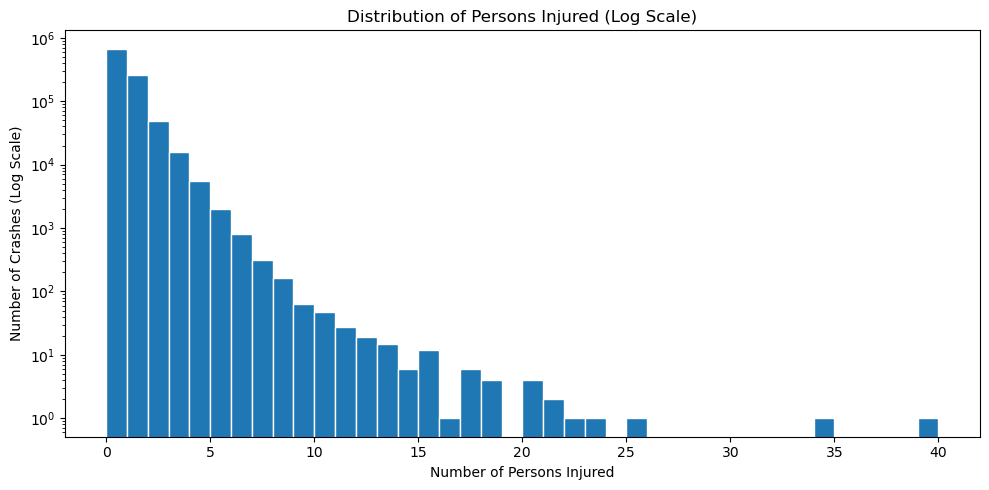

In [200]:
plt.figure(figsize=(10, 5))

plt.hist(
    crash_clean['NUMBER OF PERSONS INJURED'].dropna(),
    bins=40,
    edgecolor='white',
    log=True
)

plt.title('Distribution of Persons Injured (Log Scale)')
plt.xlabel('Number of Persons Injured')
plt.ylabel('Number of Crashes (Log Scale)')

plt.tight_layout()
plt.show()


<div style="background: #FFFFFF; border: 1px solid #DCECF6; border-left: 5px solid #2584A6; border-radius: 14px; padding: 22px 26px; margin: 20px 0;">
    <h3 style="color: #17324D; font-size: 19px; margin: 0 0 10px;">Descriptive Statistics Findings</h3>
    <p style="color: #62788C; font-size: 15px; margin: 0; line-height: 1.8;">
        The geographic coordinates fall within the selected NYC geographic boundaries. Negative LONGITUDE values are expected because New York City is located west of the Prime Meridian, while positive LATITUDE values indicate its position north of the Equator.
    </p>
    <p style="color: #62788C; font-size: 15px; margin: 12px 0 0; line-height: 1.8;">
        The casualty variables show a difference between their means and medians. For example, the mean number of persons injured is 0.44, while the median is zero. This indicates that most crashes have no reported injuries, while a smaller number of crashes with higher injury counts increase the average.
    </p>
    
<p style="color: #62788C; font-size: 15px; margin: 12px 0 0; line-height: 1.8;">
    The difference between the mean and median also indicates a positively skewed (right-skewed) distribution. Most observations are concentrated at zero or low injury counts, while a smaller number of crashes with high injury counts extend the distribution toward the right.
</p>

    
    
<p style="color: #62788C; font-size: 15px; margin: 12px 0 0; line-height: 1.8;">
        The standard deviations and upper percentiles provide additional information about the spread of the data and the presence of extreme observations. The maximum recorded values reach 40 injuries and 5 fatalities in a single crash.
    </p>
</div>



<div style="background: #FFFFFF; border: 1px solid #DCECF6; border-left: 5px solid #2584A6; border-radius: 14px; padding: 22px 26px; margin: 20px 0;">
    <h3 style="color: #17324D; font-size: 19px; margin: 0 0 10px;">4.1.2 Zero Values Analysis</h3>
    <p style="color: #62788C; font-size: 15px; margin: 0; line-height: 1.8;">
        Zero values in casualty-related variables were examined to identify crashes with no reported injuries or fatalities. These values represent valid observations rather than missing data and were therefore retained during the analysis.
    </p>
</div>


In [201]:
# Zero Values Analysis

casualty_columns = [
    'NUMBER OF PERSONS INJURED',
    'NUMBER OF PERSONS KILLED',
    'NUMBER OF PEDESTRIANS INJURED',
    'NUMBER OF PEDESTRIANS KILLED',
    'NUMBER OF CYCLIST INJURED',
    'NUMBER OF CYCLIST KILLED',
    'NUMBER OF MOTORIST INJURED',
    'NUMBER OF MOTORIST KILLED'
   
]

zero_analysis = pd.DataFrame({
    'Zero Count': (crash_clean[casualty_columns] == 0).sum(),
    'Zero Percentage': (
        (crash_clean[casualty_columns] == 0).mean() * 100
    ).round(2),
    'Missing Count': crash_clean[casualty_columns].isna().sum()
})

zero_analysis


,Zero Count,Zero Percentage,Missing Count
NUMBER OF PERSONS INJURED,670893,67.09,3
NUMBER OF PERSONS KILLED,997883,99.79,9
NUMBER OF PEDESTRIANS INJURED,928222,92.82,0
NUMBER OF PEDESTRIANS KILLED,999013,99.90,0
NUMBER OF CYCLIST INJURED,958354,95.84,0
NUMBER OF CYCLIST KILLED,999831,99.98,0
NUMBER OF MOTORIST INJURED,796042,79.60,0
NUMBER OF MOTORIST KILLED,999172,99.92,0



<div style="background: #FFFFFF; border: 1px solid #DCECF6; border-left: 5px solid #2584A6; border-radius: 14px; padding: 22px 26px; margin: 20px 0;">
    <h3 style="color: #17324D; font-size: 19px; margin: 0 0 10px;">4.1.3 Crashes Without Casualties</h3>
    <p style="color: #62788C; font-size: 15px; margin: 0; line-height: 1.8;">
        This analysis identifies the proportion of recorded crashes that resulted in neither injuries nor fatalities. Records with missing injury or fatality information were excluded to ensure that the classification was based on complete casualty data.
    </p>
</div>


In [246]:
# Crashes Without Injuries or Fatalities

casualty_data = crash_clean[
    casualty_columns
].dropna()

no_casualty = (
    (casualty_data['NUMBER OF PERSONS INJURED'] == 0) &
    (casualty_data['NUMBER OF PERSONS KILLED'] == 0)
)

no_casualty_count = no_casualty.sum()
total_valid_crashes = len(casualty_data)

no_casualty_percentage = (
    no_casualty_count / total_valid_crashes * 100
)

print(f"Crashes Without Casualties: {no_casualty_count:,}")
print(f"Total Valid Records: {total_valid_crashes:,}")
print(f"Percentage: {no_casualty_percentage:.2f}%")


Crashes Without Casualties: 669,299
Total Valid Records: 999,989
Percentage: 66.93%


<div style="background: #FFFFFF; border: 1px solid #DCECF6; border-left: 5px solid #2584A6; border-radius: 14px; padding: 22px 26px; margin: 20px 0;">
    <h3 style="color: #17324D; font-size: 19px; margin: 0 0 10px;">4.2 Exploratory Data Analysis</h3>
    <p style="color: #62788C; font-size: 15px; margin: 0; line-height: 1.8;">
        Exploratory Data Analysis (EDA) was conducted to identify patterns, trends, and relationships in motor vehicle collisions. The analysis focuses on crash frequency, severity, time patterns, vehicle types, contributing factors, and borough-level differences.
    </p>
</div>

<div style="background: #FFFFFF; border-left: 5px solid #2584A6; border-radius: 12px; padding: 22px; margin: 18px 0;">
    <h3 style="color: #17324D; font-size: 22px; margin: 0 0 16px;">
        Q1. How Does Collision Severity Vary Across Different Time Periods and Days?
    </h3>

 <p style="color: #62788C; font-size: 15px; line-height: 1.8;">
        <strong style="color: #2584A6;">Objective</strong><br>
        Examine how collision severity changes throughout the day and compare injury and fatal collision percentages between weekdays and weekends.
    </p>

 <p style="color: #62788C; font-size: 15px; line-height: 1.8; margin-bottom: 0;">
        <strong style="color: #2584A6;">Method</strong><br>
        Group collisions by time period and day type. Calculate the percentage of Low, Medium, and High severity collisions within each group using known severity records.
    </p>
</div>

Crash Severity by Time Period


Crash Severity,Low,Medium,High
Time Period,,,
Afternoon,67.22%,32.65%,0.13%
Evening,62.56%,37.18%,0.26%
Late Night,67.71%,31.85%,0.45%
Morning,70.52%,29.31%,0.16%



Crash Severity by Day Type


Crash Severity,Low,Medium,High
Day Type,,,
Weekday,66.94%,32.86%,0.20%
Weekend,66.90%,32.84%,0.25%


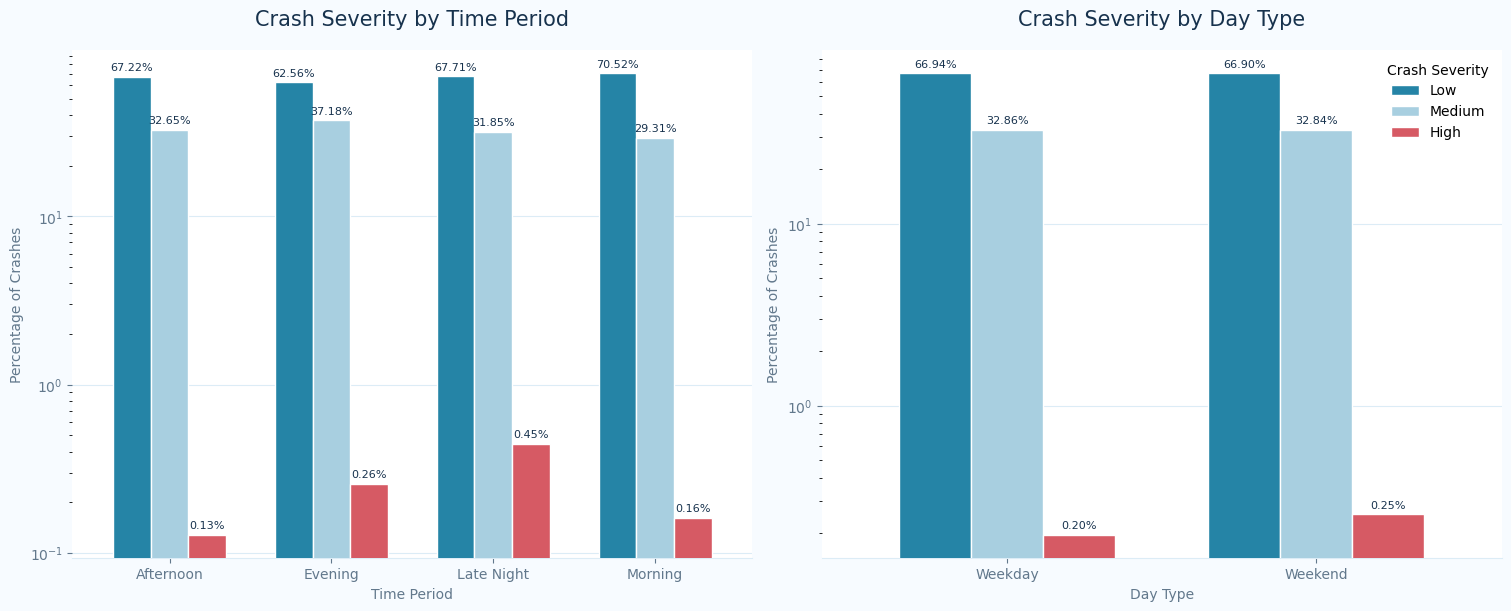

In [202]:
# Define severity categories and theme colors
severity_order = ['Low', 'Medium', 'High']

severity_colors = {
    'Low': '#2584A6',
    'Medium': '#A8CFE0',
    'High': '#D65A64'
}

# Calculate severity percentages by time period
time_severity = pd.crosstab(
    crash_clean['Time Period'],
    crash_clean['Crash Severity'],
    normalize='index'
).mul(100)

time_severity = (
    time_severity
    .drop(index='Unknown', errors='ignore')
    .reindex(columns=severity_order)
)

# Calculate severity percentages by day type
day_severity = pd.crosstab(
    crash_clean['Day Type'],
    crash_clean['Crash Severity'],
    normalize='index'
).mul(100)

day_severity = (
    day_severity
    .drop(index='Unknown', errors='ignore')
    .reindex(columns=severity_order)
)

# Display both summary tables
print("Crash Severity by Time Period")

display(
    time_severity.style.format("{:.2f}%")
)

print("\nCrash Severity by Day Type")

display(
    day_severity.style.format("{:.2f}%")
)


fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 6),
    constrained_layout=True
)

fig.patch.set_facecolor('#F7FBFF')

chart_settings = [
    (time_severity, 'Crash Severity by Time Period', 'Time Period'),
    (day_severity, 'Crash Severity by Day Type', 'Day Type')
]

for ax, (data, title, xlabel) in zip(axes, chart_settings):

    data.plot(
        kind='bar',
        ax=ax,
        color=['#2584A6', '#A8CFE0', '#D65A64'],
        edgecolor='white',
        width=0.7,
        zorder=3
    )

    ax.set_yscale('log')

    for container in ax.containers:
        ax.bar_label(
            container,
            fmt='%.2f%%',
            padding=3,
            fontsize=8,
            color='#17324D'
        )

    ax.set_facecolor('#FFFFFF')

    ax.set_title(
        title,
        color='#17324D',
        fontsize=15,
        pad=18
    )

    ax.set_xlabel(xlabel, color='#62788C')
    ax.set_ylabel('Percentage of Crashes', color='#62788C')

    ax.tick_params(colors='#62788C')
    ax.tick_params(axis='x', rotation=0)

    if ax == axes[1]:
        ax.legend(
            title='Crash Severity',
            loc='upper right',
            frameon=False
        )
    else:
        ax.get_legend().remove()

    ax.grid(axis='y', color='#DCECF6', zorder=0)
    ax.set_axisbelow(True)

    ax.spines[['top', 'right', 'left']].set_visible(False)
    ax.spines['bottom'].set_color('#DCECF6')

plt.show()
   

<div style="background: #FFFFFF; border-left: 5px solid #D65A64; border-radius: 12px; padding: 22px; margin: 18px 0;">
    <h3 style="color: #17324D; font-size: 20px; margin: 0 0 12px;">
        Key Insight
    </h3>
    <p style="color: #62788C; font-size: 15px; line-height: 1.8; margin: 0;">
        Low-severity collisions represent the largest share across all time periods and day categories. Morning records the highest percentage of low-severity collisions (70.52%), while Evening has the highest percentage of medium-severity collisions (37.18%). Late Night records the highest percentage of high-severity collisions (0.45%). Severity distributions are nearly identical between weekdays and weekends, although weekends show a slightly higher high-severity share (0.25% compared with 0.20%).
    </p>
</div>

<div style="background: #FFFFFF; border-left: 5px solid #2584A6; border-radius: 12px; padding: 22px; margin: 18px 0;">
    <h3 style="color: #17324D; font-size: 22px; margin: 0 0 16px;">
        Q2. Which Hours Have the Highest Fatal Collision Rates?
    </h3>

 <p style="color: #62788C; font-size: 15px; line-height: 1.8;">
        <strong style="color: #2584A6;">Objective</strong><br>
        Identify the hours with the highest fatal collision rates and examine whether the highest rates also correspond to a large number of fatal crashes.
    </p>

<p style="color: #62788C; font-size: 15px; line-height: 1.8; margin-bottom: 0;">
        <strong style="color: #2584A6;">Method</strong><br>
        Group collisions by crash hour and calculate the total number of recorded crashes, the number of fatal crashes, and the fatal collision rate. Rank the hours by fatal collision rate and visualize the top 10 hours.
    </p>
</div>

Fatal Collision Rates by Hour


,Crash_Count,High_Severity_Count,High Severity Rate
Crash Hour,,,
4,"16,453",108,0.656%
3,"14,866",88,0.592%
5,"17,568",88,0.501%
2,"16,431",80,0.487%
1,"20,956",86,0.410%
23,"31,109",119,0.383%
6,"25,623",90,0.351%
21,"38,269",119,0.311%
22,"35,174",107,0.304%


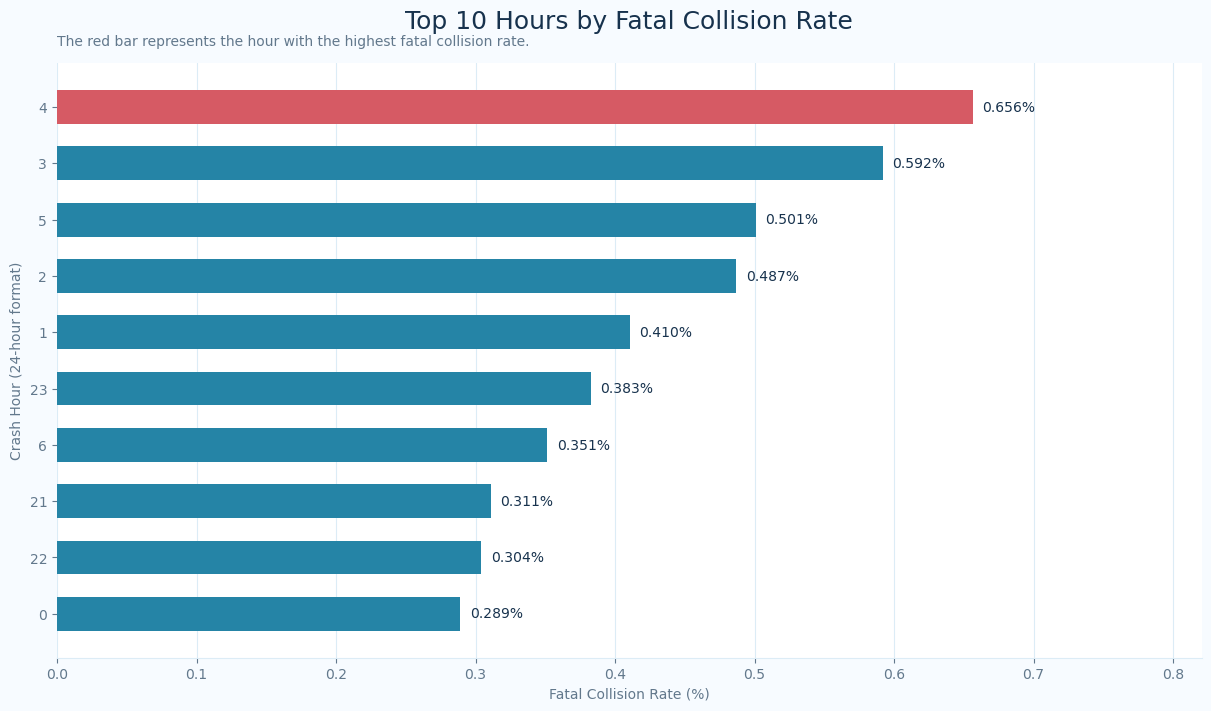

In [203]:
# Exclude records with unknown severity
hour_data = crash_clean[
    crash_clean['Crash Severity'] != 'Unknown'
]

# Calculate collision measures by hour
hour_summary = (
    hour_data
    .groupby('Crash Hour')
    .agg(
        Crash_Count=('Crash Severity', 'size'),
        High_Severity_Count=(
            'Crash Severity',
            lambda x: (x == 'High').sum()
        )
    )
)

# Calculate fatal collision rate
hour_summary['High Severity Rate'] = (
    hour_summary['High_Severity_Count']
    .div(hour_summary['Crash_Count'])
    .mul(100)
)

# Rank hours by fatal collision rate
hour_summary = hour_summary.sort_values(
    'High Severity Rate',
    ascending=False
)

# Display the results
print("Fatal Collision Rates by Hour")

display(
    hour_summary.style.format({
        'Crash_Count': '{:,.0f}',
        'High_Severity_Count': '{:,.0f}',
        'High Severity Rate': '{:.3f}%'
    })
)

# Select the top 10 hours
top_hours = (
    hour_summary
    .head(10)
    .sort_values('High Severity Rate')
)

# Highlight the hour with the highest fatal collision rate
maximum_rate = top_hours['High Severity Rate'].max()

colors = [
    '#D65A64' if value == maximum_rate
    else '#2584A6'
    for value in top_hours['High Severity Rate']
]

# Create the chart
fig, ax = plt.subplots(
    figsize=(12, 7),
    constrained_layout=True
)

fig.patch.set_facecolor('#F7FBFF')
ax.set_facecolor('#FFFFFF')

bars = ax.barh(
    top_hours.index.astype(str),
    top_hours['High Severity Rate'],
    color=colors,
    height=0.6,
    zorder=3
)

# Add percentage labels
ax.bar_label(
    bars,
    labels=[
        f'{value:.3f}%'
        for value in top_hours['High Severity Rate']
    ],
    padding=7,
    fontsize=10,
    color='#17324D'
)

ax.set_xlim(
    0,
    top_hours['High Severity Rate'].max() * 1.25
)

ax.set_title(
    'Top 10 Hours by Fatal Collision Rate',
    color='#17324D',
    fontsize=18,
    pad=25
)

ax.text(
    0,
    1.03,
    'The red bar represents the hour with the highest fatal collision rate.',
    transform=ax.transAxes,
    color='#62788C',
    fontsize=10
)

ax.set_xlabel('Fatal Collision Rate (%)', color='#62788C')
ax.set_ylabel('Crash Hour (24-hour format)', color='#62788C')

ax.grid(axis='x', color='#DCECF6', zorder=0)
ax.set_axisbelow(True)

ax.spines[['top', 'right', 'left']].set_visible(False)
ax.spines['bottom'].set_color('#DCECF6')

ax.tick_params(colors='#62788C')

plt.show()

<div style="background: #FFFFFF; border-left: 5px solid #D65A64; border-radius: 12px; padding: 22px; margin: 18px 0;">
    <h3 style="color: #17324D; font-size: 20px; margin: 0 0 12px;">
        Key Insight
    </h3>
    <p style="color: #62788C; font-size: 15px; line-height: 1.8; margin: 0;">
        The highest fatal collision rate occurs at 4 AM (0.656%), followed by 3 AM (0.592%) and 5 AM (0.501%). However, these hours have fewer recorded collisions than most daytime hours. This shows that a higher fatal collision rate does not necessarily correspond to a higher number of crashes. The results highlight differences between collision frequency and severity.
    </p>
</div>

<div style="background: #FFFFFF; border-left: 5px solid #2584A6; border-radius: 12px; padding: 22px; margin: 18px 0;">
    <h3 style="color: #17324D; font-size: 22px; margin: 0 0 16px;">
        Q3. Which Weekend Day Has the Highest Fatal Collision Rate?
    </h3>

<p style="color: #62788C; font-size: 15px; line-height: 1.8;">
        <strong style="color: #2584A6;">Objective</strong><br>
        Compare Saturday and Sunday to determine which weekend day has a higher fatal collision rate.
    </p>

 <p style="color: #62788C; font-size: 15px; line-height: 1.8; margin-bottom: 0;">
        <strong style="color: #2584A6;">Method</strong><br>
        Filter weekend collisions, group records by day name, and calculate recorded crashes, fatal crashes, and fatal collision percentages. Compare both days using a bar chart.
    </p>
</div>

Fatal Collision Rates by Weekend Day


,Crash_Count,High_Severity_Count,High Severity Rate
Day Name,,,
Saturday,"138,413",365,0.264%
Sunday,"125,778",305,0.242%


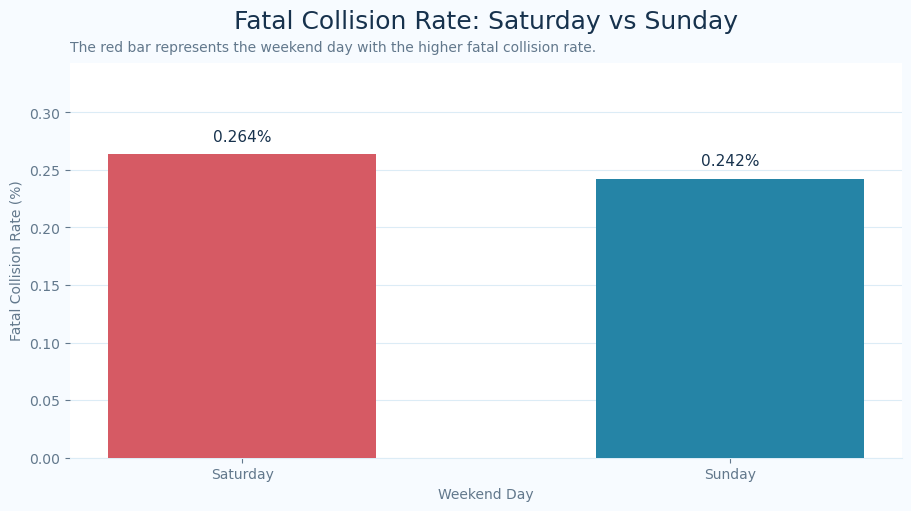

In [204]:
# Select weekend collisions with known severity
weekend_data = crash_clean[
    (crash_clean['Day Type'] == 'Weekend') &
    (crash_clean['Crash Severity'] != 'Unknown')
].copy()

# Extract the day name
weekend_data['Day Name'] = (
    weekend_data['CRASH DATE'].dt.day_name()
)

# Calculate collision measures by weekend day
weekend_summary = (
    weekend_data
    .groupby('Day Name')
    .agg(
        Crash_Count=('Crash Severity', 'size'),
        High_Severity_Count=(
            'Crash Severity',
            lambda x: (x == 'High').sum()
        )
    )
    .reindex(['Saturday', 'Sunday'])
)

# Calculate fatal collision rate
weekend_summary['High Severity Rate'] = (
    weekend_summary['High_Severity_Count']
    .div(weekend_summary['Crash_Count'])
    .mul(100)
)

# Display results
print("Fatal Collision Rates by Weekend Day")

display(
    weekend_summary.style.format({
        'Crash_Count': '{:,.0f}',
        'High_Severity_Count': '{:,.0f}',
        'High Severity Rate': '{:.3f}%'
    })
)

# Highlight the day with the highest fatal collision rate
maximum_rate = weekend_summary['High Severity Rate'].max()

colors = [
    '#D65A64' if value == maximum_rate
    else '#2584A6'
    for value in weekend_summary['High Severity Rate']
]

# Create the chart
fig, ax = plt.subplots(
    figsize=(9, 5),
    constrained_layout=True
)

fig.patch.set_facecolor('#F7FBFF')
ax.set_facecolor('#FFFFFF')

bars = ax.bar(
    weekend_summary.index,
    weekend_summary['High Severity Rate'],
    color=colors,
    width=0.55,
    zorder=3
)

# Add percentage labels
ax.bar_label(
    bars,
    labels=[
        f'{value:.3f}%'
        for value in weekend_summary['High Severity Rate']
    ],
    padding=7,
    fontsize=11,
    color='#17324D'
)

ax.set_ylim(
    0,
    maximum_rate * 1.3
)

ax.set_title(
    'Fatal Collision Rate: Saturday vs Sunday',
    color='#17324D',
    fontsize=18,
    pad=25
)

ax.text(
    0,
    1.03,
    'The red bar represents the weekend day with the higher fatal collision rate.',
    transform=ax.transAxes,
    color='#62788C',
    fontsize=10
)

ax.set_xlabel('Weekend Day', color='#62788C')
ax.set_ylabel('Fatal Collision Rate (%)', color='#62788C')

ax.grid(axis='y', color='#DCECF6', zorder=0)
ax.set_axisbelow(True)

ax.spines[['top', 'right', 'left']].set_visible(False)
ax.spines['bottom'].set_color('#DCECF6')

ax.tick_params(colors='#62788C')

plt.show()

<div style="background: #FFFFFF; border-left: 5px solid #D65A64; border-radius: 12px; padding: 22px; margin: 18px 0;">
    <h3 style="color: #17324D; font-size: 20px; margin: 0 0 12px;">
        Key Insight
    </h3>
    <p style="color: #62788C; font-size: 15px; line-height: 1.8; margin: 0;">
        Saturday records more collisions than Sunday, with 138,413 crashes compared with 125,778. Saturday also has a slightly higher fatal collision rate (0.264% versus 0.242%). The difference in fatal collision rates is small, suggesting that the two weekend days have relatively similar fatal collision proportions.
    </p>
</div>


<div style="background: #FFFFFF; border-left: 5px solid #2584A6; border-radius: 12px; padding: 22px; margin: 18px 0;">
    <h3 style="color: #17324D; font-size: 22px; margin: 0 0 16px;">
        Q4. Which Contributing Factors Are Associated with the Highest Fatal Collision Rates?
    </h3>
    <p style="color: #62788C; font-size: 15px; line-height: 1.8;">
        <strong style="color: #2584A6;">Objective</strong><br>
        Identify the contributing factors associated with the highest fatal collision rates and compare their fatal crash counts.
    </p>
    <p style="color: #62788C; font-size: 15px; line-height: 1.8; margin-bottom: 0;">
        <strong style="color: #2584A6;">Method</strong><br>
        Group collisions by the first recorded contributing factor. Calculate total crashes, fatal crashes, and fatal collision rates. Exclude unspecified and inapplicable factors, and consider categories with at least 100 recorded crashes.
    </p>
</div>


Fatal Collision Rates by Contributing Factor


,Crash_Count,Fatal_Crash_Count,Fatal Collision Rate
CONTRIBUTING FACTOR VEHICLE 1,,,
LOST CONSCIOUSNESS,"1,573",50,3.179%
ILLNES,"1,453",41,2.822%
TINTED WINDOWS,164,3,1.829%
UNSAFE SPEED,"25,105",346,1.378%
OTHER LIGHTING DEFECTS,108,1,0.926%
PEDESTRIAN/BICYCLIST/OTHER PEDESTRIAN ERROR/CONFUSION,"8,600",72,0.837%
TRAFFIC CONTROL DISREGARDED,"21,219",143,0.674%
PAVEMENT DEFECTIVE,"1,101",7,0.636%
DRUGS (ILLEGAL),665,4,0.602%


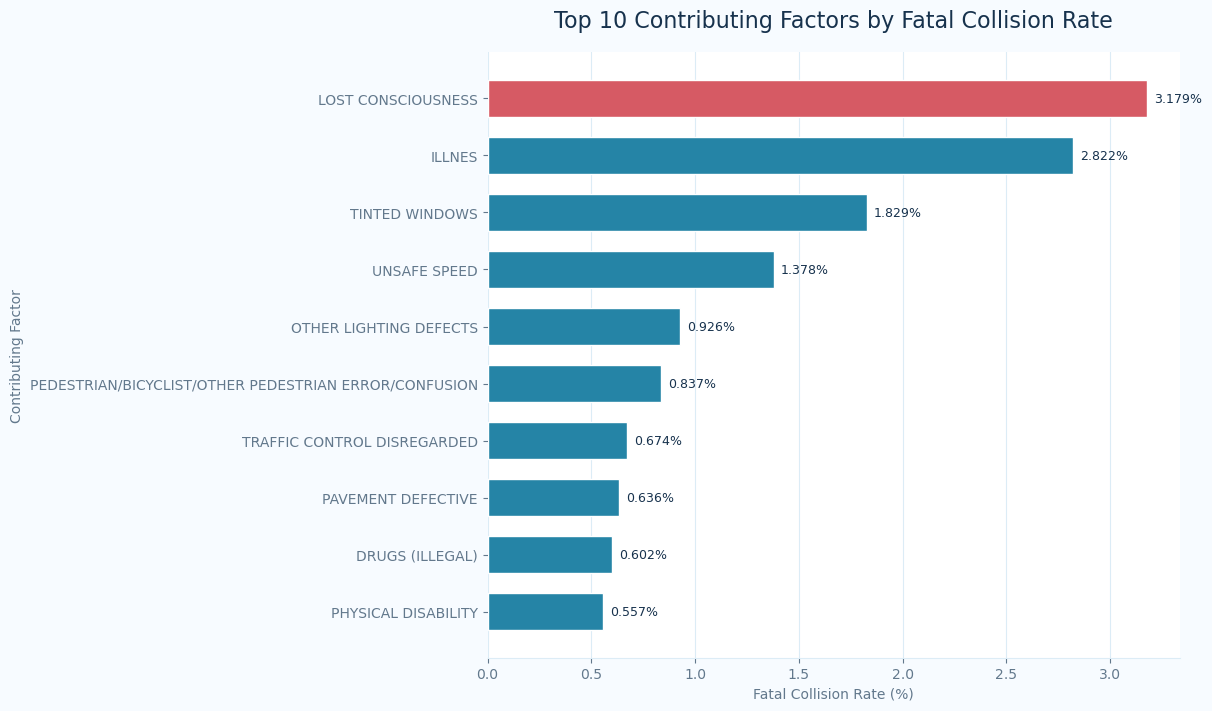

In [205]:
factor_data = crash_clean[
    (crash_clean['Crash Severity'] != 'Unknown') &
    (crash_clean['CONTRIBUTING FACTOR VEHICLE 1'].notna())
].copy()

factor_data['CONTRIBUTING FACTOR VEHICLE 1'] = (
    factor_data['CONTRIBUTING FACTOR VEHICLE 1']
    .str.strip()
    .str.upper()
)

excluded_factors = [
    'UNSPECIFIED',
    'DOES NOT APPLY'
]

factor_data = factor_data[
    ~factor_data['CONTRIBUTING FACTOR VEHICLE 1'].isin(excluded_factors)
]

factor_summary = (
    factor_data
    .groupby('CONTRIBUTING FACTOR VEHICLE 1')
    .agg(
        Crash_Count=('Crash Severity', 'size'),
        Fatal_Crash_Count=(
            'Crash Severity',
            lambda x: (x == 'High').sum()
        )
    )
)

factor_summary = factor_summary[
    factor_summary['Crash_Count'] >= 100
].copy()

factor_summary['Fatal Collision Rate'] = (
    factor_summary['Fatal_Crash_Count']
    .div(factor_summary['Crash_Count'])
    .mul(100)
)

factor_summary = factor_summary.sort_values(
    'Fatal Collision Rate',
    ascending=False
)

print("Fatal Collision Rates by Contributing Factor")

display(
    factor_summary.head(10).style.format({
        'Crash_Count': '{:,.0f}',
        'Fatal_Crash_Count': '{:,.0f}',
        'Fatal Collision Rate': '{:.3f}%'
    })
)

top_factors = (
    factor_summary
    .head(10)
    .sort_values('Fatal Collision Rate')
)

fig, ax = plt.subplots(figsize=(12, 7), constrained_layout=True)

fig.patch.set_facecolor('#F7FBFF')
ax.set_facecolor('#FFFFFF')

max_rate = top_factors['Fatal Collision Rate'].max()

colors = [
    '#D65A64' if value == max_rate else '#2584A6'
    for value in top_factors['Fatal Collision Rate']
]

bars = ax.barh(
    top_factors.index,
    top_factors['Fatal Collision Rate'],
    color=colors,
    edgecolor='white',
    height=0.65,
    zorder=3
)

ax.bar_label(
    bars,
    labels=[
        f'{value:.3f}%'
        for value in top_factors['Fatal Collision Rate']
    ],
    padding=5,
    fontsize=9,
    color='#17324D'
)

ax.set_title(
    'Top 10 Contributing Factors by Fatal Collision Rate',
    color='#17324D',
    fontsize=16,
    pad=18
)

ax.set_xlabel('Fatal Collision Rate (%)', color='#62788C')
ax.set_ylabel('Contributing Factor', color='#62788C')

ax.grid(axis='x', color='#DCECF6', zorder=0)
ax.set_axisbelow(True)

ax.spines[['top', 'right', 'left']].set_visible(False)
ax.spines['bottom'].set_color('#DCECF6')

ax.tick_params(colors='#62788C')

plt.show()

<div style="background: #FFFFFF; border-left: 5px solid #D65A64; border-radius: 12px; padding: 22px; margin: 18px 0;">
    <h3 style="color: #17324D; font-size: 20px; margin: 0 0 12px;">
        Key Insight
    </h3>
    <p style="color: #62788C; font-size: 15px; line-height: 1.8; margin: 0;">
        Lost Consciousness has the highest fatal collision rate (3.179%), followed by Illness (2.822%). Unsafe Speed records a lower rate (1.378%) but has a much larger number of fatal crashes (346) across 25,105 collisions. Some factors have very small sample sizes, so their high rates should be interpreted with caution. These findings show differences in fatal collision rates across contributing factors, but they do not establish causation.
    </p>
</div>

<div style="background: #FFFFFF; border-left: 5px solid #2584A6; border-radius: 12px; padding: 22px; margin: 18px 0;">
    <h3 style="color: #17324D; font-size: 22px; margin: 0 0 16px;">
        Q5. How Does Collision Frequency Vary Across Hours and Time Periods?
    </h3>
    <p style="color: #62788C; font-size: 15px; line-height: 1.8;">
        <strong style="color: #2584A6;">Objective</strong><br>
        Identify the hours and time periods with the highest collision frequency and examine how crash volume changes throughout the day.
    </p>
    <p style="color: #62788C; font-size: 15px; line-height: 1.8; margin-bottom: 0;">
        <strong style="color: #2584A6;">Method</strong><br>
        Extract the crash hour from the recorded time, group collisions by hour and time period, and calculate the total number and percentage of crashes. Compare hourly crash counts and average hourly frequency across time periods.
    </p>
</div>

Hourly Collision Frequency


,Crash Hour,Crash_Count,Crash_Percentage
0,0,"41,493",4.15%
1,1,"20,956",2.10%
2,2,"16,431",1.64%
3,3,"14,866",1.49%
4,4,"16,454",1.65%
5,5,"17,568",1.76%
6,6,"25,625",2.56%
7,7,"34,819",3.48%
8,8,"52,302",5.23%
9,9,"48,023",4.80%


Collision Frequency by Time Period


,Time Period,Crash_Count,Average_Crashes_Per_Hour
0,Late Night,"127,768","21,295"
1,Morning,"255,046","42,508"
2,Afternoon,"361,307","60,218"
3,Evening,"255,879","42,646"


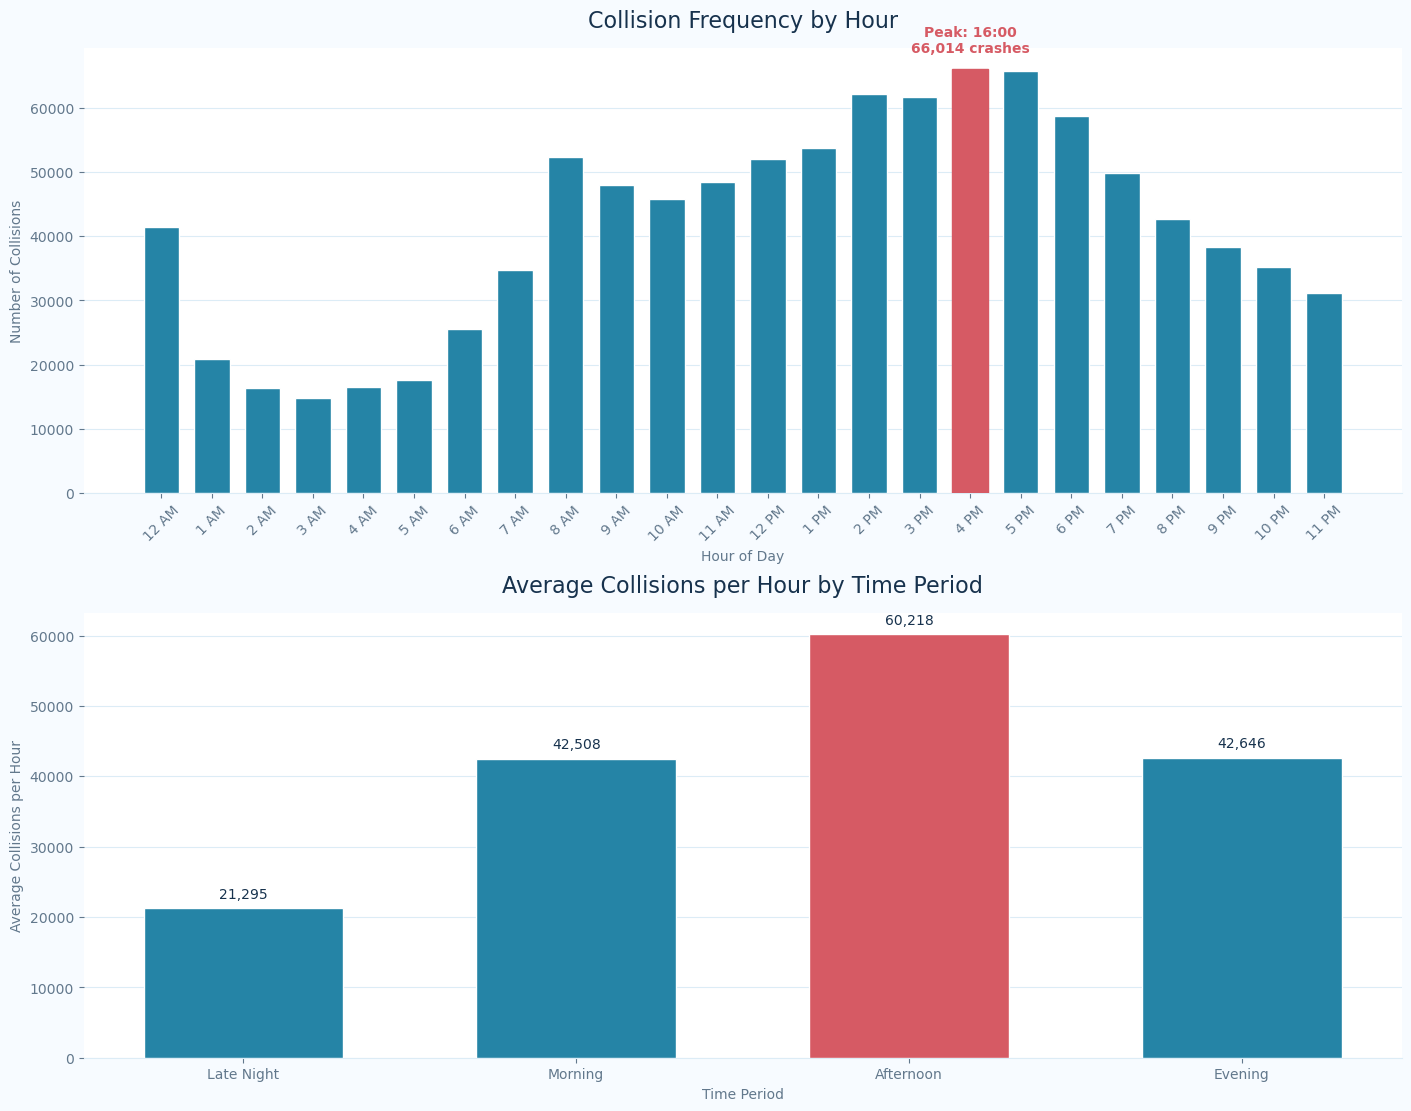

In [206]:
# Calculate hourly crash frequency
hourly_summary = (
    crash_clean
    .dropna(subset=['Crash Hour'])
    .groupby('Crash Hour')
    .size()
    .reset_index(name='Crash_Count')
)

hourly_summary['Crash_Percentage'] = (
    hourly_summary['Crash_Count']
    / hourly_summary['Crash_Count'].sum()
    * 100
)

# Calculate crash frequency by existing time periods
period_order = [
    'Late Night',
    'Morning',
    'Afternoon',
    'Evening'
]

period_summary = (
    crash_clean
    .dropna(subset=['Time Period'])
    .groupby('Time Period', observed=True)
    .size()
    .reindex(period_order)
    .reset_index(name='Crash_Count')
)

# Each time period contains 6 hours
period_summary['Average_Crashes_Per_Hour'] = (
    period_summary['Crash_Count'] / 6
)

# Display summaries
print("Hourly Collision Frequency")

display(
    hourly_summary.style.format({
        'Crash_Count': '{:,.0f}',
        'Crash_Percentage': '{:.2f}%'
    })
)

print("Collision Frequency by Time Period")

display(
    period_summary.style.format({
        'Crash_Count': '{:,.0f}',
        'Average_Crashes_Per_Hour': '{:,.0f}'
    })
)

# Prepare 12-hour labels
hour_labels = [
    pd.Timestamp(
        year=2026,
        month=1,
        day=1,
        hour=int(hour)
    ).strftime('%I %p').lstrip('0')
    for hour in hourly_summary['Crash Hour']
]

# Identify peak hour and period
peak_hour = hourly_summary.loc[
    hourly_summary['Crash_Count'].idxmax()
]

peak_period = period_summary.loc[
    period_summary['Average_Crashes_Per_Hour'].idxmax()
]

# Create charts
fig, axes = plt.subplots(
    2, 1,
    figsize=(14, 11),
    constrained_layout=True
)

fig.patch.set_facecolor('#F7FBFF')

# Hourly collision frequency
ax = axes[0]
ax.set_facecolor('#FFFFFF')

bars = ax.bar(
    hour_labels,
    hourly_summary['Crash_Count'],
    color='#2584A6',
    edgecolor='white',
    width=0.7,
    zorder=3
)

peak_index = hourly_summary['Crash_Count'].idxmax()
bars[peak_index].set_color('#D65A64')

ax.set_title(
    'Collision Frequency by Hour',
    color='#17324D',
    fontsize=16,
    pad=15
)

ax.set_xlabel('Hour of Day', color='#62788C')
ax.set_ylabel('Number of Collisions', color='#62788C')

ax.tick_params(axis='x', rotation=45, colors='#62788C')
ax.tick_params(axis='y', colors='#62788C')

ax.grid(axis='y', color='#DCECF6', zorder=0)
ax.set_axisbelow(True)

ax.spines[['top', 'right', 'left']].set_visible(False)
ax.spines['bottom'].set_color('#DCECF6')

ax.annotate(
    f"Peak: {int(peak_hour['Crash Hour']):02d}:00\n"
    f"{peak_hour['Crash_Count']:,.0f} crashes",
    xy=(peak_index, peak_hour['Crash_Count']),
    xytext=(0, 12),
    textcoords='offset points',
    ha='center',
    color='#D65A64',
    fontsize=10,
    fontweight='bold'
)

# Average hourly frequency by time period
ax = axes[1]
ax.set_facecolor('#FFFFFF')

period_colors = [
    '#D65A64' if value == peak_period['Average_Crashes_Per_Hour']
    else '#2584A6'
    for value in period_summary['Average_Crashes_Per_Hour']
]

bars = ax.bar(
    period_summary['Time Period'].astype(str),
    period_summary['Average_Crashes_Per_Hour'],
    color=period_colors,
    edgecolor='white',
    width=0.6,
    zorder=3
)

ax.bar_label(
    bars,
    fmt='{:,.0f}',
    padding=5,
    fontsize=10,
    color='#17324D'
)

ax.set_title(
    'Average Collisions per Hour by Time Period',
    color='#17324D',
    fontsize=16,
    pad=15
)

ax.set_xlabel('Time Period', color='#62788C')
ax.set_ylabel('Average Collisions per Hour', color='#62788C')

ax.tick_params(axis='x', colors='#62788C')
ax.tick_params(axis='y', colors='#62788C')

ax.grid(axis='y', color='#DCECF6', zorder=0)
ax.set_axisbelow(True)

ax.spines[['top', 'right', 'left']].set_visible(False)
ax.spines['bottom'].set_color('#DCECF6')

plt.show()

<div style="background: #FFFFFF; border-left: 5px solid #D65A64; border-radius: 12px; padding: 22px; margin: 18px 0;">
    <h3 style="color: #17324D; font-size: 20px; margin: 0 0 12px;">
        Key Insight
    </h3>
    <p style="color: #62788C; font-size: 15px; line-height: 1.8; margin: 0;">
        Collision frequency peaks during the afternoon, which records 361,307 crashes and the highest average hourly frequency of approximately 60,218 crashes. The 4 PM hour records the highest number of crashes (66,014), followed by 5 PM (65,680). In contrast, 3 AM records the lowest hourly count (14,866). These results show that collision volume is concentrated in the afternoon and late working hours.
    </p>
</div>

<div style="background: #FFFFFF; border-left: 5px solid #2584A6; border-radius: 12px; padding: 22px; margin: 18px 0;">
    <h3 style="color: #17324D; font-size: 22px; margin: 0 0 16px;">
        Q6. How Do Crash Counts and Injury-Crash Percentages Vary by Borough?
    </h3>
    <p style="color: #62788C; font-size: 15px; line-height: 1.8;">
        <strong style="color: #2584A6;">Objective</strong><br>
        Compare the number of recorded collisions across NYC boroughs and identify which boroughs have the highest percentages of crashes involving injuries.
    </p>
    <p style="color: #62788C; font-size: 15px; line-height: 1.8; margin-bottom: 0;">
        <strong style="color: #2584A6;">Method</strong><br>
        Group collisions by borough. Calculate total crashes, injury crashes, and the percentage of crashes involving at least one injured person. Exclude records with unknown borough information from the comparison.
    </p>
</div>

Collision Statistics by Borough


,Crash_Count,Injury_Crash_Count,Injury_Crash_Percentage
BOROUGH,,,
BROOKLYN,"237,425","81,780",34.44%
QUEENS,"195,995","64,019",32.66%
MANHATTAN,"127,489","39,008",30.60%
BRONX,"118,606","39,568",33.36%
STATEN ISLAND,"25,715","8,120",31.58%


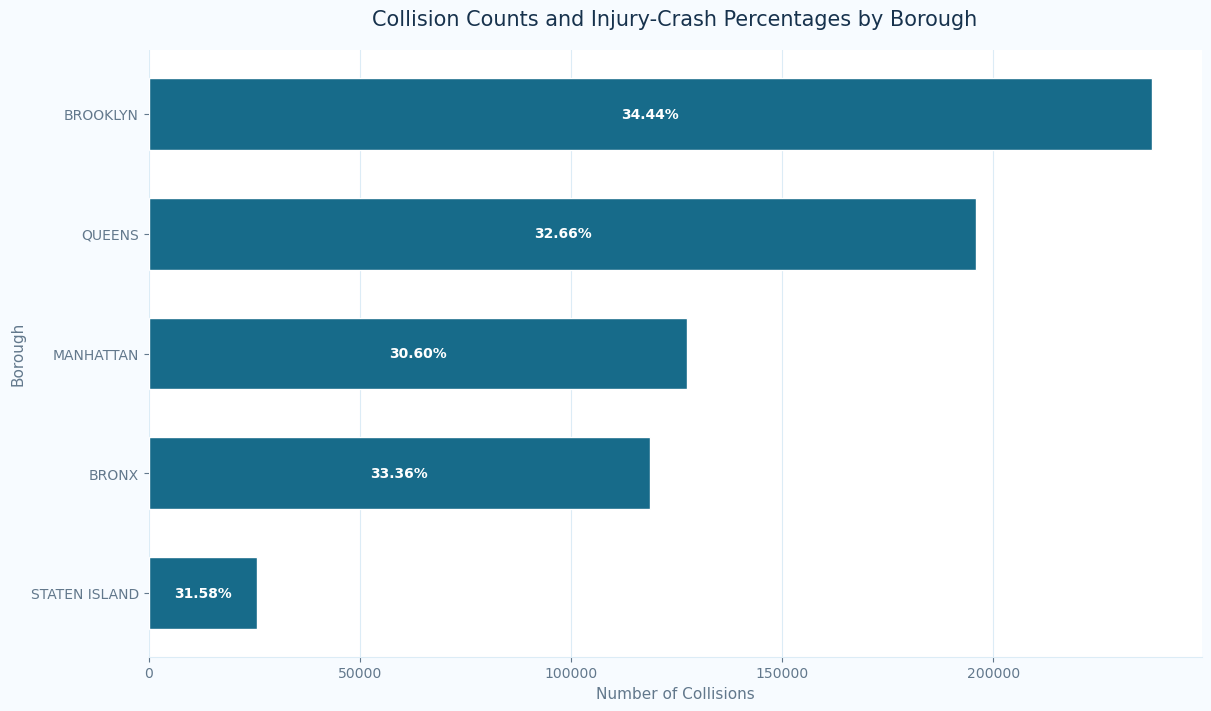

In [235]:
# Prepare borough data
borough_data = crash_clean[
    crash_clean['BOROUGH'].notna() &
    (crash_clean['BOROUGH'].str.upper() != 'UNKNOWN')
].copy()

# Ensure injury count is numeric
borough_data['NUMBER OF PERSONS INJURED'] = pd.to_numeric(
    borough_data['NUMBER OF PERSONS INJURED'],
    errors='coerce'
)

# Calculate crash statistics by borough
borough_summary = (
    borough_data
    .groupby('BOROUGH')
    .agg(
        Crash_Count=('BOROUGH', 'size'),
        Injury_Crash_Count=(
            'NUMBER OF PERSONS INJURED',
            lambda x: (x > 0).sum()
        )
    )
)

# Calculate injury crash percentage
borough_summary['Injury_Crash_Percentage'] = (
    borough_summary['Injury_Crash_Count']
    .div(borough_summary['Crash_Count'])
    .mul(100)
)

borough_summary = borough_summary.sort_values(
    'Crash_Count',
    ascending=True
)

# Display results
print("Collision Statistics by Borough")

display(
    borough_summary.sort_values(
        'Crash_Count',
        ascending=False
    ).style.format({
        'Crash_Count': '{:,.0f}',
        'Injury_Crash_Count': '{:,.0f}',
        'Injury_Crash_Percentage': '{:.2f}%'
    })
)

# Create combined chart
fig, ax1 = plt.subplots(
    figsize=(12, 7),
    constrained_layout=True
)

fig.patch.set_facecolor('#F7FBFF')
ax1.set_facecolor('#FFFFFF')

# Plot total collisions
bars = ax1.barh(
    borough_summary.index,
    borough_summary['Crash_Count'],
    color='#176B8A',
    edgecolor='white',
    height=0.6,
    zorder=3
)

# Add injury percentages inside bars
for bar, percentage in zip(
    bars,
    borough_summary['Injury_Crash_Percentage']
):
    ax1.text(
        bar.get_width() * 0.5,
        bar.get_y() + bar.get_height() / 2,
        f'{percentage:.2f}%',
        ha='center',
        va='center',
        color='white',
        fontsize=10,
        fontweight='bold'
    )

# Chart title and labels
ax1.set_title(
    'Collision Counts and Injury-Crash Percentages by Borough',
    color='#17324D',
    fontsize=15,
    pad=18
)

ax1.set_xlabel(
    'Number of Collisions',
    color='#62788C',
    fontsize=11
)

ax1.set_ylabel(
    'Borough',
    color='#62788C',
    fontsize=11
)

# Axis formatting
ax1.grid(
    axis='x',
    color='#DCECF6',
    zorder=0
)

ax1.set_axisbelow(True)

ax1.spines[['top', 'right', 'left']].set_visible(False)
ax1.spines['bottom'].set_color('#DCECF6')

ax1.tick_params(colors='#62788C')

ax1.set_xlim(
    0,
    borough_summary['Crash_Count'].max() * 1.05
)

plt.show()

<div style="background: #FFFFFF; border-left: 5px solid #D65A64; border-radius: 12px; padding: 22px; margin: 18px 0;">
    <h3 style="color: #17324D; font-size: 20px; margin: 0 0 12px;">
        Key Insight
    </h3>
    <p style="color: #62788C; font-size: 15px; line-height: 1.8; margin: 0;">
        Brooklyn records the highest number of collisions (237,425) and the largest number of injury-related crashes (81,780). It also has the highest injury-crash percentage among the five boroughs (34.44%). In contrast, Manhattan has the lowest injury-crash percentage (30.60%), while Staten Island records the fewest collisions (25,715). These results show that Brooklyn leads in both collision volume and injury-crash proportion, while Manhattan has the lowest proportion of crashes involving injuries.
    </p>
</div>

<div style="background: #FFFFFF; border-left: 5px solid #2584A6; border-radius: 12px; padding: 22px; margin: 18px 0;">
    <h3 style="color: #17324D; font-size: 22px; margin: 0 0 16px;">
        Q7. How Do Collision Frequency and Injury-Crash Percentages Vary Across the Days of the Week?
    </h3>
    <p style="color: #62788C; font-size: 15px; line-height: 1.8;">
        <strong style="color: #2584A6;">Objective</strong><br>
        Identify which days record the highest number of collisions and compare the percentage of crashes involving injuries across the seven days of the week.
    </p>
    <p style="color: #62788C; font-size: 15px; line-height: 1.8; margin-bottom: 0;">
        <strong style="color: #2584A6;">Method</strong><br>
        Group collisions by day of the week. Calculate total collisions, injury-related crashes, and the injury-crash percentage for each day. Compare both collision frequency and injury-crash proportions.
    </p>
</div>

Collision Statistics by Day of the Week


,Crash_Count,Injury_Crash_Count,Injury_Crash_Percentage
Day_Name,,,
Monday,"141,557","46,030",32.52%
Tuesday,"144,158","47,713",33.10%
Wednesday,"143,842","47,940",33.33%
Thursday,"148,402","48,680",32.80%
Friday,"157,847","51,777",32.80%
Saturday,"138,415","45,464",32.85%
Sunday,"125,779","41,500",32.99%


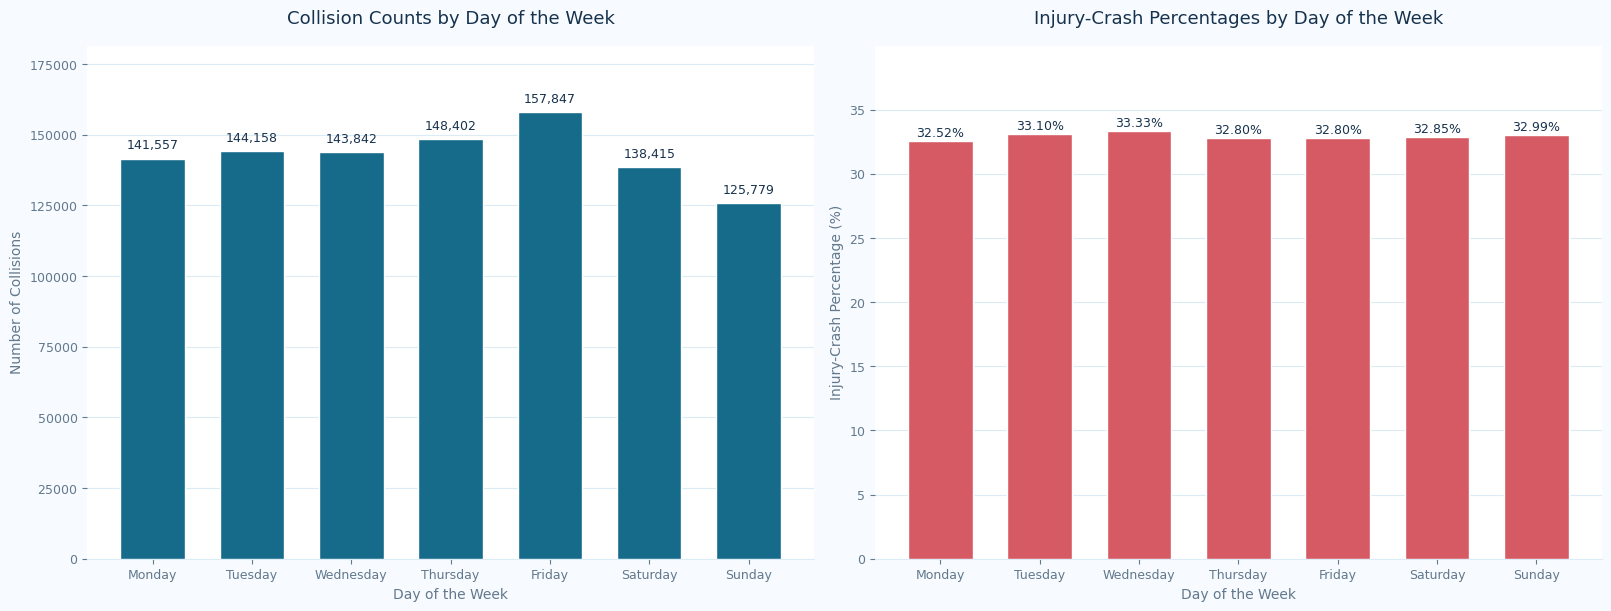

In [237]:
# Prepare data for day-of-week analysis
day_data = crash_clean[
    crash_clean['CRASH DATE'].notna()
].copy()

# Ensure injury count is numeric
day_data['NUMBER OF PERSONS INJURED'] = pd.to_numeric(
    day_data['NUMBER OF PERSONS INJURED'],
    errors='coerce'
)

# Calculate collision statistics by day of the week
day_summary = (
    day_data
    .assign(
        Day_Name=day_data['CRASH DATE'].dt.day_name()
    )
    .groupby('Day_Name')
    .agg(
        Crash_Count=('Day_Name', 'size'),
        Injury_Crash_Count=(
            'NUMBER OF PERSONS INJURED',
            lambda x: (x > 0).sum()
        )
    )
)

# Set weekday order
day_order = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

day_summary = day_summary.reindex(day_order)

# Calculate injury-crash percentage
day_summary['Injury_Crash_Percentage'] = (
    day_summary['Injury_Crash_Count']
    .div(day_summary['Crash_Count'])
    .mul(100)
)

# Display results
print("Collision Statistics by Day of the Week")

display(
    day_summary.style.format({
        'Crash_Count': '{:,.0f}',
        'Injury_Crash_Count': '{:,.0f}',
        'Injury_Crash_Percentage': '{:.2f}%'
    })
)

# Create two separate charts
fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 6),
    constrained_layout=True
)

fig.patch.set_facecolor('#F7FBFF')

# Chart 1: Collision Counts
ax1 = axes[0]
ax1.set_facecolor('#FFFFFF')

bars1 = ax1.bar(
    day_summary.index,
    day_summary['Crash_Count'],
    color='#176B8A',
    edgecolor='white',
    width=0.65,
    zorder=3
)

# Add collision counts above bars
for bar, count in zip(
    bars1,
    day_summary['Crash_Count']
):
    ax1.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 2500,
        f'{count:,.0f}',
        ha='center',
        va='bottom',
        color='#17324D',
        fontsize=9
    )

ax1.set_title(
    'Collision Counts by Day of the Week',
    color='#17324D',
    fontsize=13,
    pad=16
)

ax1.set_xlabel(
    'Day of the Week',
    color='#62788C'
)

ax1.set_ylabel(
    'Number of Collisions',
    color='#62788C'
)

ax1.set_ylim(
    0,
    day_summary['Crash_Count'].max() * 1.15
)

ax1.grid(
    axis='y',
    color='#DCECF6',
    zorder=0
)

ax1.set_axisbelow(True)
ax1.spines[['top', 'right', 'left']].set_visible(False)
ax1.spines['bottom'].set_color('#DCECF6')
ax1.tick_params(colors='#62788C', axis='both', labelsize=9)

# Chart 2: Injury-Crash Percentages
ax2 = axes[1]
ax2.set_facecolor('#FFFFFF')

bars2 = ax2.bar(
    day_summary.index,
    day_summary['Injury_Crash_Percentage'],
    color='#D65A64',
    edgecolor='white',
    width=0.65,
    zorder=3
)

# Add percentages above bars
for bar, percentage in zip(
    bars2,
    day_summary['Injury_Crash_Percentage']
):
    ax2.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.15,
        f'{percentage:.2f}%',
        ha='center',
        va='bottom',
        color='#17324D',
        fontsize=9
    )

ax2.set_title(
    'Injury-Crash Percentages by Day of the Week',
    color='#17324D',
    fontsize=13,
    pad=16
)

ax2.set_xlabel(
    'Day of the Week',
    color='#62788C'
)

ax2.set_ylabel(
    'Injury-Crash Percentage (%)',
    color='#62788C'
)

ax2.set_ylim(
    0,
    day_summary['Injury_Crash_Percentage'].max() * 1.2
)

ax2.grid(
    axis='y',
    color='#DCECF6',
    zorder=0
)

ax2.set_axisbelow(True)
ax2.spines[['top', 'right', 'left']].set_visible(False)
ax2.spines['bottom'].set_color('#DCECF6')
ax2.tick_params(colors='#62788C', axis='both', labelsize=9)

plt.show()

<div style="background: #FFFFFF; border-left: 5px solid #D65A64; border-radius: 12px; padding: 22px; margin: 18px 0;">
    <h3 style="color: #17324D; font-size: 20px; margin: 0 0 12px;">
        Key Insight
    </h3>
    <p style="color: #62788C; font-size: 15px; line-height: 1.8; margin: 0;">
        Friday records the highest number of collisions (157,847), while Sunday has the lowest (125,779). However, Wednesday has the highest injury-crash percentage (33.33%), followed by Tuesday (33.10%). Monday records the lowest percentage at 32.52%. Despite differences in collision volume, injury-crash percentages remain relatively close across all seven days, ranging from 32.52% to 33.33%.
    </p>
</div>

<div style="background: #FFFFFF; border-left: 5px solid #2584A6; border-radius: 12px; padding: 22px; margin: 18px 0;">
    <h3 style="color: #17324D; font-size: 22px; margin: 0 0 16px;">
        Q8. How Do Injuries and Fatalities Vary Across the Months of the Year?
    </h3>
    <p style="color: #62788C; font-size: 15px; line-height: 1.8;">
        <strong style="color: #2584A6;">Objective</strong><br>
        Examine monthly patterns in the number of persons injured and killed in motor vehicle collisions.
    </p>
    <p style="color: #62788C; font-size: 15px; line-height: 1.8; margin-bottom: 0;">
        <strong style="color: #2584A6;">Method</strong><br>
        Group collisions by month and calculate the total number of persons injured and killed. Compare the monthly totals using two separate charts.
    </p>
</div>

Monthly Injury and Fatality Statistics


,Persons_Injured,Persons_Killed
January,"29,923",155
February,"27,773",136
March,"32,045",140
April,"30,614",144
May,"37,077",182
June,"38,172",203
July,"43,483",213
August,"44,043",220
September,"43,727",210
October,"44,073",231


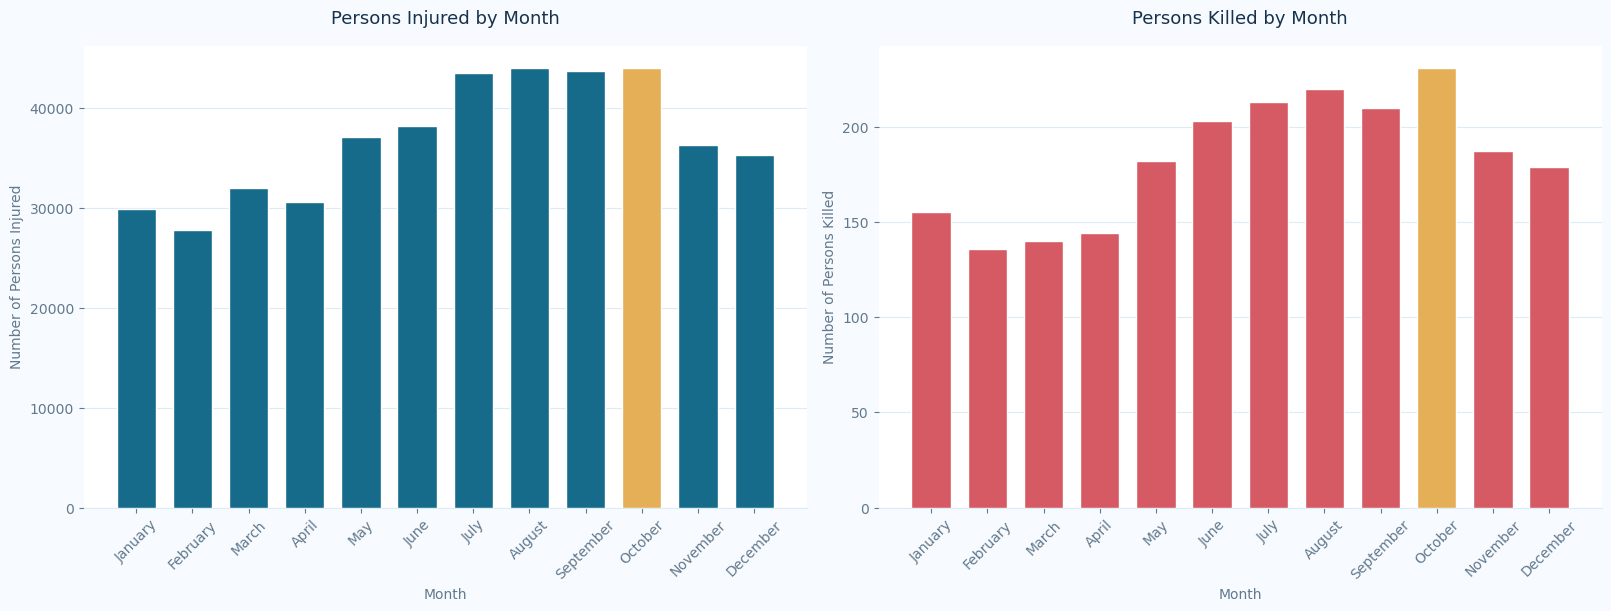

In [241]:
# ==========================================
# Q8: Monthly Injury and Fatality Patterns
# ==========================================

# Prepare monthly data
month_data = crash_clean[
    crash_clean['CRASH DATE'].notna()
].copy()

# Convert casualty columns to numeric
casualty_columns = [
    'NUMBER OF PERSONS INJURED',
    'NUMBER OF PERSONS KILLED'
]

month_data[casualty_columns] = month_data[
    casualty_columns
].apply(
    pd.to_numeric,
    errors='coerce'
).fillna(0)

# Extract month
month_data['Month'] = month_data['CRASH DATE'].dt.month

# Calculate monthly injury and fatality totals
month_summary = (
    month_data
    .groupby('Month')
    .agg(
        Persons_Injured=('NUMBER OF PERSONS INJURED', 'sum'),
        Persons_Killed=('NUMBER OF PERSONS KILLED', 'sum')
    )
)

# Set month order
month_order = list(range(1, 13))
month_summary = month_summary.reindex(month_order)

month_names = [
    'January', 'February', 'March',
    'April', 'May', 'June',
    'July', 'August', 'September',
    'October', 'November', 'December'
]

month_summary.index = month_names

# Display results
print("Monthly Injury and Fatality Statistics")

display(
    month_summary.style.format({
        'Persons_Injured': '{:,.0f}',
        'Persons_Killed': '{:,.0f}'
    })
)

# Identify the highest month in each category
max_injury_index = month_summary['Persons_Injured'].values.argmax()
max_fatality_index = month_summary['Persons_Killed'].values.argmax()

# Create two charts
fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 6),
    constrained_layout=True
)

fig.patch.set_facecolor('#F7FBFF')

# Chart 1: Persons Injured
ax1 = axes[0]
ax1.set_facecolor('#FFFFFF')

injury_colors = [
    '#E4AF56' if i == max_injury_index else '#176B8A'
    for i in range(len(month_summary))
]

ax1.bar(
    month_summary.index,
    month_summary['Persons_Injured'],
    color=injury_colors,
    edgecolor='white',
    width=0.7,
    zorder=3
)

ax1.set_title(
    'Persons Injured by Month',
    color='#17324D',
    fontsize=13,
    pad=16
)

ax1.set_xlabel('Month', color='#62788C')
ax1.set_ylabel('Number of Persons Injured', color='#62788C')

ax1.tick_params(
    axis='x',
    rotation=45,
    colors='#62788C'
)

ax1.tick_params(axis='y', colors='#62788C')
ax1.grid(axis='y', color='#DCECF6', zorder=0)
ax1.set_axisbelow(True)

ax1.spines[['top', 'right', 'left']].set_visible(False)
ax1.spines['bottom'].set_color('#DCECF6')

# Chart 2: Persons Killed
ax2 = axes[1]
ax2.set_facecolor('#FFFFFF')

fatality_colors = [
    '#E4AF56' if i == max_fatality_index else '#D65A64'
    for i in range(len(month_summary))
]

ax2.bar(
    month_summary.index,
    month_summary['Persons_Killed'],
    color=fatality_colors,
    edgecolor='white',
    width=0.7,
    zorder=3
)

ax2.set_title(
    'Persons Killed by Month',
    color='#17324D',
    fontsize=13,
    pad=16
)

ax2.set_xlabel('Month', color='#62788C')
ax2.set_ylabel('Number of Persons Killed', color='#62788C')

ax2.tick_params(
    axis='x',
    rotation=45,
    colors='#62788C'
)

ax2.tick_params(axis='y', colors='#62788C')
ax2.grid(axis='y', color='#DCECF6', zorder=0)
ax2.set_axisbelow(True)

ax2.spines[['top', 'right', 'left']].set_visible(False)
ax2.spines['bottom'].set_color('#DCECF6')

plt.show()

<div style="background: #FFFFFF; border-left: 5px solid #D65A64; border-radius: 12px; padding: 22px; margin: 18px 0;">
    <h3 style="color: #17324D; font-size: 20px; margin: 0 0 12px;">
        Key Insight
    </h3>
    <p style="color: #62788C; font-size: 15px; line-height: 1.8; margin: 0;">
        October records the highest number of persons injured (44,073) and persons killed (231), followed by August for injuries (44,043) and October for fatalities. February records the lowest injury and fatality totals, with 27,773 injuries and 136 deaths. Overall, injury and fatality counts tend to be higher during the summer and early autumn months. These patterns show monthly differences in casualty totals, but they do not establish the cause of these variations.
    </p>
</div>

<div style="background: #FFFFFF; border-left: 5px solid #2584A6; border-radius: 12px; padding: 22px; margin: 18px 0;">
    <h3 style="color: #17324D; font-size: 22px; margin: 0 0 16px;">
        Q9. How Do Injury and Fatal Collision Rates Vary Across Vehicle Types?
    </h3>
    <p style="color: #62788C; font-size: 15px; line-height: 1.8;">
        <strong style="color: #2584A6;">Objective</strong><br>
        Compare vehicle types involved in collisions resulting in injuries or fatalities and identify differences in their associated injury and fatal collision rates.
    </p>
    <p style="color: #62788C; font-size: 15px; line-height: 1.8; margin-bottom: 0;">
        <strong style="color: #2584A6;">Method</strong><br>
        Combine vehicle information from the five vehicle-type columns. Calculate the number of distinct collisions involving each vehicle type, injury-related collisions, fatal collisions, and their respective percentages. Focus on the ten most frequently recorded vehicle types.
    </p>
</div>

Injury and Fatality Statistics by Vehicle Type


,Crash_Count,Injury_Crash_Count,Fatal_Crash_Count,Injury_Crash_Percentage,Fatal_Crash_Percentage
Vehicle_Type,,,,,
SEDAN,"588,468","178,000",756,30.25%,0.13%
STATION WAGON/SPORT UTILITY VEHICLE,"489,468","148,841",881,30.41%,0.18%
TAXI,"52,267","17,842",56,34.14%,0.11%
PICK-UP TRUCK,"47,594","12,417",106,26.09%,0.22%
BIKE,"42,659","35,308",127,82.77%,0.30%
BOX TRUCK,"38,118","7,092",89,18.61%,0.23%
BUS,"30,769","7,380",78,23.99%,0.25%
4 DR SEDAN,"24,847","10,696",34,43.05%,0.14%
MOTORCYCLE,"15,595","10,316",305,66.15%,1.96%


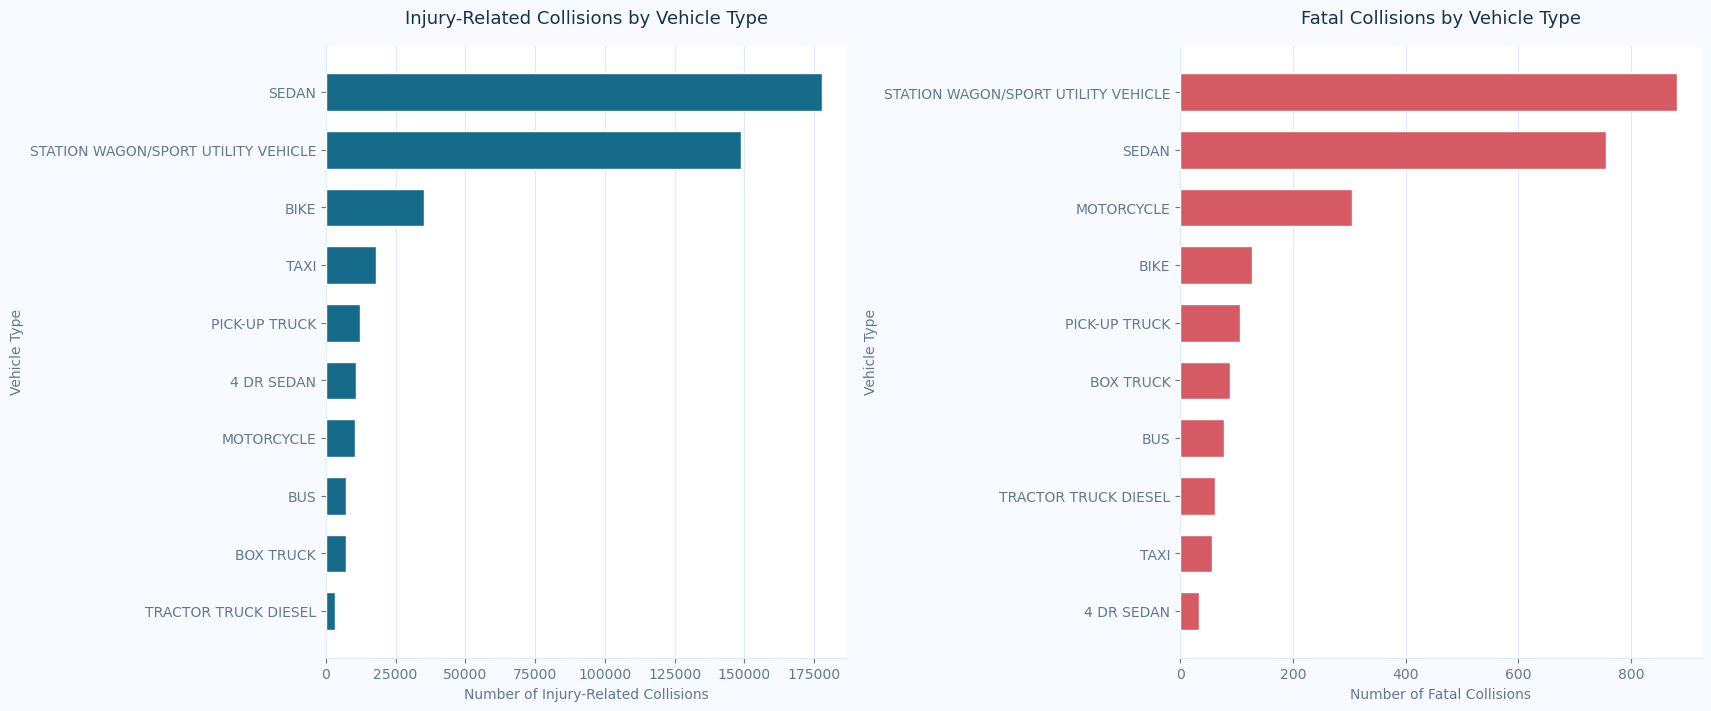

In [239]:
# ==========================================
# Q9: Vehicle Types and Injury/Fatality Outcomes
# ==========================================

# Identify vehicle type columns
vehicle_cols = [
    f'VEHICLE TYPE CODE {i}'
    for i in range(1, 6)
]

# Prepare vehicle data
vehicle_data = crash_clean[
    ['COLLISION_ID',
     'NUMBER OF PERSONS INJURED',
     'NUMBER OF PERSONS KILLED'] + vehicle_cols
].copy()

# Convert casualty columns to numeric
casualty_columns = [
    'NUMBER OF PERSONS INJURED',
    'NUMBER OF PERSONS KILLED'
]

vehicle_data[casualty_columns] = vehicle_data[
    casualty_columns
].apply(
    pd.to_numeric,
    errors='coerce'
).fillna(0)

# Create injury and fatality indicators
vehicle_data['Injury_Crash'] = (
    vehicle_data['NUMBER OF PERSONS INJURED'] > 0
).astype(int)

vehicle_data['Fatal_Crash'] = (
    vehicle_data['NUMBER OF PERSONS KILLED'] > 0
).astype(int)

# Combine the five vehicle type columns
vehicle_long = vehicle_data.melt(
    id_vars=[
        'COLLISION_ID',
        'Injury_Crash',
        'Fatal_Crash'
    ],
    value_vars=vehicle_cols,
    var_name='Vehicle_Position',
    value_name='Vehicle_Type'
)

# Standardize vehicle type values
vehicle_long['Vehicle_Type'] = (
    vehicle_long['Vehicle_Type']
    .astype('string')
    .str.strip()
    .str.upper()
)

# Remove missing and unspecified vehicle types
invalid_vehicle_values = [
    '',
    'NAN',
    'NONE',
    'UNKNOWN',
    'UNSPECIFIED'
]

vehicle_long = vehicle_long[
    vehicle_long['Vehicle_Type'].notna() &
    (~vehicle_long['Vehicle_Type'].isin(invalid_vehicle_values))
].copy()

# Count each collision once per vehicle type
vehicle_long = vehicle_long.drop_duplicates(
    subset=['COLLISION_ID', 'Vehicle_Type']
)

# Calculate statistics by vehicle type
vehicle_summary = (
    vehicle_long
    .groupby('Vehicle_Type')
    .agg(
        Crash_Count=('COLLISION_ID', 'nunique'),
        Injury_Crash_Count=('Injury_Crash', 'sum'),
        Fatal_Crash_Count=('Fatal_Crash', 'sum')
    )
)

# Calculate injury and fatal collision percentages
vehicle_summary['Injury_Crash_Percentage'] = (
    vehicle_summary['Injury_Crash_Count']
    .div(vehicle_summary['Crash_Count'])
    .mul(100)
)

vehicle_summary['Fatal_Crash_Percentage'] = (
    vehicle_summary['Fatal_Crash_Count']
    .div(vehicle_summary['Crash_Count'])
    .mul(100)
)

# Select the top 10 vehicle types by collision count
vehicle_summary = (
    vehicle_summary
    .sort_values('Crash_Count', ascending=False)
    .head(10)
)

# Display results
print("Injury and Fatality Statistics by Vehicle Type")

display(
    vehicle_summary.style.format({
        'Crash_Count': '{:,.0f}',
        'Injury_Crash_Count': '{:,.0f}',
        'Fatal_Crash_Count': '{:,.0f}',
        'Injury_Crash_Percentage': '{:.2f}%',
        'Fatal_Crash_Percentage': '{:.2f}%'
    })
)

# Create two charts
fig, axes = plt.subplots(
    1, 2,
    figsize=(17, 7),
    constrained_layout=True
)

fig.patch.set_facecolor('#F7FBFF')

# Chart 1: Injury Crashes
ax1 = axes[0]
ax1.set_facecolor('#FFFFFF')

injury_plot = vehicle_summary.sort_values(
    'Injury_Crash_Count'
)

ax1.barh(
    injury_plot.index,
    injury_plot['Injury_Crash_Count'],
    color='#176B8A',
    edgecolor='white',
    height=0.65,
    zorder=3
)

ax1.set_title(
    'Injury-Related Collisions by Vehicle Type',
    color='#17324D',
    fontsize=13,
    pad=16
)

ax1.set_xlabel('Number of Injury-Related Collisions', color='#62788C')
ax1.set_ylabel('Vehicle Type', color='#62788C')

ax1.grid(axis='x', color='#DCECF6', zorder=0)
ax1.set_axisbelow(True)

ax1.spines[['top', 'right', 'left']].set_visible(False)
ax1.spines['bottom'].set_color('#DCECF6')
ax1.tick_params(colors='#62788C')

# Chart 2: Fatal Crashes
ax2 = axes[1]
ax2.set_facecolor('#FFFFFF')

fatal_plot = vehicle_summary.sort_values(
    'Fatal_Crash_Count'
)

ax2.barh(
    fatal_plot.index,
    fatal_plot['Fatal_Crash_Count'],
    color='#D65A64',
    edgecolor='white',
    height=0.65,
    zorder=3
)

ax2.set_title(
    'Fatal Collisions by Vehicle Type',
    color='#17324D',
    fontsize=13,
    pad=16
)

ax2.set_xlabel('Number of Fatal Collisions', color='#62788C')
ax2.set_ylabel('Vehicle Type', color='#62788C')

ax2.grid(axis='x', color='#DCECF6', zorder=0)
ax2.set_axisbelow(True)

ax2.spines[['top', 'right', 'left']].set_visible(False)
ax2.spines['bottom'].set_color('#DCECF6')
ax2.tick_params(colors='#62788C')

plt.show()

<div style="background: #FFFFFF; border-left: 5px solid #D65A64; border-radius: 12px; padding: 22px; margin: 18px 0;">
    <h3 style="color: #17324D; font-size: 20px; margin: 0 0 12px;">
        Key Insight
    </h3>
    <p style="color: #62788C; font-size: 15px; line-height: 1.8; margin: 0;">
        Sedans are involved in the highest number of collisions (588,468), followed by Station Wagon/Sport Utility Vehicles (489,468). However, BIKE records the highest injury-crash percentage (82.77%), followed by MOTORCYCLE (66.15%). MOTORCYCLE has the highest fatal-crash percentage (1.96%) and 305 fatal collisions, despite having a much lower collision count than the most common vehicle types. These results show that the most frequently involved vehicle types do not necessarily have the highest injury or fatal collision rates.
    </p>
</div>

<div style="background: #FFFFFF; border-left: 5px solid #2584A6; border-radius: 12px; padding: 22px; margin: 18px 0;">
    <h3 style="color: #17324D; font-size: 22px; margin: 0 0 16px;">
        Q10. How Are Injuries and Fatalities Distributed Among Different Road User Groups?
    </h3>
    <p style="color: #62788C; font-size: 15px; line-height: 1.8;">
        <strong style="color: #2584A6;">Objective</strong><br>
        Compare the numbers of injured and killed motorists, pedestrians, and cyclists to identify which road user groups experience the greatest impact.
    </p>
    <p style="color: #62788C; font-size: 15px; line-height: 1.8; margin-bottom: 0;">
        <strong style="color: #2584A6;">Method</strong><br>
        Calculate the total numbers of injured and killed persons for each road user group using the dedicated casualty columns.
    </p>
</div>

Injuries and Fatalities by Road User Group


,Persons_Injured,Persons_Killed
Motorists,"310,399",897
Pedestrians,"74,755","1,002"
Cyclists,"42,333",169


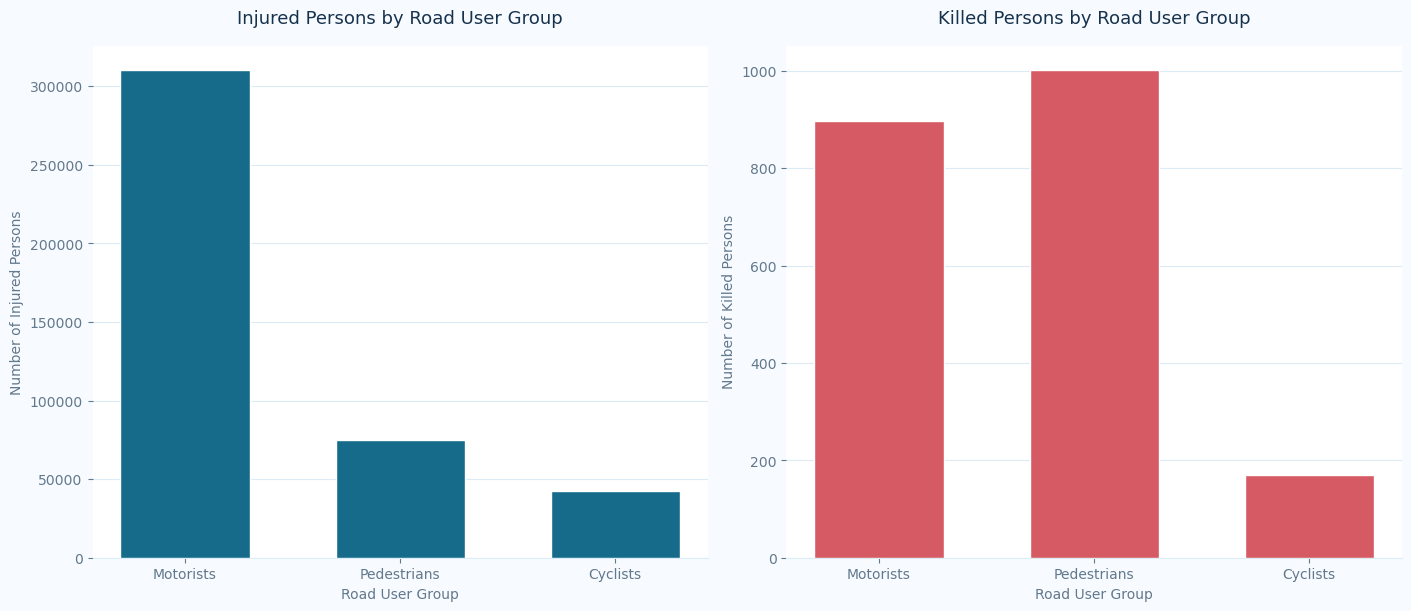

In [240]:
# ==========================================
# Q10: Injuries and Fatalities by Road User Group
# ==========================================

# Identify casualty columns
road_user_columns = [
    'NUMBER OF MOTORIST INJURED',
    'NUMBER OF PEDESTRIANS INJURED',
    'NUMBER OF CYCLIST INJURED',
    'NUMBER OF MOTORIST KILLED',
    'NUMBER OF PEDESTRIANS KILLED',
    'NUMBER OF CYCLIST KILLED'
]

# Convert casualty columns to numeric
road_user_data = crash_clean[
    road_user_columns
].apply(
    pd.to_numeric,
    errors='coerce'
).fillna(0)

# Calculate totals by road user group
road_user_summary = pd.DataFrame(
    {
        'Persons_Injured': [
            road_user_data['NUMBER OF MOTORIST INJURED'].sum(),
            road_user_data['NUMBER OF PEDESTRIANS INJURED'].sum(),
            road_user_data['NUMBER OF CYCLIST INJURED'].sum()
        ],
        'Persons_Killed': [
            road_user_data['NUMBER OF MOTORIST KILLED'].sum(),
            road_user_data['NUMBER OF PEDESTRIANS KILLED'].sum(),
            road_user_data['NUMBER OF CYCLIST KILLED'].sum()
        ]
    },
    index=['Motorists', 'Pedestrians', 'Cyclists']
)

# Display results
print("Injuries and Fatalities by Road User Group")

display(
    road_user_summary.style.format({
        'Persons_Injured': '{:,.0f}',
        'Persons_Killed': '{:,.0f}'
    })
)

# Create two charts
fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 6),
    constrained_layout=True
)

fig.patch.set_facecolor('#F7FBFF')

# Chart 1: Persons Injured
ax1 = axes[0]
ax1.set_facecolor('#FFFFFF')

ax1.bar(
    road_user_summary.index,
    road_user_summary['Persons_Injured'],
    color='#176B8A',
    edgecolor='white',
    width=0.6,
    zorder=3
)

ax1.set_title(
    'Injured Persons by Road User Group',
    color='#17324D',
    fontsize=13,
    pad=16
)

ax1.set_xlabel('Road User Group', color='#62788C')
ax1.set_ylabel('Number of Injured Persons', color='#62788C')

ax1.grid(axis='y', color='#DCECF6', zorder=0)
ax1.set_axisbelow(True)

ax1.spines[['top', 'right', 'left']].set_visible(False)
ax1.spines['bottom'].set_color('#DCECF6')
ax1.tick_params(colors='#62788C')

# Chart 2: Persons Killed
ax2 = axes[1]
ax2.set_facecolor('#FFFFFF')

ax2.bar(
    road_user_summary.index,
    road_user_summary['Persons_Killed'],
    color='#D65A64',
    edgecolor='white',
    width=0.6,
    zorder=3
)

ax2.set_title(
    'Killed Persons by Road User Group',
    color='#17324D',
    fontsize=13,
    pad=16
)

ax2.set_xlabel('Road User Group', color='#62788C')
ax2.set_ylabel('Number of Killed Persons', color='#62788C')

ax2.grid(axis='y', color='#DCECF6', zorder=0)
ax2.set_axisbelow(True)

ax2.spines[['top', 'right', 'left']].set_visible(False)
ax2.spines['bottom'].set_color('#DCECF6')
ax2.tick_params(colors='#62788C')

plt.show()

<div style="background: #FFFFFF; border-left: 5px solid #D65A64; border-radius: 12px; padding: 22px; margin: 18px 0;">
    <h3 style="color: #17324D; font-size: 20px; margin: 0 0 12px;">
        Key Insight
    </h3>
    <p style="color: #62788C; font-size: 15px; line-height: 1.8; margin: 0;">
        Motorists account for the largest number of injured persons (310,399), representing the majority of recorded injuries among the three road user groups. However, pedestrians record the highest number of fatalities (1,002), exceeding motorists (897) and cyclists (169). This highlights an important difference between injury and fatality outcomes: motorists experience the largest number of injuries, while pedestrians account for the largest number of deaths.
    </p>
</div>

<div style="background: #FFFFFF; border: 1px solid #DCECF6; border-left: 5px solid #2584A6; border-radius: 14px; padding: 22px 26px; margin: 20px 0;">
    <h3 style="color: #17324D; font-size: 19px; margin: 0 0 10px;">4.3 Correlation & Inferential Statistical Analysis</h3>
    <p style="color: #62788C; font-size: 15px; margin: 0; line-height: 1.8;">
        Correlation and inferential statistical methods were used to examine relationships between selected variables and test whether observed patterns are statistically significant. The analysis includes correlation analysis, hypothesis testing, and effect size measurements to support the findings with statistical evidence.
    </p>
</div>

<div style="background:#FFFFFF; border:1px solid #DCECF6; border-left:5px solid #2584A6; border-radius:14px; padding:22px 26px; margin:20px 0;">
    <h3 style="color:#17324D; font-size:18px; margin:0 0 10px;">4.3.1 Correlation Analysis</h3>
    <p style="color:#62788C; font-size:15px; margin:0; line-height:1.8;">
        Correlation analysis was conducted to examine the strength and direction of relationships between selected numerical variables. A correlation matrix and heatmap were used to identify patterns among collision variables. Spearman's rank correlation was also applied to investigate the relationship between daily crash volume and injury-crash percentage, including yearly comparisons.
    </p>
</div>

Records with valid crash hours: 1,000,000

Spearman Correlation Matrix


,Crash Hour,Number of Vehicles,Persons Injured,Persons Killed
Crash Hour,1.000,-0.001,0.052,-0.005
Number of Vehicles,-0.001,1.000,0.018,-0.019
Persons Injured,0.052,0.018,1.000,-0.006
Persons Killed,-0.005,-0.019,-0.006,1.000


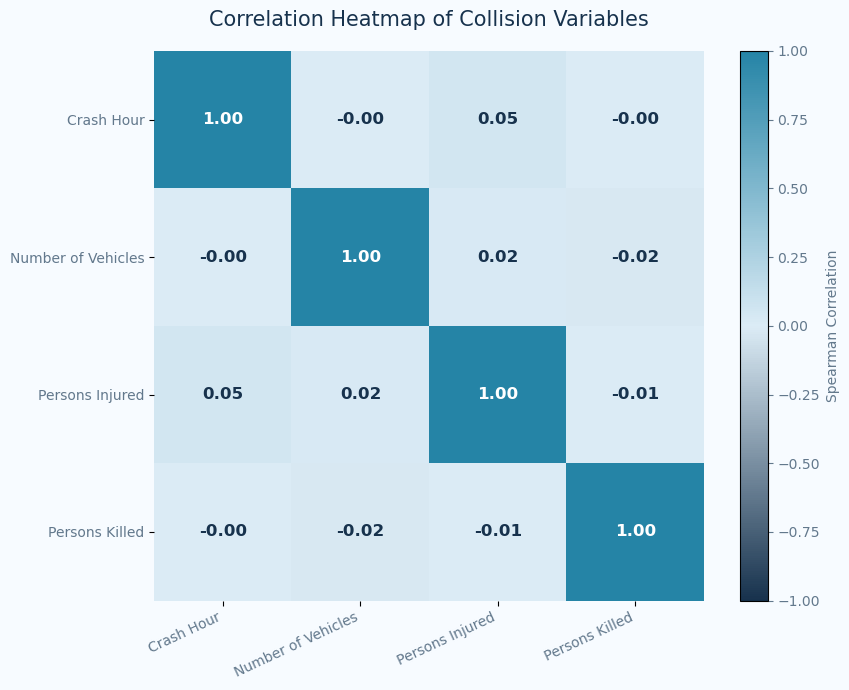

In [262]:
# ==========================================
# 4.3.1 Correlation Analysis
# ==========================================

from matplotlib.colors import LinearSegmentedColormap

# Create a working copy
correlation_data = crash_clean.copy()

# Convert casualty columns to numeric
casualty_columns = [
    'NUMBER OF PERSONS INJURED',
    'NUMBER OF PERSONS KILLED'
]

correlation_data[casualty_columns] = (
    correlation_data[casualty_columns]
    .apply(pd.to_numeric, errors='coerce')
    .fillna(0)
)

# Extract crash hour safely
def extract_hour(value):

    if pd.isna(value):
        return np.nan

    if hasattr(value, 'hour'):
        return value.hour

    parsed_time = pd.to_datetime(
        str(value),
        errors='coerce'
    )

    if pd.isna(parsed_time):
        return np.nan

    return parsed_time.hour


correlation_data['CRASH HOUR'] = (
    correlation_data['CRASH TIME']
    .apply(extract_hour)
)

# Count vehicles involved in each collision
vehicle_columns = [
    'VEHICLE TYPE CODE 1',
    'VEHICLE TYPE CODE 2',
    'VEHICLE TYPE CODE 3',
    'VEHICLE TYPE CODE 4',
    'VEHICLE TYPE CODE 5'
]

correlation_data['NUMBER OF VEHICLES'] = (
    correlation_data[vehicle_columns]
    .replace(r'^\s*$', np.nan, regex=True)
    .notna()
    .sum(axis=1)
)

# Select variables
selected_columns = {
    'CRASH HOUR': 'Crash Hour',
    'NUMBER OF VEHICLES': 'Number of Vehicles',
    'NUMBER OF PERSONS INJURED': 'Persons Injured',
    'NUMBER OF PERSONS KILLED': 'Persons Killed'
}

correlation_data = correlation_data[
    list(selected_columns.keys())
].rename(columns=selected_columns)

# Display valid crash time records
valid_hours = correlation_data['Crash Hour'].notna().sum()

print(f"Records with valid crash hours: {valid_hours:,}")

# Calculate Spearman correlation
correlation_matrix = correlation_data.corr(
    method='spearman'
)

# Display correlation matrix
print("\nSpearman Correlation Matrix")

display(
    correlation_matrix.style
    .format('{:.3f}')
    .background_gradient(
        cmap='GnBu',
        axis=None,
        vmin=-1,
        vmax=1
    )
)

# ==========================================
# Correlation Heatmap
# ==========================================

# Create custom color palette
custom_cmap = LinearSegmentedColormap.from_list(
    'NYC_Blue',
    [
        '#17324D',
        '#DCECF6',
        '#2584A6'
    ]
)

fig, ax = plt.subplots(figsize=(10, 7))

fig.patch.set_facecolor('#F7FBFF')
ax.set_facecolor('#FFFFFF')

# Plot heatmap
matrix_values = correlation_matrix.values

heatmap = ax.imshow(
    np.ma.masked_invalid(matrix_values),
    cmap=custom_cmap,
    vmin=-1,
    vmax=1
)

# Add correlation values
for i in range(len(correlation_matrix)):
    for j in range(len(correlation_matrix)):

        value = matrix_values[i, j]

        if np.isnan(value):
            label = 'N/A'
            text_color = '#62788C'
        else:
            label = f'{value:.2f}'

            if abs(value) >= 0.5:
                text_color = '#FFFFFF'
            else:
                text_color = '#17324D'

        ax.text(
            j,
            i,
            label,
            ha='center',
            va='center',
            color=text_color,
            fontsize=12,
            fontweight='bold'
        )

# Set axis labels
ax.set_xticks(range(len(correlation_matrix.columns)))
ax.set_yticks(range(len(correlation_matrix.index)))

ax.set_xticklabels(
    correlation_matrix.columns,
    rotation=25,
    ha='right',
    color='#62788C'
)

ax.set_yticklabels(
    correlation_matrix.index,
    color='#62788C'
)

# Chart title
ax.set_title(
    'Correlation Heatmap of Collision Variables',
    fontsize=15,
    color='#17324D',
    pad=18
)

# Color bar
colorbar = fig.colorbar(
    heatmap,
    ax=ax,
    fraction=0.046,
    pad=0.04
)

colorbar.set_label(
    'Spearman Correlation',
    color='#62788C'
)

colorbar.ax.tick_params(colors='#62788C')

# Remove unnecessary borders
for spine in ax.spines.values():
    spine.set_visible(False)

plt.tight_layout()
plt.show()

<div style="background: #FFFFFF; border: 1px solid #DCECF6; border-left: 5px solid #2584A6; border-radius: 14px; padding: 22px 26px; margin: 20px 0;">
    <h3 style="color: #17324D; font-size: 19px; margin: 0 0 10px;">Key Insight</h3>
    <p style="color: #62788C; font-size: 15px; margin: 0; line-height: 1.8;">
        The correlation analysis revealed very weak relationships among the selected variables. Crash Hour had the strongest positive correlation with Persons Injured (0.052), while Number of Vehicles showed a very weak positive correlation with Persons Injured (0.018) and a weak negative correlation with Persons Killed (-0.019). Overall, none of the selected variables showed a strong correlation with injury or fatality counts.
    </p>
</div>

<div style="background: #FFFFFF; border: 1px solid #DCECF6; border-left: 5px solid #2584A6; border-radius: 14px; padding: 22px 26px; margin: 20px 0;">
    <h3 style="color: #17324D; font-size: 18px; margin: 0 0 10px;">4.3.2 Hypothesis Testing</h3>
    <p style="color: #62788C; font-size: 15px; margin: 0; line-height: 1.8;">
        Hypothesis testing was used to examine whether the presence of injuries is statistically associated with the borough where a collision occurred. The Chi-Square Test of Independence was applied to compare injury and non-injury collisions across the five NYC boroughs.
    </p>
</div>

Injury Status by Borough


Injury_Status,No Injury,Injury,Total Crashes,Injury Percentage
BOROUGH,,,,
BRONX,"79,038","39,568","118,606",33.36%
BROOKLYN,"155,645","81,780","237,425",34.44%
MANHATTAN,"88,481","39,008","127,489",30.60%
QUEENS,"131,976","64,019","195,995",32.66%
STATEN ISLAND,"17,595","8,120","25,715",31.58%



Chi-Square Test Results
H0: Borough and injury status are independent.
H1: Borough and injury status are associated.

Chi-Square Statistic: 597.533
Degrees of Freedom: 4
P-value: 5.297599e-128
Cramer's V: 0.0291

Decision: Reject the Null Hypothesis (H0).
There is a statistically significant association.


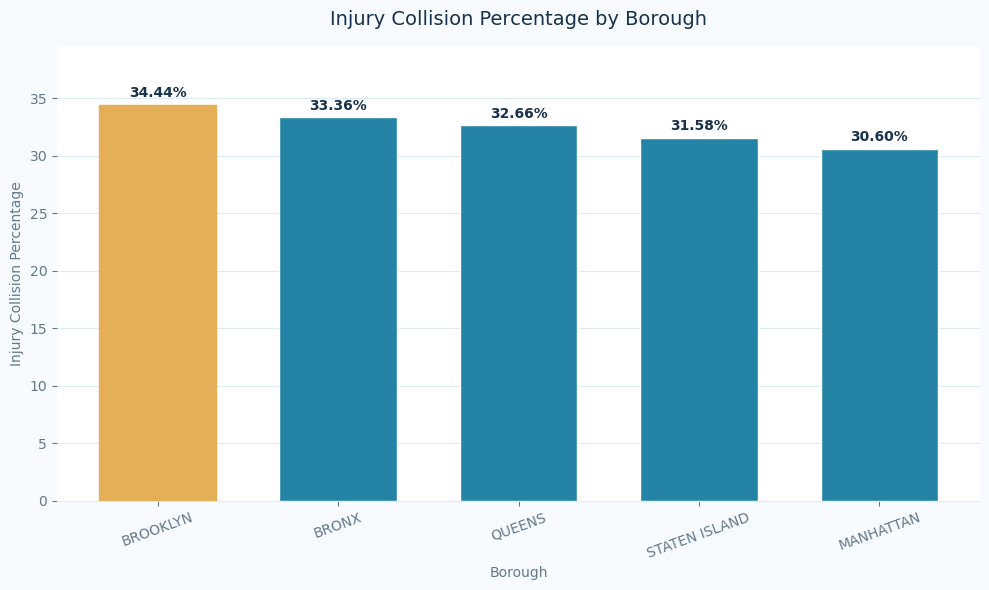

In [263]:
# ==========================================
# 4.3.2 Hypothesis Testing
# Chi-Square Test: Borough vs Injury Status
# ==========================================

from scipy.stats import chi2_contingency

# Create a working copy
test_data = crash_clean.copy()

# Standardize borough names
test_data['BOROUGH'] = (
    test_data['BOROUGH']
    .astype('string')
    .str.strip()
    .str.upper()
)

# Keep the five NYC boroughs
boroughs = [
    'BRONX',
    'BROOKLYN',
    'MANHATTAN',
    'QUEENS',
    'STATEN ISLAND'
]

test_data = test_data[
    test_data['BOROUGH'].isin(boroughs)
].copy()

# Convert injuries to numeric
test_data['NUMBER OF PERSONS INJURED'] = pd.to_numeric(
    test_data['NUMBER OF PERSONS INJURED'],
    errors='coerce'
).fillna(0)

# Create injury status
test_data['Injury_Status'] = np.where(
    test_data['NUMBER OF PERSONS INJURED'] > 0,
    'Injury',
    'No Injury'
)

# Create contingency table
contingency_table = pd.crosstab(
    test_data['BOROUGH'],
    test_data['Injury_Status']
)

# Ensure consistent column order
contingency_table = contingency_table[
    ['No Injury', 'Injury']
]

# Calculate injury percentages
borough_summary = contingency_table.copy()

borough_summary['Total Crashes'] = (
    borough_summary['No Injury'] +
    borough_summary['Injury']
)

borough_summary['Injury Percentage'] = (
    borough_summary['Injury'] /
    borough_summary['Total Crashes'] * 100
)

# Display results table
print("Injury Status by Borough")

display(
    borough_summary.style.format({
        'No Injury': '{:,.0f}',
        'Injury': '{:,.0f}',
        'Total Crashes': '{:,.0f}',
        'Injury Percentage': '{:.2f}%'
    })
)

# ==========================================
# Chi-Square Test of Independence
# ==========================================

chi2_stat, p_value, degrees_freedom, expected = (
    chi2_contingency(contingency_table)
)

# Calculate Cramer's V
total_records = contingency_table.to_numpy().sum()

minimum_dimension = min(contingency_table.shape) - 1

cramers_v = np.sqrt(
    chi2_stat /
    (total_records * minimum_dimension)
)

# Display hypotheses and test results
print("\nChi-Square Test Results")

print("H0: Borough and injury status are independent.")
print("H1: Borough and injury status are associated.")

print(f"\nChi-Square Statistic: {chi2_stat:,.3f}")
print(f"Degrees of Freedom: {degrees_freedom}")
print(f"P-value: {p_value:.6e}")
print(f"Cramer's V: {cramers_v:.4f}")

alpha = 0.05

if p_value < alpha:
    print("\nDecision: Reject the Null Hypothesis (H0).")
    print("There is a statistically significant association.")
else:
    print("\nDecision: Fail to Reject the Null Hypothesis (H0).")
    print("There is insufficient evidence of an association.")

# ==========================================
# Visualize Injury Percentages by Borough
# ==========================================

plot_data = borough_summary.sort_values(
    'Injury Percentage',
    ascending=False
)

fig, ax = plt.subplots(figsize=(10, 6))

fig.patch.set_facecolor('#F7FBFF')
ax.set_facecolor('#FFFFFF')

bars = ax.bar(
    plot_data.index,
    plot_data['Injury Percentage'],
    color='#2584A6',
    edgecolor='white',
    width=0.65,
    zorder=3
)

# Highlight the highest percentage
highest_index = plot_data['Injury Percentage'].idxmax()

for bar, borough in zip(bars, plot_data.index):
    if borough == highest_index:
        bar.set_color('#E4AF56')

# Add percentage labels
for bar in bars:
    height = bar.get_height()

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.4,
        f'{height:.2f}%',
        ha='center',
        va='bottom',
        color='#17324D',
        fontsize=10,
        fontweight='bold'
    )

ax.set_title(
    'Injury Collision Percentage by Borough',
    fontsize=14,
    color='#17324D',
    pad=16
)

ax.set_xlabel('Borough', color='#62788C')
ax.set_ylabel('Injury Collision Percentage', color='#62788C')

ax.tick_params(axis='x', rotation=20, colors='#62788C')
ax.tick_params(axis='y', colors='#62788C')

ax.grid(
    axis='y',
    color='#DCECF6',
    zorder=0
)

ax.set_axisbelow(True)

ax.spines[['top', 'right', 'left']].set_visible(False)
ax.spines['bottom'].set_color('#DCECF6')

ax.set_ylim(
    0,
    plot_data['Injury Percentage'].max() + 5
)

plt.tight_layout()
plt.show()

<div style="background:#FFFFFF; border:1px solid #DCECF6; border-left:5px solid #2584A6; border-radius:12px; padding:22px; margin:18px 0; color:#62788C; font-size:15px; line-height:1.8;">
    <h3 style="color:#17324D; font-size:22px; margin:0 0 18px;">Key Insight</h3>
    <p>
        The Chi-Square test revealed a statistically significant association between borough and injury involvement (χ² = 597.533, p < 0.001). Brooklyn recorded the highest injury-crash percentage (34.44%), while Manhattan recorded the lowest (30.60%), representing a difference of 3.84 percentage points. However, Cramér's V (0.0291) indicates a very weak association. Therefore, although injury involvement varies significantly across boroughs, the magnitude of this relationship is small.
    </p>
</div>

<div style="background:#FFFFFF; border:1px solid #DCECF6; border-left:5px solid #2584A6; border-radius:12px; padding:22px; margin:18px 0; color:#62788C; font-size:15px; line-height:1.8;">
    <h3 style="color:#17324D; font-size:22px; margin:0 0 18px;">Daily Crash Volume vs. Injury-Crash Percentage</h3>

   
<h4 style="color:#2584A6; font-size:18px;">Objective</h4>
    <p>Examine whether days with a higher number of recorded collisions also tend to have a higher percentage of collisions involving injuries.</p>

 <h4 style="color:#2584A6; font-size:18px;">Variables</h4>
    <p>Daily Crash Volume represents the number of recorded collisions per day. Injury-Crash Percentage represents the percentage of collisions with at least one injured person among records with known injury outcomes.</p>

  
<h4 style="color:#2584A6; font-size:18px;">Null Hypothesis — H0</h4>
    <p>There is no monotonic relationship between daily crash volume and injury-crash percentage.</p>

 <h4 style="color:#2584A6; font-size:18px;">Alternative Hypothesis — H1</h4>
    <p>There is a monotonic relationship between daily crash volume and injury-crash percentage.</p>

 <h4 style="color:#2584A6; font-size:18px;">Method and Assumptions</h4>
    <p>Use Spearman's rank correlation to measure the direction and strength of the relationship. Calculate the overall correlation and separate yearly correlations. Missing injury outcomes are excluded from the percentage denominator. A significance level of 0.05 is used.</p>
</div>

Overall Daily Correlation
Spearman Correlation: -0.5495
P-value: 4.951115e-240
Number of Days: 3,048

Yearly Correlation Results


,Year,Number of Days,Spearman Correlation,P-value
0,2018,181,-0.2130,3.992384e-03
1,2019,365,-0.1378,8.389827e-03
2,2020,366,-0.1015,5.229200e-02
3,2021,365,0.4472,2.389829e-19
4,2022,365,0.3034,3.298488e-09
5,2023,365,0.2375,4.488747e-06
6,2024,366,0.2332,6.553090e-06
7,2025,365,0.3360,4.427716e-11
8,2026,310,0.2031,3.197041e-04


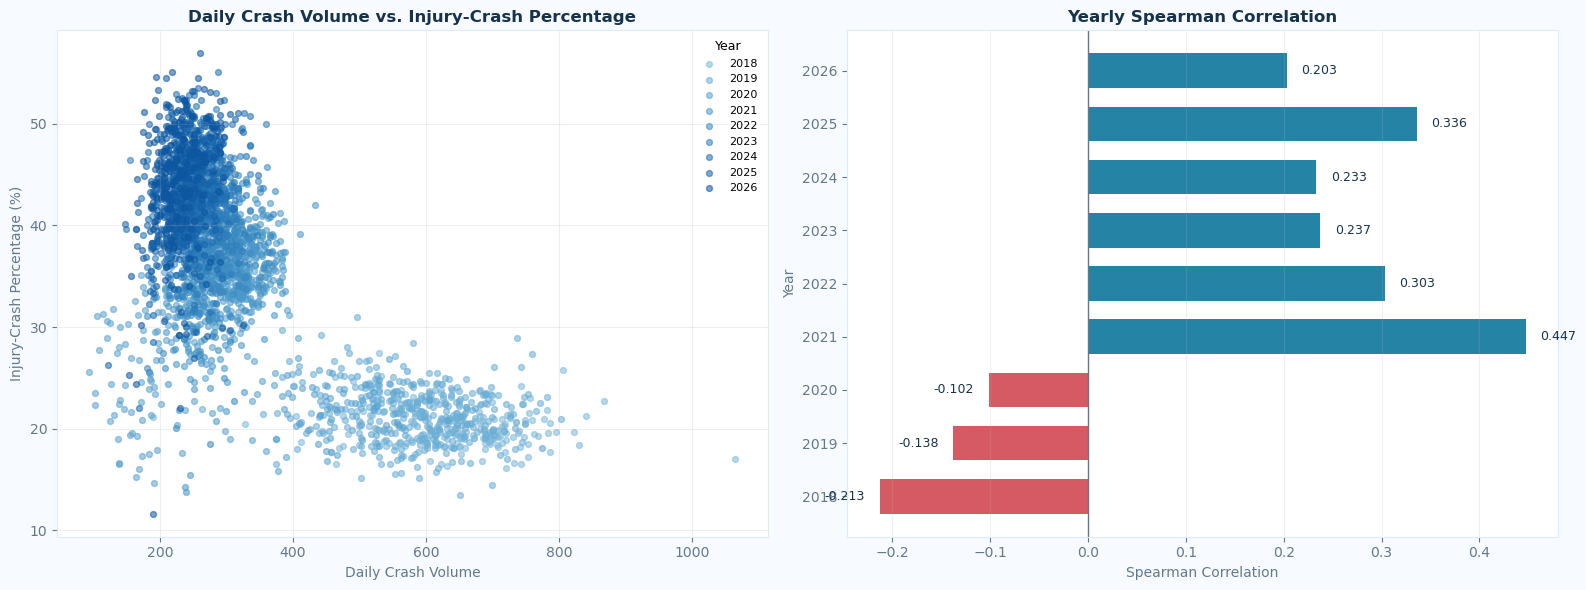

In [264]:
# 1. Prepare the data
daily_data = crash_clean[
    ['CRASH DATE', 'NUMBER OF PERSONS INJURED']
].copy()

daily_data['CRASH DATE'] = pd.to_datetime(
    daily_data['CRASH DATE'],
    errors='coerce'
).dt.normalize()

daily_data['NUMBER OF PERSONS INJURED'] = pd.to_numeric(
    daily_data['NUMBER OF PERSONS INJURED'],
    errors='coerce'
)

daily_data = daily_data.dropna(subset=['CRASH DATE'])

# 2. Identify injury involvement
daily_data['Has_Injury'] = np.where(
    daily_data['NUMBER OF PERSONS INJURED'].isna(),
    np.nan,
    (daily_data['NUMBER OF PERSONS INJURED'] > 0).astype(float)
)

# 3. Aggregate records by day
daily_summary = daily_data.groupby('CRASH DATE').agg(
    Daily_Crash_Volume=('CRASH DATE', 'size'),
    Known_Injury_Records=('Has_Injury', 'count'),
    Injury_Crashes=('Has_Injury', 'sum')
).reset_index()

# 4. Calculate daily injury-crash percentage
daily_summary['Injury_Crash_Percentage'] = (
    daily_summary['Injury_Crashes'] /
    daily_summary['Known_Injury_Records'] * 100
)

daily_summary['Year'] = daily_summary['CRASH DATE'].dt.year

# Keep days with known injury outcomes
daily_summary = daily_summary.dropna(
    subset=['Injury_Crash_Percentage']
)

# 5. Overall Spearman correlation
overall_result = spearmanr(
    daily_summary['Daily_Crash_Volume'],
    daily_summary['Injury_Crash_Percentage']
)

overall_rho = overall_result.statistic
overall_p = overall_result.pvalue

print("Overall Daily Correlation")
print(f"Spearman Correlation: {overall_rho:.4f}")
print(f"P-value: {overall_p:.6e}")
print(f"Number of Days: {len(daily_summary):,}")

# 6. Yearly correlation analysis
yearly_results = []

for year, group in daily_summary.groupby('Year'):

    if len(group) >= 2:
        result = spearmanr(
            group['Daily_Crash_Volume'],
            group['Injury_Crash_Percentage']
        )

        yearly_results.append({
            'Year': year,
            'Number of Days': len(group),
            'Spearman Correlation': result.statistic,
            'P-value': result.pvalue
        })

yearly_summary = pd.DataFrame(yearly_results)

print("\nYearly Correlation Results")

display(
    yearly_summary.style.format({
        'Number of Days': '{:,.0f}',
        'Spearman Correlation': '{:.4f}',
        'P-value': '{:.6e}'
    })
)

# 7. Plot both charts
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Chart 1: Daily crash volume vs injury percentage
years = sorted(daily_summary['Year'].unique())
palette = plt.cm.Blues(np.linspace(0.45, 0.85, len(years)))

for year, color in zip(years, palette):
    year_data = daily_summary[
        daily_summary['Year'] == year
    ]

    axes[0].scatter(
        year_data['Daily_Crash_Volume'],
        year_data['Injury_Crash_Percentage'],
        color=color,
        alpha=0.55,
        s=18,
        label=str(year)
    )

axes[0].set_title(
    'Daily Crash Volume vs. Injury-Crash Percentage',
    color='#17324D',
    fontsize=12,
    fontweight='bold'
)
axes[0].set_xlabel('Daily Crash Volume', color='#62788C')
axes[0].set_ylabel('Injury-Crash Percentage (%)', color='#62788C')
axes[0].grid(alpha=0.2)
axes[0].legend(
    title='Year',
    fontsize=8,
    title_fontsize=9,
    frameon=False
)

# Chart 2: Yearly Spearman correlations
bar_colors = [
    '#2584A6' if value >= 0 else '#D65A64'
    for value in yearly_summary['Spearman Correlation']
]

axes[1].barh(
    yearly_summary['Year'].astype(str),
    yearly_summary['Spearman Correlation'],
    color=bar_colors,
    height=0.65
)

axes[1].axvline(
    0,
    color='#62788C',
    linewidth=1
)

axes[1].set_title(
    'Yearly Spearman Correlation',
    color='#17324D',
    fontsize=12,
    fontweight='bold'
)
axes[1].set_xlabel('Spearman Correlation', color='#62788C')
axes[1].set_ylabel('Year', color='#62788C')
axes[1].grid(axis='x', alpha=0.2)

for index, value in enumerate(
    yearly_summary['Spearman Correlation']
):
    offset = 0.015 if value >= 0 else -0.015
    alignment = 'left' if value >= 0 else 'right'

    axes[1].text(
        value + offset,
        index,
        f'{value:.3f}',
        va='center',
        ha=alignment,
        color='#17324D',
        fontsize=9
    )

# 8. Final formatting
for ax in axes:
    ax.set_facecolor('#FFFFFF')
    ax.tick_params(colors='#62788C')
    for spine in ax.spines.values():
        spine.set_color('#DCECF6')

fig.patch.set_facecolor('#F7FBFF')

plt.tight_layout()
plt.show()

<div style="background:#FFFFFF; border:1px solid #DCECF6; border-left:5px solid #2584A6; border-radius:12px; padding:22px; margin:18px 0; color:#62788C; font-size:15px; line-height:1.8;">
    <h3 style="color:#17324D; font-size:19px; margin:0 0 10px;">Key Insight</h3>
    <p style="margin:0;">
        The overall analysis revealed a moderate negative correlation between daily crash volume and injury-crash percentage (Spearman's ρ = -0.5495, p < 0.001). However, the yearly results showed a clear change in the direction of this relationship. From 2018 to 2020, the correlations were negative and weak, while from 2021 to 2026, they became positive. The strongest positive correlation occurred in 2021 (ρ = 0.4472), whereas 2020 showed no statistically significant relationship (p = 0.0523). These findings suggest that the relationship between daily crash volume and injury-crash percentage varied across the study period. Therefore, the overall correlation should be interpreted alongside the yearly results.
    </p>
</div>

<div style="background:#FFFFFF; border:1px solid #DCECF6; border-left:5px solid #2584A6; border-radius:14px; padding:22px 26px; margin:20px 0; color:#62788C; font-size:15px; line-height:1.8;">
    <h3 style="color:#17324D; font-size:18px; margin:0 0 14px;">Test 3. Is injury involvement associated with the day of the week?</h3>

 <h4 style="color:#2584A6; font-size:16px;">Objective</h4>
    <p>Examine whether the proportion of collisions involving injuries differs across the seven days of the week.</p>

<h4 style="color:#2584A6; font-size:16px;">Variables</h4>
    <p>Day of the Week is a categorical variable with seven groups. Injury Involvement is a binary categorical variable indicating whether at least one person was injured in a collision.</p>

<h4 style="color:#2584A6; font-size:16px;">Null Hypothesis — H0</h4>
    <p>Day of the week and injury involvement are independent. The injury-crash proportion is equal across all days.</p>

<h4 style="color:#2584A6; font-size:16px;">Alternative Hypothesis — H1</h4>
    <p>Day of the week and injury involvement are associated. At least one day has a different injury-crash proportion.</p>

<h4 style="color:#2584A6; font-size:16px;">Method and Assumptions</h4>
    <p>Apply the Chi-Square Test of Independence and calculate Cramér's V to measure the strength of the association. Exclude records with missing dates or unknown injury outcomes. Each collision contributes to one category. Use a significance level of 0.05.</p>
</div>

Injury Status by Day of the Week


Injury_Status,No Injury,Injury,Total Crashes,Injury Percentage
Day_Name,,,,
Monday,"95,526","46,030","141,556",32.52%
Tuesday,"96,445","47,713","144,158",33.10%
Wednesday,"95,902","47,940","143,842",33.33%
Thursday,"99,721","48,680","148,401",32.80%
Friday,"106,070","51,777","157,847",32.80%
Saturday,"92,951","45,464","138,415",32.85%
Sunday,"84,278","41,500","125,778",32.99%



Chi-Square Test Results
Chi-Square Statistic: 25.856
Degrees of Freedom: 6
P-value: 2.367897e-04
Cramer's V: 0.0051
Decision: Reject H0
There is a statistically significant association.

Minimum Expected Frequency: 41394.17


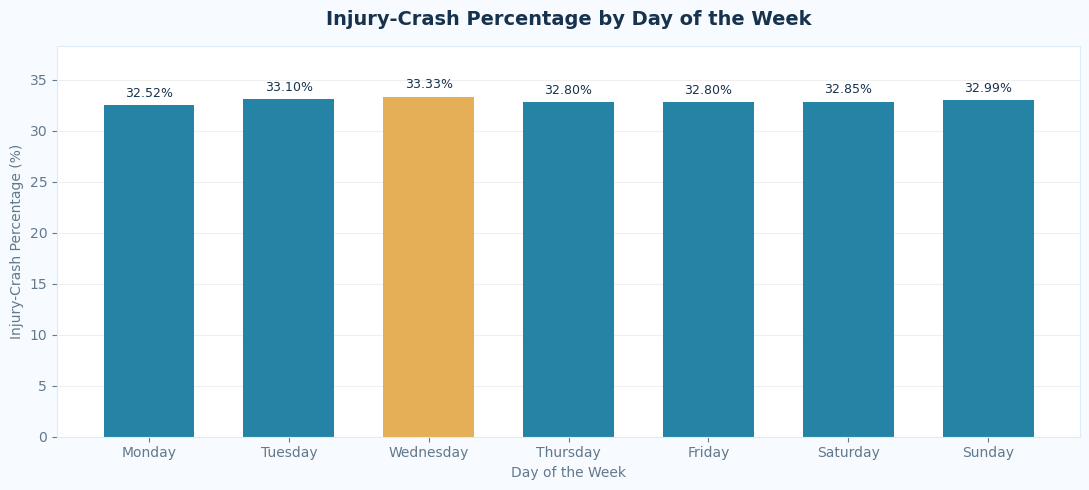

In [267]:
# 1. Prepare the data
test_data = crash_clean[
    ['CRASH DATE', 'NUMBER OF PERSONS INJURED']
].copy()

test_data['CRASH DATE'] = pd.to_datetime(
    test_data['CRASH DATE'],
    errors='coerce'
)

test_data['NUMBER OF PERSONS INJURED'] = pd.to_numeric(
    test_data['NUMBER OF PERSONS INJURED'],
    errors='coerce'
)

# 2. Keep records with known dates and injury outcomes
test_data = test_data.dropna(
    subset=['CRASH DATE', 'NUMBER OF PERSONS INJURED']
).copy()

# 3. Create weekday and injury status
test_data['Day_Name'] = test_data['CRASH DATE'].dt.day_name()

test_data['Injury_Status'] = np.where(
    test_data['NUMBER OF PERSONS INJURED'] > 0,
    'Injury',
    'No Injury'
)

day_order = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

# 4. Create contingency table
contingency_table = pd.crosstab(
    test_data['Day_Name'],
    test_data['Injury_Status']
).reindex(day_order)

contingency_table = contingency_table[
    ['No Injury', 'Injury']
]

# 5. Calculate injury percentages
weekday_summary = contingency_table.copy()

weekday_summary['Total Crashes'] = (
    weekday_summary['No Injury'] +
    weekday_summary['Injury']
)

weekday_summary['Injury Percentage'] = (
    weekday_summary['Injury'] /
    weekday_summary['Total Crashes'] * 100
)

print("Injury Status by Day of the Week")

display(
    weekday_summary.style.format({
        'No Injury': '{:,.0f}',
        'Injury': '{:,.0f}',
        'Total Crashes': '{:,.0f}',
        'Injury Percentage': '{:.2f}%'
    })
)

# 6. Chi-Square Test of Independence
chi2_stat, p_value, degrees_freedom, expected = (
    chi2_contingency(contingency_table)
)

total_records = contingency_table.to_numpy().sum()
minimum_dimension = min(contingency_table.shape) - 1

cramers_v = np.sqrt(
    chi2_stat / (total_records * minimum_dimension)
)

alpha = 0.05

print("\nChi-Square Test Results")
print(f"Chi-Square Statistic: {chi2_stat:,.3f}")
print(f"Degrees of Freedom: {degrees_freedom}")
print(f"P-value: {p_value:.6e}")
print(f"Cramer's V: {cramers_v:.4f}")

if p_value < alpha:
    print("Decision: Reject H0")
    print("There is a statistically significant association.")
else:
    print("Decision: Fail to reject H0")
    print("There is no statistically significant association.")

# 7. Check expected frequencies
print(
    f"\nMinimum Expected Frequency: {expected.min():.2f}"
)

# 8. Plot injury-crash percentage by weekday
plot_data = weekday_summary.reset_index()

highest_day = plot_data['Injury Percentage'].idxmax()

bar_colors = [
    '#E4AF56' if i == highest_day else '#2584A6'
    for i in range(len(plot_data))
]

fig, ax = plt.subplots(figsize=(11, 5))

bars = ax.bar(
    plot_data['Day_Name'],
    plot_data['Injury Percentage'],
    color=bar_colors,
    width=0.65
)

ax.set_title(
    'Injury-Crash Percentage by Day of the Week',
    color='#17324D',
    fontsize=14,
    fontweight='bold',
    pad=15
)

ax.set_xlabel('Day of the Week', color='#62788C')
ax.set_ylabel('Injury-Crash Percentage (%)', color='#62788C')

ax.bar_label(
    bars,
    fmt='%.2f%%',
    padding=4,
    fontsize=9,
    color='#17324D'
)

ax.set_ylim(
    0,
    plot_data['Injury Percentage'].max() * 1.15
)

ax.set_facecolor('#FFFFFF')
fig.patch.set_facecolor('#F7FBFF')
ax.grid(axis='y', alpha=0.2)

ax.set_axisbelow(True)

for spine in ax.spines.values():
    spine.set_color('#DCECF6')

ax.tick_params(colors='#62788C')

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

<div style="background:#FFFFFF; border:1px solid #DCECF6; border-left:5px solid #2584A6; border-radius:14px; padding:22px 26px; margin:20px 0;">
    <h3 style="color:#17324D; font-size:18px; margin:0 0 10px;">4.3.3 Statistical Findings</h3>
    <p style="color:#62788C; font-size:15px; margin:0; line-height:1.8;">
        This section summarizes the main findings from the correlation analysis and hypothesis tests. The results highlight relationships between collision characteristics, injury involvement, and the timing and location of collisions. Statistical significance and effect sizes are considered together to distinguish meaningful patterns from relationships that are statistically significant but weak.
    </p>
</div>

<div style="background: linear-gradient(120deg, #FFFFFF, #DCECF6); border: 1px solid #DCECF6; border-left: 6px solid #17324D; border-radius: 16px; padding: 26px 30px; margin: 20px 0;">

<h2 style="color: #17324D; font-size: 25px; margin: 0 0 14px;">4.3.4 Overall Statistical Conclusion</h2>

<p style="color: #62788C; font-size: 15px; line-height: 1.8;">
The statistical analysis examined relationships between collision characteristics, injury involvement, and temporal patterns using correlation analysis and hypothesis testing.
</p>

<div style="background: #FFFFFF; border-radius: 12px; padding: 16px 20px; margin: 12px 0;">
<h3 style="color: #2584A6; margin: 0 0 8px;">1. Correlation Analysis</h3>
<p style="color: #17324D; margin: 0; line-height: 1.8;">
The selected numerical variables showed very weak correlations. The strongest observed correlation was between Crash Hour and Persons Injured (ρ = 0.052), indicating limited monotonic relationships among these variables.
</p>
</div>

<div style="background: #FFFFFF; border-radius: 12px; padding: 16px 20px; margin: 12px 0;">
<h3 style="color: #2584A6; margin: 0 0 8px;">2. Daily Crash Volume and Injury-Crash Percentage</h3>
<p style="color: #17324D; margin: 0; line-height: 1.8;">
The overall Spearman correlation was negative (ρ = -0.5495, p < 0.001). However, yearly results showed negative correlations from 2018 to 2020 and positive correlations from 2021 to 2026, indicating changes in the relationship over time.
</p>
</div>

<div style="background: #FFFFFF; border-radius: 12px; padding: 16px 20px; margin: 12px 0;">
<h3 style="color: #2584A6; margin: 0 0 8px;">3. Borough and Injury Involvement</h3>
<p style="color: #17324D; margin: 0; line-height: 1.8;">
A statistically significant association was identified between borough and injury involvement (χ² = 597.533, p < 0.001). However, Cramér's V (0.0291) indicated a very weak association. Brooklyn recorded the highest injury-crash percentage (34.44%), while Manhattan recorded the lowest (30.60%).
</p>
</div>

<div style="background: #FFFFFF; border-radius: 12px; padding: 16px 20px; margin: 12px 0;">
<h3 style="color: #2584A6; margin: 0 0 8px;">4. Day of the Week and Injury Involvement</h3>
<p style="color: #17324D; margin: 0; line-height: 1.8;">
[Insert the Chi-Square result, p-value, Cramér's V, and the observed differences in injury-crash percentages after completing the test.]
</p>
</div>

<div style="background: #DCECF6; border-left: 5px solid #E4AF56; border-radius: 12px; padding: 18px 20px; margin-top: 20px;">
<h3 style="color: #17324D; margin: 0 0 8px;">Overall Assessment</h3>
<p style="color: #17324D; margin: 0; line-height: 1.8;">
The analysis revealed variations in injury involvement across boroughs and over time. Some relationships were statistically significant, but their strength differed. These findings show the importance of considering both statistical significance and effect size when interpreting collision patterns.
</p>
</div>

</div>